<a href="https://colab.research.google.com/github/mdelgiudicechaves-art/MVP-Margem-de-Contribui-o---Trabalho-PSP8/blob/main/MVP_Margem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP — Margem de projetos: o que explica as diferenças e onde proteger a margem

**Autora:** Marina del Giudice Chaves  
**Disciplina:** PSP8 — Departamento de Engenharia de Produção, Universidade de Brasília (UnB)  
**Professor:** André Luiz Marques Serrano  
**Produto:** pipeline de dados em nuvem (Google Colab + Google Drive), arquitetura medalhão (Bronze → Silver → Gold) com modelo dimensional em esquema estrela  
**Base:** *MVP Margem – Uso Público* (planilha gerencial de uma empresa de serviços profissionais organizada por projetos; nomes de projetos substituídos por letras e rótulos anonimizados)

> Este notebook é autossuficiente: ao executá-lo no Colab, ele lê a planilha, constrói as três camadas, carrega o modelo estrela em um banco analítico (DuckDB) persistido no Google Drive, gera o Catálogo de Dados, responde às perguntas de negócio e exporta o relatório e as evidências.

## 1. Objetivo, problema e perguntas de negócio

**Problema.** A empresa acompanha a margem de seus projetos em uma planilha com várias abas e cenários, mas não sabe *quais características do projeto realmente explicam* por que alguns projetos têm margem alta e outros margem negativa. Sem isso, a originação (quais projetos buscar e a que preço) e a alocação de equipe (quem, com que intensidade) são decididas por intuição.

**Pergunta direcionadora.**
> **Quais características dos projetos de 2026 (área, escopo, tipo de contrato, valor, prazo e composição da equipe alocada) mais explicam as diferenças de margem entre eles, e o que isso indica sobre quais projetos priorizar na originação e como alocar equipe para proteger a margem?**

**Perguntas de apoio.**
1. **Onde a margem se concentra?** Quais áreas, escopos e tipos de contrato respondem pela maior parte da margem em R$, e quais ficam abaixo da média ou negativos? *(agregações por dimensão e curva de Pareto)*
2. **A equipe explica a margem?** Como a composição da equipe (cargos e % de alocação) e o custo de pessoal sobre a receita se relacionam com a margem, e a partir de que nível o projeto passa a ter margem negativa?
3. **Prazo e modelo de receita mexem na margem?** Projetos que estouram o prazo (meses executados contra planejados) ou dependem de *success fee* têm margem menor ou mais volátil que os pontuais e recorrentes?

**Decisão apoiada.** (i) Quais perfis de projeto priorizar na originação e com qual *preço-piso* mensal; (ii) qual intensidade de equipe um projeto comporta sem destruir a margem; (iii) quais projetos ativos hoje exigem renegociação ou reforço de controle.

**Hipóteses (declaradas antes da análise, podem ser refutadas).**
| # | Hipótese | Como será testada |
|---|---|---|
| H1 | A margem é concentrada: poucos projetos geram a maior parte da margem positiva | Curva de Pareto, índice de Gini |
| H2 | O tipo de contrato/modelo de receita explica mais a margem do que o escopo | Teste de Kruskal-Wallis, ε² e importância por grupo de variáveis |
| H3 | Intensidade de equipe (custo de pessoal / receita) é o principal determinante do sinal da margem | Ponto de equilíbrio e correlação de Spearman |
| H4 | Estouro de prazo e dependência de *success fee* reduzem e tornam a margem mais volátil | Mann-Whitney, volatilidade da margem mensal |

**As três dimensões do MVP.**
| Dimensão | Pergunta | Evidência neste trabalho |
|---|---|---|
| Viabilidade técnica | Dá para construir com a tecnologia disponível? | Pipeline ponta a ponta em Colab + Drive (gratuito), reexecutável |
| Viabilidade financeira | É economicamente sustentável? | Custo de operação ≈ zero (ferramentas gratuitas); ver seção 12 |
| Desejabilidade | É o que o usuário precisa? | Respostas acionáveis: segmentos prioritários, preço-piso e lista de projetos em alerta |

*Regra de ouro do enunciado:* as perguntas permanecem íntegras mesmo que alguma não seja respondida; a seção de autoavaliação discute o atingimento.

## 2. Plataforma, arquitetura e licenciamento

* **Plataforma:** Google Colab (processamento) + Google Drive (persistência em nuvem). Os dados ficam persistidos como arquivos **Parquet** por camada e em um banco analítico **DuckDB** (`.duckdb`) no Drive; as consultas SQL da camada Gold rodam nele.
* **Linhagem:** `planilha .xlsx` → **Bronze** (cópia fiel em texto, com metadados de ingestão) → **Silver** (tipagem, limpeza, regras de negócio numeradas, recálculo da margem) → **Gold** (esquema estrela + *mart* analítico) → **Análises/Relatório**.
* **Por que recalcular a margem?** A planilha traz dois cenários de margem calculados por fórmulas. Na auditoria (seção 4) o cenário 2 tem referências quebradas (`#REF!`) e a coluna de projetos ativos depende de `TODAY()`. Por isso o pipeline **recalcula a margem a partir de insumos primários** (receita mensal, custo de equipe e parâmetros) e usa as abas calculadas apenas para **reconciliação**.
* **Licença e ética:** os dados são **proprietários e internos**, anonimizados e usados com finalidade acadêmica mediante autorização da empresa (registrar a autorização no repositório). Por isso: (i) a planilha original **não é versionada** no GitHub — somente código, catálogo e resultados descaracterizados; (ii) colunas sensíveis (nomes de operações, códigos internos, componentes de remuneração individual) **não avançam além da Bronze privada**; (iii) em `MODO = "publico"` todos os valores em R$ são multiplicados por um **fator privado** (margens percentuais, proporções e rankings não mudam). Não há dados pessoais diretos; salários por cargo são usados apenas para calcular custo alocado e não são expostos.

## 3. Configuração do ambiente

In [ ]:
import os, sys, json, re, hashlib, warnings, datetime as dt, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

try:
    import duckdb
except ImportError:
    get_ipython().run_line_magic("pip", "install -q duckdb")
    import duckdb
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
except ImportError:
    get_ipython().run_line_magic("pip", "install -q statsmodels")
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import RepeatedKFold, cross_val_score
pd.set_option("display.width", 200, "display.max_columns", 60, "display.max_colwidth", 80)

# ---------------- PARÂMETROS DO PROJETO (única célula que o usuário precisa ajustar) ----------------
MODO = "publico"                       # "publico": valores em R$ descaracterizados | "interno": valores reais (uso privado)
NOME_ARQUIVO = "MVP Margem - Uso Público.xlsx"
DATA_CORTE = pd.Timestamp("2026-11-17")  # substitui TODAY() da planilha => resultado reprodutível
ANO = 2026
JANELA_INI, JANELA_FIM = 3, 10          # meses com custo de equipe observado (mar–out/2026)
MARGEM_ALVO = 0.30                      # margem plena-alvo usada no preço-piso e nos alertas
MIN_GRUPO = 5                           # grupos com menos projetos que isso são agrupados em "Outros"
TOL_PRAZO_MESES = 0.5                   # tolerância para considerar que o prazo estourou
SEMENTE = 42
# --------------------------------------------------------------------------------------------------

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/MVP_Margem")
else:
    BASE = Path(os.environ.get("MVP_BASE", "./MVP_Margem"))
PASTAS = {k: BASE / k for k in ["entrada", "bronze", "silver", "gold", "catalogo", "evidencias", "relatorio", "meta"]}
for p in PASTAS.values():
    p.mkdir(parents=True, exist_ok=True)

XLSX = Path(os.environ.get("MVP_XLSX", PASTAS["entrada"] / NOME_ARQUIVO))
if not XLSX.exists():
    if EM_COLAB:
        print(f"Arquivo não encontrado em {XLSX}. Envie a planilha '{NOME_ARQUIVO}':")
        from google.colab import files
        up = files.upload()
        nome = next(iter(up))
        XLSX = PASTAS["entrada"] / NOME_ARQUIVO
        XLSX.write_bytes(up[nome])
    else:
        raise FileNotFoundError(f"Coloque a planilha em {XLSX}")

# Fator de descaracterização (privado, fica só no Drive; nunca vai para o repositório)
CFG_PRIV = BASE / "config_privada.json"
if MODO == "interno":
    FATOR = 1.0
else:
    if CFG_PRIV.exists():
        FATOR = float(json.loads(CFG_PRIV.read_text())["fator_escala"])
    else:
        FATOR = float(np.round(np.random.default_rng().uniform(0.55, 1.85), 4))
        CFG_PRIV.write_text(json.dumps({"fator_escala": FATOR}))
print(f"Ambiente: {'Colab' if EM_COLAB else 'local'} | modo: {MODO} | base: {BASE}")
print("Valores em R$ descaracterizados (fator privado aplicado)." if MODO == "publico" else "ATENÇÃO: valores reais — não publique saídas deste modo.")

LOG = []      # trilha de linhagem/auditoria do pipeline
DQ = []       # resultados de qualidade de dados
def registrar(camada, etapa, tabela, n_in, n_out, regra):
    LOG.append(dict(ts=dt.datetime.now().isoformat(timespec="seconds"), camada=camada, etapa=etapa,
                    tabela=tabela, linhas_entrada=n_in, linhas_saida=n_out, regra=regra))
def dq(dimensao, tabela, atributo, verificacao, afetados, total, severidade, tratamento):
    DQ.append(dict(dimensao=dimensao, tabela=tabela, atributo=atributo, verificacao=verificacao,
                   afetados=int(afetados), total=int(total),
                   pct=round(100 * afetados / total, 1) if total else np.nan,
                   severidade=severidade, tratamento=tratamento))

# Estilo gráfico (paleta categórica validada; um único eixo; grade discreta)
AZUL, LARANJA, VERDE, VIOLETA, CINZA, VERMELHO = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#8d8c86", "#e34948"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
                     "font.size": 9.5, "legend.frameon": False})
FIG = []
def salvar_fig(nome, titulo):
    caminho = PASTAS["evidencias"] / f"{nome}.png"
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    FIG.append(dict(arquivo=caminho.name, titulo=titulo))
def brl(x, casas=0):
    s = f"R$ {abs(x):,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return "-" + s if x < 0 else s
def fnum(x, c=2):
    return "—" if pd.isna(x) else f"{x:.{c}f}".replace(".", ",")
def pct(x, casas=1):
    return "—" if pd.isna(x) else f"{100 * x:.{casas}f}%".replace(".", ",")

Mounted at /content/drive
Arquivo não encontrado em /content/drive/MyDrive/MVP_Margem/entrada/MVP Margem - Uso Público.xlsx. Envie a planilha 'MVP Margem - Uso Público.xlsx':


Saving MVP Margem - Uso Público.xlsx to MVP Margem - Uso Público.xlsx
Ambiente: Colab | modo: publico | base: /content/drive/MyDrive/MVP_Margem
Valores em R$ descaracterizados (fator privado aplicado).


## 4. Coleta e camada Bronze

A Bronze é uma **cópia fiel, em texto** (schema-on-read), de cada aba da planilha, acrescida de metadados de ingestão (`_arquivo`, `_aba`, `_linha_origem`, `_dt_ingestao`, `_sha256`). Nenhuma regra de negócio é aplicada aqui, com **uma exceção de segurança**: a coluna *Operação do Projeto* contém textos que identificam operações reais e é **descartada na ingestão** (apenas o percentual de preenchimento é registrado para a auditoria).

In [ ]:
t0 = dt.datetime.now()
sha = hashlib.sha256(XLSX.read_bytes()).hexdigest()
abas = pd.read_excel(XLSX, sheet_name=None, header=None, dtype=object)
COLETA = dict(arquivo=NOME_ARQUIVO, formato=XLSX.suffix, bytes=XLSX.stat().st_size, sha256=sha,
              data_coleta=DATA_CORTE.date().isoformat(), abas=len(abas),
              linhas_por_aba={k: int(v.dropna(how="all").shape[0]) for k, v in abas.items()})
display(pd.DataFrame({"aba": list(COLETA["linhas_por_aba"]), "linhas_nao_vazias": list(COLETA["linhas_por_aba"].values()),
                      "colunas": [abas[k].shape[1] for k in COLETA["linhas_por_aba"]]}))
print({k: v for k, v in COLETA.items() if k != "linhas_por_aba"})

# metadados do arquivo: auditoria sem expor o conteúdo
import openpyxl
_wb = openpyxl.load_workbook(XLSX, read_only=True)
META_PREENCHIDOS = [c for c in ("creator", "lastModifiedBy", "title", "subject", "description", "keywords", "category")
                    if getattr(_wb.properties, c, None)]
_wb.close()

def para_texto(df):
    return df.astype("string")

def gravar_bronze(nome, df, aba):
    df = df.copy()
    df.columns = [str(c).strip() if c is not None and str(c) != "nan" else f"col_{i}" for i, c in enumerate(df.columns)]
    df = para_texto(df)
    df["_arquivo"], df["_aba"] = NOME_ARQUIVO, aba
    df["_linha_origem"] = np.arange(2, len(df) + 2) if aba in ("Projetos", "Custos de Projeto") else np.arange(1, len(df) + 1)
    df["_dt_ingestao"], df["_sha256"] = t0.isoformat(timespec="seconds"), sha
    df.to_parquet(PASTAS["bronze"] / f"{nome}.parquet", index=False)
    registrar("bronze", "ingestao", nome, len(abas[aba]), len(df), f"Cópia fiel em texto da aba '{aba}' (sem regras de negócio)")
    return df

# Projetos e Custos: primeira linha é cabeçalho
g = abas["Projetos"]; cab = [str(c) for c in g.iloc[0, :19]]
proj_raw = g.iloc[1:, :19].copy(); proj_raw.columns = cab; proj_raw = proj_raw.dropna(how="all")
g = abas["Custos de Projeto"]; cab = [str(c) for c in g.iloc[0, :12]]
cus_raw = g.iloc[1:, :12].copy(); cus_raw.columns = cab; cus_raw = cus_raw.dropna(how="all")
OPERACAO_PREENCHIDA = int(cus_raw["Operação do Projeto"].notna().sum())
cus_raw = cus_raw.drop(columns=["Operação do Projeto"])        # descarte de coluna sensível na ingestão

b_proj = gravar_bronze("bronze_projetos", proj_raw, "Projetos")
b_cus = gravar_bronze("bronze_custos", cus_raw, "Custos de Projeto")
# Abas largas (cenários mensais, parâmetros e margens calculadas pela planilha): grade bruta
GRADES = {"bronze_receita_cen1": "1 Mensal", "bronze_receita_cen2": "2 Mensal", "bronze_parametros": "Parâmetros",
          "bronze_margem_pct_cen1": "1 Margem (%)", "bronze_margem_pct_cen2": "2 Margem (%)"}
bronze = {"bronze_projetos": b_proj, "bronze_custos": b_cus}
for nome, aba in GRADES.items():
    gr = abas[aba].dropna(how="all").dropna(axis=1, how="all")
    gr.columns = [f"c{i}" for i in range(gr.shape[1])]
    bronze[nome] = gravar_bronze(nome, gr, aba)
# Persistência comprovada: a Silver lê de volta da Bronze gravada no Drive
bronze = {n: pd.read_parquet(PASTAS["bronze"] / f"{n}.parquet") for n in bronze}
display(pd.DataFrame([(n, len(d), d.shape[1]) for n, d in bronze.items()], columns=["tabela_bronze", "linhas", "colunas"]))

,aba,linhas_nao_vazias,colunas
0,Projetos,99,34
1,Custos de Projeto,1092,12
2,Parâmetros,23,15
3,1 Mensal,1001,26
4,1 Margem (R$),999,19
5,1 Margem (R$) Acumulada,999,19
6,1 Margem (%),999,20
7,1 Margem Acumulada,999,20
8,2 Mensal,1001,25
9,2 Margem (R$),999,19


{'arquivo': 'MVP Margem - Uso Público.xlsx', 'formato': '.xlsx', 'bytes': 1717238, 'sha256': '39bad6ea0bd35a79ecae74a21de0097f4b3fba9d98fe49c5f4ff411434b3a9d6', 'data_coleta': '2026-11-17', 'abas': 13}


,tabela_bronze,linhas,colunas
0,bronze_projetos,98,24
1,bronze_custos,1091,16
2,bronze_receita_cen1,1001,31
3,bronze_receita_cen2,1001,30
4,bronze_parametros,23,20
5,bronze_margem_pct_cen1,999,25
6,bronze_margem_pct_cen2,999,25


## 5. Qualidade de dados (diagnóstico sobre a Bronze)

Cada atributo é examinado nas dimensões do enunciado: **completude, unicidade, consistência, conformidade, acurácia e atualidade**, mais a **reconciliação** com as abas calculadas pela planilha. Cada problema recebe severidade e um tratamento explícito (aplicado na Silver). Valores absolutos em R$ não são exibidos aqui; só contagens e proporções.

In [ ]:
def num(s): return pd.to_numeric(s, errors="coerce").astype("float64")
def to_date(s):
    ok = s.astype("string").str.match(r"^\d{4}-\d{2}-\d{2}")
    return pd.to_datetime(s.where(ok), errors="coerce")

REN_PROJ = {"Nome do Projeto": "projeto", "Escopo": "escopo", "Etapa / Tipo": "etapa_tipo", "Área": "area", "Status": "status",
            "Valor do Contrato (R$)": "valor_contrato", "Valor mensal contrato": "valor_mensal_contrato",
            "Success Fee": "success_fee_bruto", "Receita final de Success Fee (-45%)": "receita_sf_liquida",
            "Data Competência Sucess Fee": "dt_competencia_sf", "Valor mensal executado": "valor_mensal_executado",
            "Data de Início Contrato": "dt_inicio", "Data de Fim Contrato": "dt_fim_contrato", "Data Fim Real": "dt_fim_real",
            "Data Atual": "dt_atual_planilha", "Meses Planejado": "meses_planejado_planilha",
            "Meses Executado": "meses_executado_planilha", "Mês Atual": "mes_atual_planilha", "Prazo em Contrato (dias)": "prazo_dias"}
REN_CUS = {"Código do Projeto": "codigo_projeto", "Nome do Projeto": "projeto", "Área do Projeto": "area_projeto", "Cargo": "cargo",
           "Área do Cargo": "area_cargo", "Salário": "salario", "Benefícios": "beneficios", "Bônus": "bonus",
           "% de alocação por pessoa": "aloc_pct", "Total Remuneração* Alocação": "custo_planilha", "Mês": "mes_raw"}

def tipar_proj(b):
    d = b.rename(columns=REN_PROJ)[list(REN_PROJ.values())].copy()
    d = d[d["projeto"].notna()].copy()
    d["projeto"] = d["projeto"].str.strip()
    for c in ["valor_contrato", "valor_mensal_contrato", "success_fee_bruto", "receita_sf_liquida", "valor_mensal_executado",
              "meses_planejado_planilha", "meses_executado_planilha", "prazo_dias"]:
        d[c] = num(d[c])
    for c in ["dt_competencia_sf", "dt_inicio", "dt_fim_contrato", "dt_fim_real", "dt_atual_planilha"]:
        d[c] = to_date(d[c])
    return d.reset_index(drop=True)

def tipar_cus(b):
    d = b.rename(columns=REN_CUS)[list(REN_CUS.values())].copy()
    for c in ["salario", "beneficios", "bonus", "aloc_pct", "custo_planilha"]:
        d[c] = num(d[c])
    d["mes"] = to_date(d["mes_raw"])
    return d

P = tipar_proj(bronze["bronze_projetos"])
CUS = tipar_cus(bronze["bronze_custos"])
PROJ_SET = set(P["projeto"])

def receita_larga(nome, col_nome, col_ini):
    g = bronze[nome]
    cols = [f"c{i}" for i in range(col_ini, col_ini + 12)]
    d = g[g[col_nome].fillna("").str.match(r"^[A-Za-z]{1,3}$")].copy()
    d = d[d[col_nome].isin(PROJ_SET)]
    out = d[[col_nome] + cols].copy(); out.columns = ["projeto"] + list(range(1, 13))
    for m in range(1, 13): out[m] = num(out[m])
    return out.set_index("projeto")
R2 = receita_larga("bronze_receita_cen2", "c0", 1)   # cenário 2 (referência) — receita mensal por projeto
R1 = receita_larga("bronze_receita_cen1", "c1", 2)   # cenário 1 — mesma estrutura
def custo_cacheado(nome, col_nome, col_ini):
    return receita_larga(nome, col_nome, col_ini)
CUSTO_CEN1_PLAN = receita_larga("bronze_receita_cen1", "c1", 14)   # custo de pessoal calculado pela planilha (cenário 1)

# ---------- Parâmetros ----------
GP = bronze["bronze_parametros"]
def linha_param(rotulo, ocorrencia=0, c0=2):
    idx = GP.index[GP["c0"].fillna("").str.strip() == rotulo]
    r = GP.loc[idx[ocorrencia]]
    return [num(pd.Series([r[f"c{i}"]]))[0] for i in range(c0, c0 + 12)]
PAR = pd.DataFrame({"mes": range(1, 13),
                    "imposto": linha_param("Impostos e Deduções"), "comissao": linha_param("Comissão Comercial"),
                    "desp_indireta_total": linha_param("Despesas Indiretas mensais"),
                    "n_ativos_planilha": linha_param("Número de projetos ativos (total áreas)"),
                    "receita_param_total": linha_param("Receita"),
                    "receita_param_A1": linha_param("A1 (honorários)"), "receita_param_A2": linha_param("A2 (honorários)")})
PAR["base_calculo"] = 1 - PAR["imposto"] - PAR["comissao"]

# ---------- Verificações ----------
# 1) Completude por atributo
for c in P.columns:
    n = P[c].isna().sum()
    if n: dq("completude", "projetos", c, "valores ausentes", n, len(P), "alta" if c in ("escopo", "valor_contrato", "etapa_tipo", "dt_inicio") else "baixa",
             "Rótulo 'Não informado' / flag de ausência; sem imputação de valores")
for c in CUS.columns.drop(["mes_raw"]):
    n = CUS[c].isna().sum()
    if n: dq("completude", "custos", c, "valores ausentes", n, len(CUS), "alta" if c in ("mes", "projeto", "aloc_pct") else "baixa",
             {"codigo_projeto": "Coluna descartada (identificador interno, não usado)", "bonus": "Ausência = sem bônus (tratado como 0 no cálculo)",
              "aloc_pct": "Linha sem alocação tem custo 0 (regra da planilha); marcada com flag", "mes": "Linha fora do fato mensal"}.get(c, "Linha descartada/flag"))
dq("completude", "custos", "operacao_projeto", "coluna com identificação textual de operações", OPERACAO_PREENCHIDA, len(CUS), "crítica",
   "Descartada na ingestão (confidencialidade); não existe nas camadas Bronze/Silver/Gold")
# 2) Unicidade
dq("unicidade", "projetos", "projeto", "nomes de projeto duplicados", P["projeto"].duplicated().sum(), len(P), "alta", "Nenhuma ação necessária")
dq("unicidade", "custos", "linha completa", "linhas totalmente duplicadas", CUS.drop(columns=["mes_raw"]).duplicated().sum(), len(CUS), "média",
   "Mantidas: o mesmo cargo pode ter mais de uma pessoa alocada no mesmo projeto/mês")
# 3) Conformidade
dq("conformidade", "projetos", "area", "fora do domínio {A1, A2}", (~P["area"].isin(["A1", "A2"])).sum(), len(P), "alta", "—")
dq("conformidade", "projetos", "status", "fora do domínio {Ativo, Finalizado, Pausado}", (~P["status"].isin(["Ativo", "Finalizado", "Pausado"])).sum(), len(P), "alta", "—")
_fr_raw = bronze["bronze_projetos"]["Data Fim Real"].notna().sum()
dq("conformidade", "projetos", "dt_fim_real", "valor preenchido que não é data (ex.: hora)", _fr_raw - P["dt_fim_real"].notna().sum(), _fr_raw, "média", "Convertido em ausente; duração usa regra de contingência (R07)")
dq("conformidade", "custos", "cargo", "cargo fora da lista conhecida", (~CUS["cargo"].isin(["Head da Área", "Coordenador 1", "Coordenador 2", "Coordenador 3", "Associado Pl 3", "Analista 1", "Analista 2", "Estagiário", "Estagiário 2", "Trainee", "Head de Originação", "Custo com projeto"]) & CUS["cargo"].notna()).sum(), len(CUS), "média", "Mapeamento de nível (R03)")
dq("conformidade", "custos", "area_cargo", "área do cargo diferente da área do projeto (equipe compartilhada)", (CUS["area_cargo"] != CUS["area_projeto"]).sum(), len(CUS), "baixa", "Mantido; custo pertence ao projeto")
dq("conformidade", "custos", "aloc_pct", "alocação fora de [0, 100%]", ((CUS["aloc_pct"] < 0) | (CUS["aloc_pct"] > 1)).sum(), CUS["aloc_pct"].notna().sum(), "média", "Mantido (pessoa pode ter alocação por linha ≤ 100%)")
# 4) Consistência
dq("consistência", "projetos", "dt_fim_contrato", "fim do contrato anterior ao início", (P["dt_fim_contrato"] < P["dt_inicio"]).sum(), len(P), "alta", "—")
dq("consistência", "projetos", "status x dt_fim_real", "Finalizado sem data de fim real", ((P["status"] == "Finalizado") & P["dt_fim_real"].isna()).sum(), (P["status"] == "Finalizado").sum(), "média", "Fim real imputado = fim contratual (R07)")
dq("consistência", "projetos", "status x dt_fim_real", "Ativo com data de fim real", ((P["status"] == "Ativo") & P["dt_fim_real"].notna()).sum(), (P["status"] == "Ativo").sum(), "média", "Fim real prevalece sobre a data de corte")
_rec_tot = R2.fillna(0).sum(axis=1).reindex(P["projeto"]).values
_semcontr = (P["valor_contrato"].fillna(0).values == 0)
dq("consistência", "projetos", "valor_contrato", "contrato zerado/ausente com receita realizada > 0", (_semcontr & (_rec_tot > 0)).sum(), _semcontr.sum(), "alta", "Valor de contrato marcado como ausente; porte medido pela receita mensal observada")
dq("consistência", "projetos", "receita_sf_liquida x dt_competencia_sf", "success fee sem data de competência", ((P["receita_sf_liquida"] > 0) & P["dt_competencia_sf"].isna()).sum(), (P["receita_sf_liquida"] > 0).sum(), "baixa", "Usado apenas como flag de dependência de success fee")
_cod_dup = CUS.dropna(subset=["codigo_projeto"]).groupby("projeto")["codigo_projeto"].nunique()
dq("consistência", "custos", "codigo_projeto", "mesmo projeto com mais de um código", (_cod_dup > 1).sum(), len(_cod_dup), "baixa", "Código descartado; chave natural = nome anonimizado")
_al = CUS.dropna(subset=["mes"]).groupby(["projeto", "mes"])["aloc_pct"].sum()
dq("consistência", "custos", "aloc_pct (soma por projeto-mês)", "soma da alocação do projeto no mês > 100% (somatório de pessoas, não é erro por si)", (_al > 1).sum(), len(_al), "baixa", "Interpretado como FTE (equivalente de tempo integral)")
_cm = CUS[(CUS["cargo"] != "Custo com projeto") & CUS["mes"].notna()].copy()
_cm["rec"] = _cm[["salario", "beneficios", "bonus"]].sum(axis=1, min_count=1) * _cm["aloc_pct"].fillna(0)
dq("consistência", "custos", "custo_planilha", "custo da planilha ≠ (salário+benefícios+bônus) × alocação", ((_cm["rec"] - _cm["custo_planilha"]).abs() > 0.01).sum(), len(_cm), "média", "Custo recalculado e reconciliado (R04)")
# 5) Acurácia
dq("acurácia", "projetos", "prazo_dias", "prazo ausente", P["prazo_dias"].isna().sum(), len(P), "média", "Prazo = fim − início quando possível")
dq("acurácia", "receita", "receita mensal", "valores negativos (estornos/ajustes)", int((R2 < 0).sum().sum()), int(R2.notna().sum().sum()), "média", "Mantidos como ajuste de receita; sinalizados")
dq("acurácia", "receita", "receita mensal", "células de receita em branco (distintas de zero)", int(R2.isna().sum().sum()), R2.size, "baixa", "Tratadas como 0, com flag")
dq("acurácia", "projetos", "meses_executado_planilha", "depende de TODAY() — muda a cada abertura", P["meses_executado_planilha"].notna().sum(), len(P), "alta", "Recalculado com data de corte fixa (R05–R07)")
# 6) Atualidade
_mc = CUS["mes"].dt.month.value_counts()
dq("atualidade", "custos", "mes", "meses de 2026 sem nenhum custo de equipe (jan, nov, dez)", int(sum(1 for m in range(1, 13) if _mc.get(m, 0) == 0)), 12, "alta", "Margem só é calculada na janela com custo observado (mar–out); fev é parcial")
dq("atualidade", "parâmetros", "desp_indireta_total", "meses sem despesa indireta informada (nov–dez)", int(PAR["desp_indireta_total"].isna().sum()), 12, "média", "Fora da janela")
# 7) Reconciliação com a planilha
_dif = (R1.fillna(0) - R2.fillna(0)).abs().sum(axis=1)
dq("reconciliação", "receita", "cenário 1 x cenário 2", "projetos com receita diferente entre cenários", int((_dif > 0).sum()), len(R2), "média", "Cenário 2 adotado como referência (consistente com o valor mensal de contrato)")
_part = pd.DataFrame({"mes": range(1, 13)})
_pp = P.set_index("projeto")["area"]
for ar in ["A1", "A2"]:
    _part[ar] = R2.fillna(0).loc[_pp.index[_pp == ar]].sum().values
_part["soma_projetos"] = _part["A1"] + _part["A2"]
_gap = (_part["soma_projetos"].values - PAR["receita_param_total"].values) / PAR["receita_param_total"].values
dq("reconciliação", "receita x parâmetros", "receita mensal", "meses em que a soma por projeto difere >10% da receita-base da aba de parâmetros", int((np.abs(_gap) > .10).sum()), 12, "alta", "Receita por projeto é a fonte do MVP; divergência registrada para a empresa investigar")
_ncus = CUS[CUS["mes"].notna()].groupby(CUS["mes"].dt.month)["projeto"].nunique()
_cmp = [(m, PAR.loc[PAR.mes == m, "n_ativos_planilha"].iloc[0], _ncus.get(m, 0)) for m in range(2, 11)]
dq("reconciliação", "parâmetros", "n_ativos_planilha", "meses em que o nº de projetos ativos da planilha ≠ nº recalculado a partir dos custos", sum(1 for _, a, b in _cmp if a != b), len(_cmp), "alta", "Nº de ativos recalculado (R09); out/2026 está zerado na planilha por intervalo truncado")
def margem_cacheada(nome, col_nome="c0", col_ini=8):
    g = bronze[nome]; cols = [f"c{i}" for i in range(col_ini, col_ini + 12)]
    d = g[g[col_nome].fillna("").str.match(r"^[A-Za-z]{1,3}$") & g[col_nome].isin(PROJ_SET)].copy()
    d = d[[col_nome] + cols]; d.columns = ["projeto"] + list(range(1, 13))
    for m in range(1, 13): d[m] = num(d[m])
    return d.set_index("projeto")
MPCT1_PLAN, MPCT2_PLAN = margem_cacheada("bronze_margem_pct_cen1"), margem_cacheada("bronze_margem_pct_cen2")

## 6. Camada Silver — limpeza, regras de negócio e recálculo da margem

A Silver tipa os dados, remove o que é sensível, aplica as **regras de negócio numeradas** abaixo e recalcula a margem a partir de insumos primários.

| Regra | Descrição |
|---|---|
| R00 | **Descaracterização:** em `MODO="publico"`, todo valor em R$ é multiplicado pelo fator privado (preserva %, proporções e rankings) |
| R01 | Descartar linhas de custo sem projeto; descartar colunas sensíveis/identificadoras (código interno, componentes de remuneração individual) |
| R02 | Linhas de custo sem mês ficam fora do fato mensal |
| R03 | **Nível do cargo:** Liderança (Head), Coordenação, Associado, Analista, Estágio/Trainee, e *Custo direto de projeto* (custo não-pessoal) |
| R04 | Custo alocado = (salário + benefícios + bônus) × % alocação, reconciliado com a planilha; bônus ausente = 0 |
| R05 | `TODAY()` substituído por **data de corte fixa** (parâmetro) |
| R06 | Prazo planejado (meses) = prazo em dias ÷ 30 (contingência: fim − início) |
| R07 | Duração observada = (fim real, ou data de corte se *Ativo*, ou fim contratual) − início; **estouro** = duração observada − planejado > tolerância |
| R08 | Valor de contrato 0/ausente → ausente (flag); porte do projeto = receita mensal observada |
| R09 | Receita oficial = cenário 2; despesas indiretas do mês rateadas **igualmente** entre os projetos com custo alocado no mês (nº recalculado). Regras alternativas (proporcional ao custo e à receita) ficam disponíveis para sensibilidade |
| R10 | Impostos/deduções e comissão comercial vêm da aba de parâmetros, por mês; **Margem de contribuição** = receita × (1 − impostos − comissão) − custo de projeto; **Margem plena** = contribuição − despesa indireta rateada |
| R11 | Margem % = margem ÷ receita bruta; só é calculada em **meses com custo observado** (janela mar–out); fora dela fica nula |
| R12 | Rótulos ausentes → "Não informado"; escopos com menos de `MIN_GRUPO` projetos → "Outros"; tipo agrupado em *Pontual*, *Recorrente* e *Projeto estruturado* |

In [ ]:
MAPA_NIVEL = {"Head da Área": "Liderança", "Head de Originação": "Liderança", "Coordenador 1": "Coordenação", "Coordenador 2": "Coordenação",
              "Coordenador 3": "Coordenação", "Associado Pl 3": "Associado", "Analista 1": "Analista", "Analista 2": "Analista",
              "Estagiário": "Estágio/Trainee", "Estagiário 2": "Estágio/Trainee", "Trainee": "Estágio/Trainee",
              "Custo com projeto": "Custo direto de projeto"}
ORDEM_NIVEL = ["Liderança", "Coordenação", "Associado", "Analista", "Estágio/Trainee", "Custo direto de projeto"]
def grupo_tipo(e):
    if pd.isna(e): return "Não informado"
    if e in ("Pontual", "Recorrente"): return e
    return "Projeto estruturado"

# ---- silver_custo (grão: linha de alocação projeto × mês × cargo) ----
n0 = len(CUS)
c = CUS[CUS["projeto"].notna()].copy()                                                         # R01
c["cargo"] = c["cargo"].fillna("Não informado")
c["nivel"] = c["cargo"].map(MAPA_NIVEL).fillna("Não informado")                            # R03
c["tipo_custo"] = np.where(c["cargo"] == "Custo com projeto", "Direto de projeto", "Pessoal")
base = c[["salario", "beneficios", "bonus"]].sum(axis=1, min_count=1)
c["custo_recalculado"] = base * c["aloc_pct"].fillna(0)                                    # R04
c["custo_alocado"] = np.where(c["cargo"] == "Custo com projeto", c["custo_planilha"], c["custo_recalculado"])
_mism = ((c["custo_alocado"] - c["custo_planilha"]).abs() > 0.01).sum()
c["fl_alocacao_ausente"] = c["aloc_pct"].isna() & (c["cargo"] != "Custo com projeto")
c_sem_mes = c["mes"].isna().sum()
c = c[c["mes"].notna()].copy()                                                             # R02
c["mes_num"] = c["mes"].dt.month
silver_custo = c[["projeto", "mes_num", "cargo", "nivel", "tipo_custo", "area_cargo", "aloc_pct", "custo_alocado", "fl_alocacao_ausente"]].copy()
silver_custo["custo_alocado"] = silver_custo["custo_alocado"].fillna(0) * FATOR              # R00
registrar("silver", "limpeza", "silver_custo", n0, len(silver_custo), "R00 R01 R02 R03 R04: sem projeto/mês descartadas; nível do cargo; custo recalculado e escalado; remuneração individual removida")

# ---- silver_projeto ----
p = P.copy()
p["escopo"] = p["escopo"].fillna("Não informado")                                           # R12
p["etapa_tipo"] = p["etapa_tipo"].fillna("Não informado")
p["grupo_tipo"] = p["etapa_tipo"].map(grupo_tipo)
cont = p["escopo"].value_counts()
p["escopo_grupo"] = np.where(p["escopo"].map(cont) >= MIN_GRUPO, p["escopo"], "Outros")
p.loc[p["escopo"] == "Não informado", "escopo_grupo"] = "Não informado"
p["prazo_planejado_meses"] = (p["prazo_dias"] / 30).where(p["prazo_dias"].notna(), (p["dt_fim_contrato"] - p["dt_inicio"]).dt.days / 30)   # R06
p["fl_fim_real_imputado"] = p["dt_fim_real"].isna() & (p["status"] != "Ativo")
fim_obs = p["dt_fim_real"].copy()
fim_obs = fim_obs.where(fim_obs.notna(), pd.Series(np.where(p["status"] == "Ativo", DATA_CORTE, pd.NaT), index=p.index).astype("datetime64[ns]"))
fim_obs = fim_obs.where(fim_obs.notna(), p["dt_fim_contrato"])
p["duracao_observada_meses"] = (fim_obs - p["dt_inicio"]).dt.days / 30                      # R07
p["estouro_meses"] = (p["duracao_observada_meses"] - p["prazo_planejado_meses"]).clip(lower=0)
p["fl_estourou_prazo"] = p["estouro_meses"] > TOL_PRAZO_MESES
p["fl_contrato_valor_ausente"] = p["valor_contrato"].fillna(0) <= 0                         # R08
p["fl_tem_success_fee"] = p["receita_sf_liquida"].fillna(0) > 0
for col in ["valor_contrato", "valor_mensal_contrato", "success_fee_bruto", "receita_sf_liquida", "valor_mensal_executado"]:
    p[col] = p[col] * FATOR                                                                 # R00
p.loc[p["fl_contrato_valor_ausente"], "valor_contrato"] = np.nan
silver_projeto = p[["projeto", "area", "escopo", "escopo_grupo", "etapa_tipo", "grupo_tipo", "status", "valor_contrato", "valor_mensal_contrato",
                    "receita_sf_liquida", "dt_inicio", "dt_fim_contrato", "dt_fim_real", "prazo_planejado_meses", "duracao_observada_meses",
                    "estouro_meses", "fl_estourou_prazo", "fl_tem_success_fee", "fl_contrato_valor_ausente", "fl_fim_real_imputado"]].copy()
registrar("silver", "limpeza", "silver_projeto", len(P), len(silver_projeto), "R00 R05–R08 R12: data de corte fixa, prazo/estouro recalculados, rótulos padronizados, valores escalados")

# ---- silver_parametros ----
silver_par = PAR[["mes", "imposto", "comissao", "base_calculo", "desp_indireta_total", "n_ativos_planilha"]].copy()
silver_par["desp_indireta_total"] = silver_par["desp_indireta_total"] * FATOR
registrar("silver", "limpeza", "silver_parametros", 12, 12, "R00 R10: alíquotas e despesas indiretas por mês")

# ---- silver_margem_base (grão: projeto × mês, grade completa 96 × 12) ----
projetos = list(silver_projeto["projeto"])
grade = pd.MultiIndex.from_product([projetos, range(1, 13)], names=["projeto", "mes_num"]).to_frame(index=False)
def longo(wide, nome):
    d = wide.copy(); d.columns.name = None
    d = d.reset_index().melt(id_vars="projeto", var_name="mes_num", value_name=nome)
    d["mes_num"] = d["mes_num"].astype(int)
    return d
rec = longo(R2.reindex(projetos), "receita_bruta")
rec1 = longo(R1.reindex(projetos), "receita_cen1")
m = grade.merge(rec, on=["projeto", "mes_num"], how="left").merge(rec1, on=["projeto", "mes_num"], how="left")
m["fl_receita_em_branco"] = m["receita_bruta"].isna()
m["receita_bruta"] = m["receita_bruta"].fillna(0) * FATOR
m["receita_cen1"] = m["receita_cen1"].fillna(0) * FATOR
agg = silver_custo.groupby(["projeto", "mes_num"]).apply(lambda d: pd.Series({
    "custo_pessoal": d.loc[d.tipo_custo == "Pessoal", "custo_alocado"].sum(),
    "custo_direto_projeto": d.loc[d.tipo_custo == "Direto de projeto", "custo_alocado"].sum(),
    "alocacao_fte": d.loc[d.tipo_custo == "Pessoal", "aloc_pct"].sum(),
    "n_linhas_equipe": int((d.tipo_custo == "Pessoal").sum())})).reset_index()
m = m.merge(agg, on=["projeto", "mes_num"], how="left").fillna({"custo_pessoal": 0, "custo_direto_projeto": 0, "alocacao_fte": 0, "n_linhas_equipe": 0})
m = m.merge(silver_par, left_on="mes_num", right_on="mes", how="left").drop(columns="mes")
m["custo_total_projeto"] = m["custo_pessoal"] + m["custo_direto_projeto"]
m["fl_projeto_com_custo"] = m["custo_total_projeto"] > 0
m["fl_mes_na_janela"] = m["mes_num"].between(JANELA_INI, JANELA_FIM)
m["n_ativos_recalculado"] = m.groupby("mes_num")["fl_projeto_com_custo"].transform("sum")                     # R09
m["desp_indireta_rateada"] = np.where(m["fl_projeto_com_custo"] & m["fl_mes_na_janela"], m["desp_indireta_total"] / m["n_ativos_recalculado"], 0.0)
_soma_custo = m.groupby("mes_num")["custo_total_projeto"].transform("sum")
m["desp_indireta_rateio_custo"] = np.where(m["fl_projeto_com_custo"] & m["fl_mes_na_janela"], m["desp_indireta_total"] * m["custo_total_projeto"] / _soma_custo, 0.0)
_w = np.where(m["fl_projeto_com_custo"] & m["fl_mes_na_janela"], m["receita_bruta"].clip(lower=0), 0.0)
m["_w"] = _w
m["desp_indireta_rateio_receita"] = np.where(m["_w"] > 0, m["desp_indireta_total"] * m["_w"] / m.groupby("mes_num")["_w"].transform("sum").replace(0, np.nan), 0.0)
m = m.drop(columns="_w")
m["deducao_impostos"] = m["receita_bruta"] * m["imposto"]                                                   # R10
m["comissao_comercial"] = m["receita_bruta"] * m["comissao"]
m["receita_liquida"] = m["receita_bruta"] - m["deducao_impostos"] - m["comissao_comercial"]
m["margem_contribuicao"] = m["receita_liquida"] - m["custo_total_projeto"]
m["margem_plena"] = m["margem_contribuicao"] - m["desp_indireta_rateada"]
for col in ["margem_contribuicao", "margem_plena"]:                                                          # R11
    m.loc[~m["fl_mes_na_janela"], col] = np.nan
m["margem_contribuicao_pct"] = np.where(m["receita_bruta"] > 0, m["margem_contribuicao"] / m["receita_bruta"].where(m["receita_bruta"] > 0), np.nan)
m["margem_plena_pct"] = np.where(m["receita_bruta"] > 0, m["margem_plena"] / m["receita_bruta"].where(m["receita_bruta"] > 0), np.nan)
m["fl_receita_sem_custo"] = m["fl_mes_na_janela"] & (m["receita_bruta"] > 0) & ~m["fl_projeto_com_custo"]
m["fl_custo_sem_receita"] = m["fl_mes_na_janela"] & (m["receita_bruta"] <= 0) & m["fl_projeto_com_custo"]
m["fl_receita_negativa"] = m["receita_bruta"] < 0
silver_margem = m.drop(columns=["imposto", "comissao", "base_calculo"]).merge(silver_par[["mes", "imposto", "comissao"]], left_on="mes_num", right_on="mes").drop(columns="mes")
silver_margem = silver_margem[silver_margem["fl_mes_na_janela"] | (silver_margem["receita_bruta"] != 0) | (silver_margem["custo_total_projeto"] != 0)].reset_index(drop=True)
registrar("silver", "transformacao", "silver_margem_base", len(grade), len(silver_margem), "R09 R10 R11: receita (cen.2) + custo de equipe + rateio de despesa indireta + deduções; margem só na janela com custo observado")

for nome, df in {"silver_projeto": silver_projeto, "silver_custo": silver_custo, "silver_parametros": silver_par, "silver_margem_base": silver_margem}.items():
    df.to_parquet(PASTAS["silver"] / f"{nome}.parquet", index=False)
display(pd.DataFrame([(n, len(d), d.shape[1]) for n, d in {"silver_projeto": silver_projeto, "silver_custo": silver_custo, "silver_parametros": silver_par, "silver_margem_base": silver_margem}.items()], columns=["tabela_silver", "linhas", "colunas"]))

# ---- reconciliação com as margens calculadas pela planilha ----
j = m[m["fl_mes_na_janela"] & (m["receita_bruta"] > 0)].set_index(["projeto", "mes_num"])
def comparar(cached, col_nosso):
    c = longo(cached.reindex(projetos), "plan").dropna()
    x = j[[col_nosso]].reset_index().merge(c, on=["projeto", "mes_num"], how="left")
    return int((x[col_nosso].sub(x["plan"]).abs() < 1e-6).sum()), len(x)
ok1, n1 = comparar(MPCT1_PLAN, "margem_contribuicao_pct")
ok2, n2 = comparar(MPCT2_PLAN, "margem_plena_pct")
dq("reconciliação", "margem cenário 1 (planilha)", "margem %", "projeto-mês com receita cuja margem da planilha difere da recalculada (contribuição)", n1 - ok1, n1, "média", "Margem recalculada pelo pipeline é a oficial do MVP")
dq("reconciliação", "margem cenário 2 (planilha)", "margem %", "projeto-mês com receita cuja margem da planilha difere da recalculada (plena)", n2 - ok2, n2, "crítica", "Cenário 2 da planilha tem referências quebradas (#REF!); o pipeline recalcula a margem plena")
dq("consistência", "silver_margem_base", "receita x custo", "meses na janela com receita > 0 e nenhum custo de equipe (margem possivelmente superestimada)", int(m["fl_receita_sem_custo"].sum()), int(((m["receita_bruta"] > 0) & m["fl_mes_na_janela"]).sum()), "alta", "Mantidos na base; análise de sensibilidade os exclui (seção 11)")
dq("consistência", "silver_margem_base", "custo x receita", "meses na janela com custo de equipe e receita ≤ 0", int(m["fl_custo_sem_receita"].sum()), int((m["fl_projeto_com_custo"] & m["fl_mes_na_janela"]).sum()), "média", "Mantidos: custo real sem faturamento no mês (ex.: entrega com cobrança em outro mês)")

,tabela_silver,linhas,colunas
0,silver_projeto,96,20
1,silver_custo,1089,9
2,silver_parametros,12,6
3,silver_margem_base,890,30


## 7. Camada Gold — modelo dimensional (esquema estrela) e carga na nuvem

**Modelo.** Uma *constelação de fatos* (esquema estrela com dois fatos que compartilham dimensões conformadas):
* `fato_margem_mensal` — grão **projeto × mês**: receita, deduções, custos, despesa indireta rateada e margens.
* `fato_equipe_mensal` — grão **projeto × mês × cargo**: custo alocado e FTE (composição da equipe).
* Dimensões: `dim_projeto`, `dim_tempo`, `dim_area`, `dim_escopo`, `dim_tipo`, `dim_cargo`.
* `mart_projeto_janela` — uma linha por projeto na janela com custo observado: tabela analítica usada para explicar a margem (variáveis explicativas + resposta).

**Carga (ETL).** As tabelas são criadas no DuckDB com **chaves primárias e estrangeiras** declaradas (integridade referencial garantida pelo banco), populadas a partir da Silver e persistidas no Drive (`gold/mvp_margem.duckdb` e Parquet por tabela).

In [ ]:
MESES_PT = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro", "novembro", "dezembro"]
sm_ = silver_margem.copy()

# ---- dimensões ----
dim_tempo = pd.DataFrame({"mes_num": range(1, 13)})
dim_tempo["sk_tempo"] = ANO * 100 + dim_tempo["mes_num"]
dim_tempo["data_mes"] = pd.to_datetime([f"{ANO}-{m:02d}-01" for m in dim_tempo["mes_num"]])
dim_tempo["ano"], dim_tempo["nome_mes"] = ANO, [MESES_PT[m - 1] for m in dim_tempo["mes_num"]]
dim_tempo["trimestre"] = (dim_tempo["mes_num"] - 1) // 3 + 1
dim_tempo["fl_janela_custo_observado"] = dim_tempo["mes_num"].between(JANELA_INI, JANELA_FIM)
dim_tempo["fl_mes_corrente_ou_futuro"] = dim_tempo["data_mes"] >= DATA_CORTE.replace(day=1)
dim_tempo = dim_tempo[["sk_tempo", "data_mes", "ano", "mes_num", "nome_mes", "trimestre", "fl_janela_custo_observado", "fl_mes_corrente_ou_futuro"]]

dim_area = pd.DataFrame({"area": sorted(silver_projeto["area"].unique())}); dim_area.insert(0, "sk_area", range(1, len(dim_area) + 1))
dim_escopo = silver_projeto[["escopo", "escopo_grupo"]].drop_duplicates().sort_values("escopo").reset_index(drop=True); dim_escopo.insert(0, "sk_escopo", range(1, len(dim_escopo) + 1))
dim_tipo = silver_projeto[["etapa_tipo", "grupo_tipo"]].drop_duplicates().sort_values("etapa_tipo").reset_index(drop=True); dim_tipo.insert(0, "sk_tipo", range(1, len(dim_tipo) + 1))
dim_cargo = silver_custo[["cargo", "nivel", "tipo_custo"]].drop_duplicates().sort_values(["nivel", "cargo"]).reset_index(drop=True)
dim_cargo.insert(0, "sk_cargo", range(1, len(dim_cargo) + 1))
dim_cargo["ordem_nivel"] = dim_cargo["nivel"].map({n: i + 1 for i, n in enumerate(ORDEM_NIVEL)}).fillna(99).astype(int)

def faixa_porte(serie):
    pos = serie[serie > 0]
    if pos.nunique() < 3: return pd.Series("Sem receita na janela", index=serie.index)
    q = pd.qcut(pos, 3, labels=["Porte P", "Porte M", "Porte G"], duplicates="drop")
    return q.astype("string").reindex(serie.index).fillna("Sem receita na janela")

_j = sm_[sm_["fl_mes_na_janela"]]
_rm = (_j.groupby("projeto")["receita_bruta"].sum() / _j[_j["receita_bruta"] > 0].groupby("projeto").size()).reindex(projetos)
dim_projeto = silver_projeto.merge(dim_area, on="area").merge(dim_escopo[["sk_escopo", "escopo"]], on="escopo").merge(dim_tipo[["sk_tipo", "etapa_tipo"]], on="etapa_tipo")
dim_projeto = dim_projeto.sort_values("projeto", key=lambda s: s.map({p: i for i, p in enumerate(projetos)})).reset_index(drop=True)
dim_projeto.insert(0, "sk_projeto", range(1, len(dim_projeto) + 1))
dim_projeto["faixa_porte"] = faixa_porte(_rm.fillna(0).reset_index(drop=True).set_axis(projetos)).reindex(dim_projeto["projeto"]).values
dim_projeto = dim_projeto[["sk_projeto", "projeto", "status", "valor_contrato", "valor_mensal_contrato", "receita_sf_liquida", "dt_inicio", "dt_fim_contrato",
                           "dt_fim_real", "prazo_planejado_meses", "duracao_observada_meses", "estouro_meses", "fl_estourou_prazo", "fl_tem_success_fee",
                           "fl_contrato_valor_ausente", "fl_fim_real_imputado", "faixa_porte"]]

sk_proj = dict(zip(dim_projeto["projeto"], dim_projeto["sk_projeto"]))
atr = silver_projeto[["projeto", "area", "escopo", "etapa_tipo"]].merge(dim_area, on="area").merge(dim_escopo[["sk_escopo", "escopo"]], on="escopo").merge(dim_tipo[["sk_tipo", "etapa_tipo"]], on="etapa_tipo")

# ---- fatos ----
fato_margem = sm_.merge(atr[["projeto", "sk_area", "sk_escopo", "sk_tipo"]], on="projeto")
fato_margem["sk_projeto"] = fato_margem["projeto"].map(sk_proj)
fato_margem["sk_tempo"] = ANO * 100 + fato_margem["mes_num"]
cols_fm = ["sk_projeto", "sk_tempo", "sk_area", "sk_escopo", "sk_tipo", "receita_bruta", "deducao_impostos", "comissao_comercial", "receita_liquida",
           "custo_pessoal", "custo_direto_projeto", "custo_total_projeto", "desp_indireta_rateada", "desp_indireta_rateio_custo", "desp_indireta_rateio_receita",
           "margem_contribuicao", "margem_plena", "margem_contribuicao_pct", "margem_plena_pct", "alocacao_fte", "n_linhas_equipe",
           "fl_mes_na_janela", "fl_receita_sem_custo", "fl_custo_sem_receita", "fl_receita_negativa", "fl_receita_em_branco"]
fato_margem = fato_margem[cols_fm].sort_values(["sk_projeto", "sk_tempo"]).reset_index(drop=True)
fato_margem["n_linhas_equipe"] = fato_margem["n_linhas_equipe"].astype(int)

fe = silver_custo.merge(dim_cargo[["sk_cargo", "cargo"]], on="cargo")
fe["sk_projeto"] = fe["projeto"].map(sk_proj); fe["sk_tempo"] = ANO * 100 + fe["mes_num"]
fato_equipe = fe.groupby(["sk_projeto", "sk_tempo", "sk_cargo"], as_index=False).agg(custo_alocado=("custo_alocado", "sum"),
                                                                                       alocacao_fte=("aloc_pct", "sum"), n_linhas=("cargo", "size"))
fato_equipe["fl_mes_na_janela"] = (fato_equipe["sk_tempo"] % 100).between(JANELA_INI, JANELA_FIM)

# ---- mart analítico (função reutilizada na análise de sensibilidade) ----
def construir_mart(base, custo, proj, desp_col="desp_indireta_rateada", excluir_receita_sem_custo=False):
    b = base[base["fl_mes_na_janela"]].copy()
    if excluir_receita_sem_custo: b = b[~b["fl_receita_sem_custo"]]
    b["mp"] = b["receita_liquida"] - b["custo_total_projeto"] - b[desp_col]
    b["mc"] = b["receita_liquida"] - b["custo_total_projeto"]
    b["mc_pct_m"] = np.where(b["receita_bruta"] > 0, b["mc"] / b["receita_bruta"].where(b["receita_bruta"] > 0), np.nan)
    g = b.groupby("projeto")
    mt = pd.DataFrame({
        "receita_bruta": g["receita_bruta"].sum(), "receita_liquida": g["receita_liquida"].sum(),
        "custo_pessoal": g["custo_pessoal"].sum(), "custo_direto_projeto": g["custo_direto_projeto"].sum(),
        "custo_total_projeto": g["custo_total_projeto"].sum(), "desp_indireta": g[desp_col].sum(),
        "margem_contribuicao": g["mc"].sum(), "margem_plena": g["mp"].sum(),
        "n_meses_com_custo": g["fl_projeto_com_custo"].sum(), "n_meses_com_receita": g["receita_bruta"].apply(lambda s: (s > 0).sum()),
        "alocacao_fte_media": b[b["fl_projeto_com_custo"]].groupby("projeto")["alocacao_fte"].mean(),
        "volatilidade_mc_pct": b[b["receita_bruta"] > 0].groupby("projeto")["mc_pct_m"].agg(lambda s: s.std() if s.count() >= 3 else np.nan)})
    mt["receita_mensal_media"] = mt["receita_bruta"] / mt["n_meses_com_receita"].replace(0, np.nan)
    mt["custo_pessoal_mensal_medio"] = mt["custo_pessoal"] / mt["n_meses_com_custo"].replace(0, np.nan)
    ok = mt["receita_bruta"] > 0
    mt["margem_contribuicao_pct"] = (mt["margem_contribuicao"] / mt["receita_bruta"]).where(ok)
    mt["margem_plena_pct"] = (mt["margem_plena"] / mt["receita_bruta"]).where(ok)
    mt["margem_plena_pct_clip"] = mt["margem_plena_pct"].clip(lower=-1.0)
    mt["custo_sobre_receita"] = (mt["custo_total_projeto"] / mt["receita_bruta"]).where(ok)
    cw = custo[custo["mes_num"].between(JANELA_INI, JANELA_FIM) & (custo["tipo_custo"] == "Pessoal")]
    comp = cw.pivot_table(index="projeto", columns="nivel", values="custo_alocado", aggfunc="sum", fill_value=0)
    for n in ["Liderança", "Coordenação", "Associado", "Analista", "Estágio/Trainee"]:
        if n not in comp: comp[n] = 0.0
    tot = comp.sum(axis=1).replace(0, np.nan)
    mt["share_lideranca"] = (comp["Liderança"] / tot).reindex(mt.index)
    mt["share_coordenacao"] = (comp["Coordenação"] / tot).reindex(mt.index)
    mt["share_operacional"] = ((comp["Associado"] + comp["Analista"] + comp["Estágio/Trainee"]) / tot).reindex(mt.index)
    mt["n_niveis_equipe"] = (comp[["Liderança", "Coordenação", "Associado", "Analista", "Estágio/Trainee"]] > 0).sum(axis=1).reindex(mt.index)
    mt = proj.merge(mt.reset_index(), on="projeto", how="inner")
    mt["faixa_porte"] = faixa_porte(mt["receita_mensal_media"].fillna(0)).values
    mt["valor_contrato_log"] = np.log1p(mt["valor_contrato"])
    return mt

_proj_attr = silver_projeto[["projeto", "area", "escopo_grupo", "etapa_tipo", "grupo_tipo", "status", "valor_contrato", "prazo_planejado_meses", "estouro_meses",
                             "fl_estourou_prazo", "fl_tem_success_fee"]]
mart = construir_mart(sm_, silver_custo, _proj_attr)
mart = mart.merge(dim_projeto[["projeto", "sk_projeto"]], on="projeto")
mart = mart[["sk_projeto", "projeto", "area", "escopo_grupo", "etapa_tipo", "grupo_tipo", "status", "faixa_porte", "valor_contrato", "prazo_planejado_meses", "estouro_meses",
             "fl_estourou_prazo", "fl_tem_success_fee", "receita_bruta", "receita_liquida", "custo_pessoal", "custo_direto_projeto", "custo_total_projeto", "desp_indireta",
             "margem_contribuicao", "margem_plena", "margem_contribuicao_pct", "margem_plena_pct", "margem_plena_pct_clip", "custo_sobre_receita", "n_meses_com_custo",
             "n_meses_com_receita", "receita_mensal_media", "custo_pessoal_mensal_medio", "alocacao_fte_media", "share_lideranca", "share_coordenacao", "share_operacional",
             "n_niveis_equipe", "volatilidade_mc_pct"]].rename(columns={"desp_indireta": "desp_indireta_rateada"})

# ---- carga no DuckDB com PK/FK ----
TIPOS = {"int": "BIGINT", "float": "DOUBLE", "bool": "BOOLEAN", "datetime": "TIMESTAMP"}
def ddl(nome, df, pk, fks=()):
    cols = []
    for c, t in df.dtypes.items():
        ts = str(t)
        sql = "BIGINT" if ts.lower().startswith("int") else "DOUBLE" if ts.lower().startswith("float") else "BOOLEAN" if ts.lower().startswith("bool") else "TIMESTAMP" if "datetime" in ts else "VARCHAR"
        cols.append(f'"{c}" {sql}' + (" NOT NULL" if c in pk else ""))
    cols.append("PRIMARY KEY (" + ", ".join(pk) + ")")
    for col, tab in fks: cols.append(f"FOREIGN KEY ({col}) REFERENCES {tab}({col})")
    return f"CREATE TABLE {nome} (" + ", ".join(cols) + ")"
GOLD = {  # nome: (df, pk, fks)  — ordem respeita as dependências
    "dim_tempo": (dim_tempo, ["sk_tempo"], []), "dim_area": (dim_area, ["sk_area"], []), "dim_escopo": (dim_escopo, ["sk_escopo"], []),
    "dim_tipo": (dim_tipo, ["sk_tipo"], []), "dim_cargo": (dim_cargo, ["sk_cargo"], []), "dim_projeto": (dim_projeto, ["sk_projeto"], []),
    "fato_margem_mensal": (fato_margem, ["sk_projeto", "sk_tempo"], [("sk_projeto", "dim_projeto"), ("sk_tempo", "dim_tempo"), ("sk_area", "dim_area"), ("sk_escopo", "dim_escopo"), ("sk_tipo", "dim_tipo")]),
    "fato_equipe_mensal": (fato_equipe, ["sk_projeto", "sk_tempo", "sk_cargo"], [("sk_projeto", "dim_projeto"), ("sk_tempo", "dim_tempo"), ("sk_cargo", "dim_cargo")]),
    "mart_projeto_janela": (mart, ["sk_projeto"], [("sk_projeto", "dim_projeto")])}
DB = PASTAS["gold"] / "mvp_margem.duckdb"
if DB.exists(): DB.unlink()
con = duckdb.connect(str(DB))
for nome, (df, pk, fks) in GOLD.items():
    con.execute(ddl(nome, df, pk, fks))
    con.register("_df", df)
    con.execute(f"INSERT INTO {nome} SELECT * FROM _df"); con.unregister("_df")
    df.to_parquet(PASTAS["gold"] / f"{nome}.parquet", index=False)
    registrar("gold", "carga", nome, len(df), con.execute(f"SELECT COUNT(*) FROM {nome}").fetchone()[0], "Carga no DuckDB com PK/FK; Parquet espelhado no Drive")
# tabelas de metadados (auditoria) também persistidas
con.execute("""CREATE VIEW vw_margem_completa AS
 SELECT p.projeto, p.status, a.area, e.escopo_grupo, t.grupo_tipo, t.etapa_tipo, tm.data_mes, tm.mes_num, f.*
 FROM fato_margem_mensal f JOIN dim_projeto p USING (sk_projeto) JOIN dim_area a USING (sk_area)
 JOIN dim_escopo e USING (sk_escopo) JOIN dim_tipo t USING (sk_tipo) JOIN dim_tempo tm USING (sk_tempo)""")
display(pd.DataFrame([(n, len(d[0]), d[0].shape[1]) for n, d in GOLD.items()], columns=["tabela_gold", "linhas", "colunas"]))

# ---- verificações de integridade e reconciliação Silver → Gold ----
chk = []
def teste(nome, ok, detalhe=""): chk.append(dict(teste=nome, resultado="OK" if ok else "FALHA", detalhe=detalhe))
q = lambda s: con.execute(s).fetchone()[0]
teste("FK fato_margem → dim_projeto sem órfãos", q("SELECT COUNT(*) FROM fato_margem_mensal f LEFT JOIN dim_projeto p USING (sk_projeto) WHERE p.sk_projeto IS NULL") == 0)
teste("FK fato_equipe → dim_cargo sem órfãos", q("SELECT COUNT(*) FROM fato_equipe_mensal f LEFT JOIN dim_cargo c USING (sk_cargo) WHERE c.sk_cargo IS NULL") == 0)
teste("Receita bruta: Silver = Gold", abs(q("SELECT SUM(receita_bruta) FROM fato_margem_mensal") - silver_margem["receita_bruta"].sum()) < 1e-3)
teste("Custo de equipe: fato_equipe = fato_margem", abs(q("SELECT SUM(custo_alocado) FROM fato_equipe_mensal") - q("SELECT SUM(custo_total_projeto) FROM fato_margem_mensal")) < 1e-3,
      "custo_pessoal + custo_direto")
teste("Identidade: margem plena = receita líquida − custos − despesa indireta (janela)", q("""SELECT MAX(ABS(margem_plena-(receita_liquida-custo_total_projeto-desp_indireta_rateada))) FROM fato_margem_mensal WHERE fl_mes_na_janela""") < 1e-6)
teste("Despesa indireta rateada = total da planilha (meses da janela)", abs(q("SELECT SUM(desp_indireta_rateada) FROM fato_margem_mensal") - silver_par.loc[silver_par.mes.between(JANELA_INI, JANELA_FIM), "desp_indireta_total"].sum()) < 1e-3)
teste("Margem nula fora da janela", q("SELECT COUNT(*) FROM fato_margem_mensal WHERE NOT fl_mes_na_janela AND margem_plena IS NOT NULL") == 0)
teste("Projetos na dimensão = projetos da Silver", q("SELECT COUNT(*) FROM dim_projeto") == len(silver_projeto))
teste("Mart: 1 linha por projeto", q("SELECT COUNT(*) - COUNT(DISTINCT sk_projeto) FROM mart_projeto_janela") == 0)
_pl = longo(CUSTO_CEN1_PLAN.reindex(projetos), "custo_planilha_cen1").dropna()
_x = silver_margem[silver_margem.mes_num.between(JANELA_INI, JANELA_FIM)][["projeto", "mes_num", "custo_total_projeto"]].merge(_pl, on=["projeto", "mes_num"], how="left").fillna(0)
_dif_pl = float((_x["custo_total_projeto"] - _x["custo_planilha_cen1"] * FATOR).abs().sum())
teste("Custo de pessoal recalculado = planilha cenário 1 (mar–out)", _dif_pl < 1e-3, f"diferença absoluta total = {_dif_pl:.4f}")
TESTES = pd.DataFrame(chk); display(TESTES)
assert (TESTES["resultado"] == "OK").all(), "Falha de integridade na Gold"

,tabela_gold,linhas,colunas
0,dim_tempo,12,8
1,dim_area,2,2
2,dim_escopo,12,3
3,dim_tipo,13,3
4,dim_cargo,12,5
5,dim_projeto,96,17
6,fato_margem_mensal,890,26
7,fato_equipe_mensal,1052,7
8,mart_projeto_janela,96,35


,teste,resultado,detalhe
0,FK fato_margem → dim_projeto sem órfãos,OK,
1,FK fato_equipe → dim_cargo sem órfãos,OK,
2,Receita bruta: Silver = Gold,OK,
3,Custo de equipe: fato_equipe = fato_margem,OK,custo_pessoal + custo_direto
4,Identidade: margem plena = receita líquida − custos − despesa indireta (janela),OK,
5,Despesa indireta rateada = total da planilha (meses da janela),OK,
6,Margem nula fora da janela,OK,
7,Projetos na dimensão = projetos da Silver,OK,
8,Mart: 1 linha por projeto,OK,
9,Custo de pessoal recalculado = planilha cenário 1 (mar–out),OK,diferença absoluta total = 0.0000


## 8. Resultado da análise de qualidade de dados

A tabela abaixo reúne **todas as verificações**. As de severidade *alta/crítica* afetam diretamente as respostas às perguntas e por isso ganharam tratamento explícito (coluna `tratamento`).

,severidade,dimensao,tabela,atributo,verificacao,afetados,total,pct,tratamento
0,crítica,completude,custos,operacao_projeto,coluna com identificação textual de operações,65,1091,6.0,Descartada na ingestão (confidencialidade); não existe nas camadas Bronze/Si...
1,crítica,reconciliação,margem cenário 2 (planilha),margem %,projeto-mês com receita cuja margem da planilha difere da recalculada (plena),273,329,83.0,Cenário 2 da planilha tem referências quebradas (#REF!); o pipeline recalcul...
2,alta,acurácia,projetos,meses_executado_planilha,depende de TODAY() — muda a cada abertura,85,96,88.5,Recalculado com data de corte fixa (R05–R07)
3,alta,atualidade,custos,mes,"meses de 2026 sem nenhum custo de equipe (jan, nov, dez)",3,12,25.0,Margem só é calculada na janela com custo observado (mar–out); fev é parcial
4,alta,completude,projetos,escopo,valores ausentes,7,96,7.3,Rótulo 'Não informado' / flag de ausência; sem imputação de valores
5,alta,completude,custos,aloc_pct,valores ausentes,56,1091,5.1,Linha sem alocação tem custo 0 (regra da planilha); marcada com flag
6,alta,completude,projetos,valor_contrato,valores ausentes,3,96,3.1,Rótulo 'Não informado' / flag de ausência; sem imputação de valores
7,alta,completude,projetos,etapa_tipo,valores ausentes,1,96,1.0,Rótulo 'Não informado' / flag de ausência; sem imputação de valores
8,alta,completude,projetos,dt_inicio,valores ausentes,1,96,1.0,Rótulo 'Não informado' / flag de ausência; sem imputação de valores
9,alta,completude,custos,projeto,valores ausentes,1,1091,0.1,Linha descartada/flag


51 verificações | 41 com ocorrência | 15 de severidade alta/crítica | 10 sem ocorrência (atributos íntegros: demonstração de que foram examinados)


,0,1,2,3,4,5,6,7,8,9,10,11
mês,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
razão soma-dos-projetos ÷ receita-base,2.09,1.41,0.53,1.88,1.66,2.53,1.26,0.62,0.89,1.42,0.48,0.56


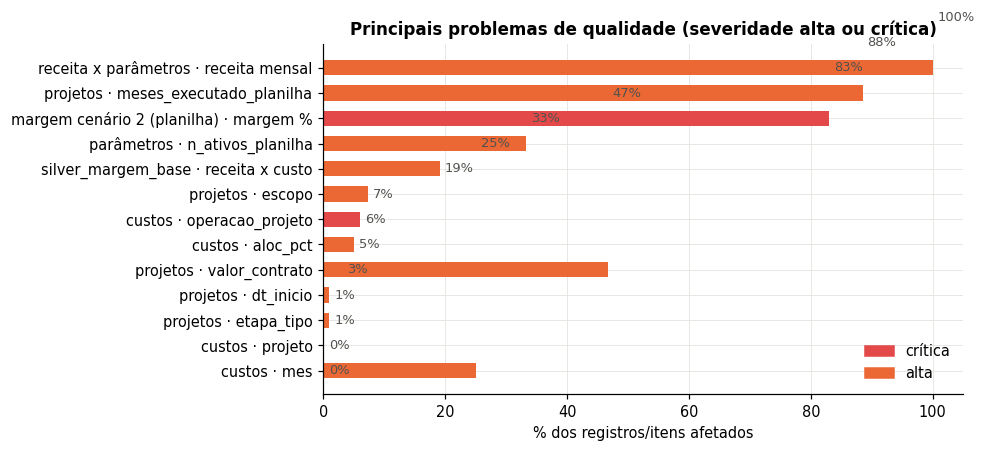

In [ ]:
DQ_DF = pd.DataFrame(DQ)
ORD = {"crítica": 0, "alta": 1, "média": 2, "baixa": 3}
DQ_DF = DQ_DF.sort_values(["severidade", "dimensao", "pct"], key=lambda s: s.map(ORD) if s.name == "severidade" else s, ascending=[True, True, False]).reset_index(drop=True)
DQ_DF.to_csv(PASTAS["meta"] / "qualidade_dados.csv", index=False)
display(DQ_DF[DQ_DF["afetados"] > 0][["severidade", "dimensao", "tabela", "atributo", "verificacao", "afetados", "total", "pct", "tratamento"]])
print(f"{len(DQ_DF)} verificações | {int((DQ_DF.afetados > 0).sum())} com ocorrência | {int(((DQ_DF.afetados > 0) & DQ_DF.severidade.isin(['crítica', 'alta'])).sum())} de severidade alta/crítica | {int((DQ_DF.afetados == 0).sum())} sem ocorrência (atributos íntegros: demonstração de que foram examinados)")

# Reconciliação da receita por projeto contra a receita-base da aba de parâmetros (razão; sem valores absolutos)
rz = (_part["soma_projetos"].values / PAR["receita_param_total"].values)
display(pd.DataFrame({"mês": [m[:3] for m in MESES_PT], "razão soma-dos-projetos ÷ receita-base": np.round(rz, 2)}).T)

fig, ax = plt.subplots(figsize=(9, 4.2))
top = DQ_DF[(DQ_DF.afetados > 0) & DQ_DF.severidade.isin(["crítica", "alta"])].sort_values("pct")
cores = [VERMELHO if s == "crítica" else LARANJA for s in top.severidade]
ax.barh([f"{t} · {a}"[:62] for t, a in zip(top.tabela, top.atributo)], top.pct, color=cores, height=.6)
for y, v in enumerate(top.pct): ax.text(v + .8, y, f"{v:.0f}%", va="center", fontsize=8.5, color="#52514e")
ax.set_xlabel("% dos registros/itens afetados"); ax.set_title("Principais problemas de qualidade (severidade alta ou crítica)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=VERMELHO), plt.Rectangle((0, 0), 1, 1, color=LARANJA)], labels=["crítica", "alta"], loc="lower right")
plt.tight_layout(); salvar_fig("fig01_qualidade", "Principais problemas de qualidade"); plt.show()

**Leitura.** Os achados que mais pesam para as respostas: (i) o **cenário 2 da planilha não reproduz a margem plena** (referências quebradas) — por isso o pipeline recalcula; (ii) a **receita por projeto não concilia** com a receita-base da aba de parâmetros (a razão varia mês a mês), o que a empresa deveria investigar; (iii) **custos de equipe só existem de fevereiro a outubro**, e fevereiro é parcial — a análise de margem fica restrita a **mar–out**; (iv) **63 meses-projeto têm receita sem nenhum custo de equipe**, o que tende a superestimar a margem desses projetos (testado na sensibilidade); (v) `TODAY()` tornava prazos instáveis — resolvido com data de corte fixa.

### 8.1 Qualidade após o tratamento (Silver/Gold)
Revalidação dos atributos já tratados — o que continua pendente é aceito e documentado.

In [ ]:
SENSIVEIS = {"operacao_projeto", "codigo_projeto", "salario", "beneficios", "bonus"}
todas_colunas = set().union(*[set(d[0].columns) for d in GOLD.values()]) | set(silver_custo.columns) | set(silver_projeto.columns)
jan = fato_margem[fato_margem.fl_mes_na_janela]
pos = []
def ver(dim, item, ok, nota=""): pos.append(dict(dimensao=dim, verificacao=item, resultado="OK" if ok else "ATENÇÃO", nota=nota))
ver("unicidade", "chave de projeto única e não nula (silver_projeto, dim_projeto)", silver_projeto["projeto"].is_unique and silver_projeto["projeto"].notna().all())
ver("completude", "rótulos de escopo/tipo sem nulos após padronização", dim_escopo["escopo_grupo"].notna().all() and dim_tipo["grupo_tipo"].notna().all())
ver("completude", "margem calculada em todos os meses da janela", jan["margem_plena"].notna().all())
ver("conformidade", "alíquotas entre 0 e 1", silver_par[["imposto", "comissao"]].apply(lambda s: s.between(0, 1)).all().all())
ver("conformidade", "alocação (FTE) por linha ≥ 0", (silver_custo["aloc_pct"].dropna() >= 0).all())
ver("acurácia", "margem % de contribuição ≤ base de cálculo (1 − impostos − comissão)", (jan["margem_contribuicao_pct"].dropna() <= silver_par["base_calculo"].max() + 1e-9).all())
ver("consistência", "receita líquida ≤ receita bruta quando positiva", (fato_margem.loc[fato_margem.receita_bruta > 0, "receita_liquida"] <= fato_margem.loc[fato_margem.receita_bruta > 0, "receita_bruta"]).all())
ver("integridade", "todas as FKs resolvidas (garantido pelo banco)", True)
ver("confidencialidade", "nenhuma coluna sensível nas camadas Silver/Gold", not (SENSIVEIS & todas_colunas))
ver("atualidade", "datas relativas fixadas pela data de corte", True, f"data de corte = {DATA_CORTE.date()}")
ver("aceito/documentado", "receita sem custo de equipe em parte dos meses-projeto", False, "Aceito; avaliado na sensibilidade (seção 11)")
ver("aceito/documentado", "receita por projeto não concilia com a aba de parâmetros", False, "Aceito; fonte do MVP = receita por projeto")
POS = pd.DataFrame(pos); display(POS); POS.to_csv(PASTAS["meta"] / "qualidade_pos_tratamento.csv", index=False)
assert POS.loc[~POS.dimensao.str.startswith("aceito"), "resultado"].eq("OK").all()

,dimensao,verificacao,resultado,nota
0,unicidade,"chave de projeto única e não nula (silver_projeto, dim_projeto)",OK,
1,completude,rótulos de escopo/tipo sem nulos após padronização,OK,
2,completude,margem calculada em todos os meses da janela,OK,
3,conformidade,alíquotas entre 0 e 1,OK,
4,conformidade,alocação (FTE) por linha ≥ 0,OK,
5,acurácia,margem % de contribuição ≤ base de cálculo (1 − impostos − comissão),OK,
6,consistência,receita líquida ≤ receita bruta quando positiva,OK,
7,integridade,todas as FKs resolvidas (garantido pelo banco),OK,
8,confidencialidade,nenhuma coluna sensível nas camadas Silver/Gold,OK,
9,atualidade,datas relativas fixadas pela data de corte,OK,data de corte = 2026-11-17


## 9. Modelo de dados, linhagem e Catálogo de Dados

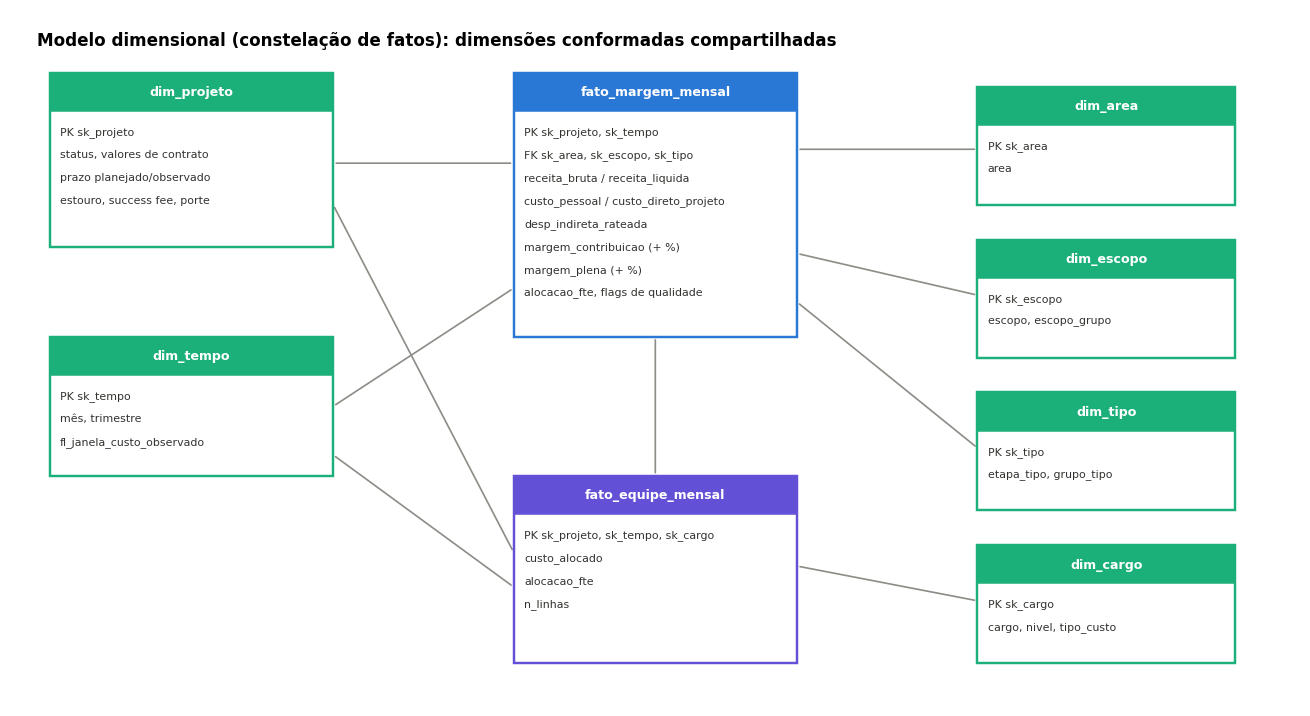

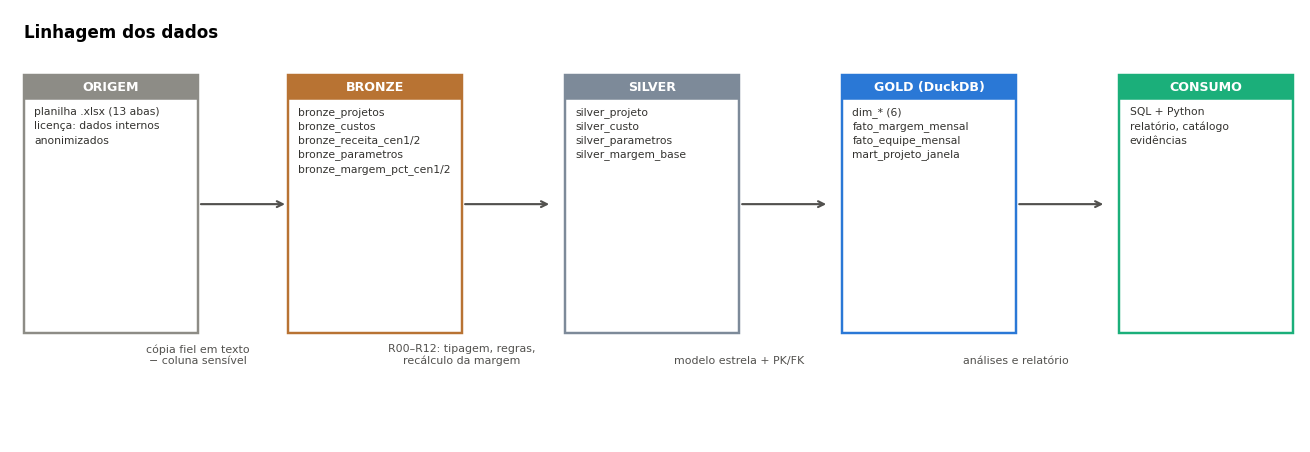

In [ ]:
def caixa(ax, x, y, w, h, titulo, linhas, cor, fs=7.2):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc="white", ec=cor, lw=1.6, zorder=2))
    ax.add_patch(plt.Rectangle((x, y + h - .055), w, .055, fc=cor, ec=cor, zorder=3))
    ax.text(x + w / 2, y + h - .028, titulo, ha="center", va="center", color="white", fontsize=8.3, fontweight="bold", zorder=4)
    for i, l in enumerate(linhas): ax.text(x + .008, y + h - .085 - i * .033, l, fontsize=fs, va="center", zorder=4, color="#33322f")
fig, ax = plt.subplots(figsize=(12, 6.6)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
caixa(ax, .39, .53, .22, .38, "fato_margem_mensal", ["PK sk_projeto, sk_tempo", "FK sk_area, sk_escopo, sk_tipo", "receita_bruta / receita_liquida", "custo_pessoal / custo_direto_projeto", "desp_indireta_rateada", "margem_contribuicao (+ %)", "margem_plena (+ %)", "alocacao_fte, flags de qualidade"], AZUL)
caixa(ax, .39, .06, .22, .27, "fato_equipe_mensal", ["PK sk_projeto, sk_tempo, sk_cargo", "custo_alocado", "alocacao_fte", "n_linhas"], VIOLETA)
caixa(ax, .03, .66, .22, .25, "dim_projeto", ["PK sk_projeto", "status, valores de contrato", "prazo planejado/observado", "estouro, success fee, porte"], VERDE)
caixa(ax, .03, .33, .22, .2, "dim_tempo", ["PK sk_tempo", "mês, trimestre", "fl_janela_custo_observado"], VERDE)
caixa(ax, .75, .72, .2, .17, "dim_area", ["PK sk_area", "area"], VERDE)
caixa(ax, .75, .5, .2, .17, "dim_escopo", ["PK sk_escopo", "escopo, escopo_grupo"], VERDE)
caixa(ax, .75, .28, .2, .17, "dim_tipo", ["PK sk_tipo", "etapa_tipo, grupo_tipo"], VERDE)
caixa(ax, .75, .06, .2, .17, "dim_cargo", ["PK sk_cargo", "cargo, nivel, tipo_custo"], VERDE)
for (x1, y1, x2, y2) in [(.25, .78, .39, .78), (.25, .43, .39, .6), (.61, .8, .75, .8), (.61, .65, .75, .59), (.61, .58, .75, .37), (.61, .2, .75, .15), (.5, .33, .5, .53), (.25, .72, .39, .22), (.25, .36, .39, .17)]:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-", color=CINZA, lw=1.1), zorder=1)
ax.text(.02, .97, "Modelo dimensional (constelação de fatos): dimensões conformadas compartilhadas", fontsize=11, fontweight="bold", va="top")
plt.tight_layout(); salvar_fig("fig02_modelo_estrela", "Modelo estrela"); plt.show()

fig, ax = plt.subplots(figsize=(12, 4.2)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
for x, t, cor, ls in [(.01, "ORIGEM", CINZA, ["planilha .xlsx (13 abas)", "licença: dados internos", "anonimizados"]),
                      (.215, "BRONZE", "#b87333", ["bronze_projetos", "bronze_custos", "bronze_receita_cen1/2", "bronze_parametros", "bronze_margem_pct_cen1/2"]),
                      (.43, "SILVER", "#7d8a99", ["silver_projeto", "silver_custo", "silver_parametros", "silver_margem_base"]),
                      (.645, "GOLD (DuckDB)", AZUL, ["dim_* (6)", "fato_margem_mensal", "fato_equipe_mensal", "mart_projeto_janela"]),
                      (.86, "CONSUMO", VERDE, ["SQL + Python", "relatório, catálogo", "evidências"])]:
    caixa(ax, x, .25, .135, .6, t, ls, cor, fs=7)
for x in (.145, .35, .565, .78): ax.annotate("", xy=(x + .07, .55), xytext=(x, .55), arrowprops=dict(arrowstyle="->", color="#52514e", lw=1.4))
ax.text(.145, .18, "cópia fiel em texto\n− coluna sensível", ha="center", fontsize=7.2, color="#52514e")
ax.text(.35, .18, "R00–R12: tipagem, regras,\nrecálculo da margem", ha="center", fontsize=7.2, color="#52514e")
ax.text(.565, .18, "modelo estrela + PK/FK", ha="center", fontsize=7.2, color="#52514e")
ax.text(.78, .18, "análises e relatório", ha="center", fontsize=7.2, color="#52514e")
ax.text(.01, .97, "Linhagem dos dados", fontsize=11, fontweight="bold", va="top")
plt.tight_layout(); salvar_fig("fig03_linhagem", "Linhagem"); plt.show()

In [ ]:
DESC = """sk_tempo|Chave substituta do mês (AAAAMM)|AAAAMM
data_mes|Primeiro dia do mês|calendário
ano|Ano de referência|parâmetro ANO
mes_num|Número do mês (1–12)|calendário
nome_mes|Nome do mês em português|calendário
trimestre|Trimestre do ano (1–4)|calendário
fl_janela_custo_observado|Mês em que há custo de equipe observado (janela de análise)|parâmetros JANELA_INI/FIM
fl_mes_corrente_ou_futuro|Mês igual ou posterior ao da data de corte|R05
sk_area|Chave substituta da área|sequência
area|Área do projeto (rótulo anonimizado A1/A2)|aba Projetos
sk_escopo|Chave substituta do escopo|sequência
escopo|Rótulo anonimizado do escopo do projeto|aba Projetos; R12
escopo_grupo|Escopo com agrupamento de categorias raras em 'Outros'|R12
sk_tipo|Chave substituta do tipo|sequência
etapa_tipo|Etapa/tipo do contrato informado na planilha|aba Projetos; R12
grupo_tipo|Modelo de receita: Pontual, Recorrente ou Projeto estruturado|R12
sk_cargo|Chave substituta do cargo|sequência
cargo|Cargo da pessoa alocada ou 'Custo com projeto' (custo não-pessoal)|aba Custos de Projeto
nivel|Nível hierárquico do cargo|R03
tipo_custo|Pessoal ou Direto de projeto|R03
ordem_nivel|Ordem do nível (1 = mais sênior)|R03
sk_projeto|Chave substituta do projeto|sequência
projeto|Identificador anonimizado do projeto (letras)|aba Projetos
status|Situação do projeto: Ativo, Finalizado ou Pausado|aba Projetos
valor_contrato|Valor total do contrato (R$ descaracterizados no modo público)|aba Projetos; R00 R08
valor_mensal_contrato|Valor mensal do contrato (R$)|aba Projetos; R00
receita_sf_liquida|Receita de success fee líquida de comissão (R$)|aba Projetos; R00
dt_inicio|Data de início do contrato|aba Projetos
dt_fim_contrato|Data de fim prevista do contrato|aba Projetos
dt_fim_real|Data de fim real (nula se em andamento ou não informada)|aba Projetos
prazo_planejado_meses|Prazo contratual em meses (dias ÷ 30)|R06
duracao_observada_meses|Duração observada até o fim real, a data de corte ou o fim contratual|R07
estouro_meses|Meses além do planejado (0 se dentro do prazo)|R07
fl_estourou_prazo|Estouro de prazo acima da tolerância|R07
fl_tem_success_fee|Projeto com receita de success fee|R12
fl_contrato_valor_ausente|Valor de contrato ausente ou zero|R08
fl_fim_real_imputado|Fim real ausente em projeto não ativo (usa fim contratual)|R07
faixa_porte|Tercil da receita mensal média na janela (Porte P/M/G) ou 'Sem receita na janela'|derivado de receita
receita_bruta|Receita bruta do mês (cenário 2), em R$|aba 2 Mensal; R00 R09
deducao_impostos|Impostos e deduções sobre a receita|R10
comissao_comercial|Comissão comercial sobre a receita|R10
receita_liquida|Receita bruta − deduções − comissão|R10
custo_pessoal|Custo de pessoal alocado ao projeto no mês|R03 R04
custo_direto_projeto|Custos diretos não-pessoais do projeto|R03
custo_total_projeto|Custo de pessoal + custo direto|R10
desp_indireta_rateada|Despesa indireta rateada igualmente entre projetos com custo no mês|R09
desp_indireta_rateio_custo|Despesa indireta rateada proporcionalmente ao custo (sensibilidade)|R09
desp_indireta_rateio_receita|Despesa indireta rateada proporcionalmente à receita (sensibilidade)|R09
margem_contribuicao|Receita líquida − custo do projeto (nula fora da janela)|R10 R11
margem_plena|Margem de contribuição − despesa indireta rateada (nula fora da janela)|R10 R11
margem_contribuicao_pct|Margem de contribuição ÷ receita bruta|R11
margem_plena_pct|Margem plena ÷ receita bruta|R11
alocacao_fte|Soma da alocação das pessoas no projeto (equivalente de tempo integral)|aba Custos
n_linhas_equipe|Número de linhas de alocação de pessoal no mês|aba Custos
fl_mes_na_janela|Mês dentro da janela com custo observado|parâmetros
fl_receita_sem_custo|Receita > 0 sem nenhum custo de equipe no mês|qualidade
fl_custo_sem_receita|Custo de equipe sem receita no mês|qualidade
fl_receita_negativa|Receita negativa (estorno/ajuste)|qualidade
fl_receita_em_branco|Célula de receita em branco na origem (tratada como 0)|qualidade
custo_alocado|Custo alocado (remuneração × alocação) por cargo e mês|R04 R00
n_linhas|Linhas de alocação agregadas no grão|agregação
custo_sobre_receita|Custo total do projeto ÷ receita bruta|derivado
n_meses_com_custo|Meses da janela com custo alocado|derivado
n_meses_com_receita|Meses da janela com receita positiva|derivado
receita_mensal_media|Receita bruta média dos meses com receita|derivado
custo_pessoal_mensal_medio|Custo de pessoal médio dos meses com custo|derivado
alocacao_fte_media|FTE médio nos meses com custo|derivado
share_lideranca|Fração do custo de pessoal em Liderança|derivado de fato_equipe
share_coordenacao|Fração do custo de pessoal em Coordenação|derivado de fato_equipe
share_operacional|Fração do custo de pessoal em Associado, Analista e Estágio|derivado de fato_equipe
n_niveis_equipe|Número de níveis hierárquicos distintos na equipe|derivado
volatilidade_mc_pct|Desvio-padrão da margem de contribuição mensal (≥ 3 meses)|derivado
margem_plena_pct_clip|Margem plena % limitada inferiormente a −100% (uso em modelos)|derivado"""
DESCR = {l.split("|")[0]: (l.split("|")[1], l.split("|")[2]) for l in DESC.split("\n")}
NULO = {"valor_contrato": "Nulo = contrato sem valor informado/zerado (R08)", "dt_fim_real": "Nulo = projeto em andamento ou data não informada",
        "dt_inicio": "Nulo = início não informado", "dt_fim_contrato": "Nulo = início/prazo não informados", "dt_fim_real_": "",
        "margem_contribuicao": "Nulo fora da janela mar–out (custo não observado)", "margem_plena": "Nulo fora da janela mar–out (custo não observado)",
        "margem_contribuicao_pct": "Nulo se receita ≤ 0 ou fora da janela", "margem_plena_pct": "Nulo se receita ≤ 0 ou fora da janela",
        "margem_plena_pct_clip": "Nulo se receita ≤ 0 na janela", "volatilidade_mc_pct": "Nulo se menos de 3 meses com receita",
        "valor_mensal_contrato": "Nulo = não informado", "prazo_planejado_meses": "Nulo = prazo não informado", "duracao_observada_meses": "Nulo = início não informado",
        "estouro_meses": "Nulo = início não informado", "alocacao_fte_media": "Nulo = projeto sem custo na janela", "receita_mensal_media": "Nulo = sem receita na janela",
        "custo_pessoal_mensal_medio": "Nulo = sem custo na janela", "custo_sobre_receita": "Nulo = sem receita na janela",
        "share_lideranca": "Nulo = sem custo de pessoal na janela", "share_coordenacao": "Nulo = sem custo de pessoal na janela", "share_operacional": "Nulo = sem custo de pessoal na janela",
        "receita_sf_liquida": "Nulo = sem success fee", "aloc_pct": "Nulo = não informado"}
LINHAGEM_TAB = {"dim_tempo": "Gerada a partir do calendário do ano de análise (parâmetros)", "dim_area": "silver_projeto ← bronze_projetos ← aba Projetos",
                "dim_escopo": "silver_projeto ← bronze_projetos ← aba Projetos", "dim_tipo": "silver_projeto ← bronze_projetos ← aba Projetos",
                "dim_cargo": "silver_custo ← bronze_custos ← aba Custos de Projeto", "dim_projeto": "silver_projeto ← bronze_projetos ← aba Projetos",
                "fato_margem_mensal": "silver_margem_base ← (bronze_receita_cen2 + bronze_custos + bronze_parametros)", "fato_equipe_mensal": "silver_custo ← bronze_custos ← aba Custos de Projeto",
                "mart_projeto_janela": "fato_margem_mensal + fato_equipe_mensal + dim_projeto (agregação na janela)"}
MEDIDAS_MART = {"receita_bruta", "receita_liquida", "custo_pessoal", "custo_direto_projeto", "custo_total_projeto", "desp_indireta_rateada", "margem_contribuicao",
                "margem_plena", "margem_contribuicao_pct", "margem_plena_pct"}
linhas = []
for tab, (df, pk, fks) in GOLD.items():
    for col in df.columns:
        s = df[col]; desc, regra = DESCR[col] if col in DESCR else ("(sem descrição)", "")
        if tab == "mart_projeto_janela" and col in MEDIDAS_MART: desc = "[Na janela mar–out] " + desc
        nn = int(s.isna().sum())
        if pd.api.types.is_bool_dtype(s): dom, tipo = "{verdadeiro, falso}", "booleano"
        elif pd.api.types.is_datetime64_any_dtype(s): dom, tipo = f"{s.min():%Y-%m-%d} a {s.max():%Y-%m-%d}", "data"
        elif pd.api.types.is_numeric_dtype(s):
            tipo = "numérico (chave)" if col.startswith("sk_") else "numérico"
            dom = "identificador único" if col.startswith("sk_") else f"observado [{s.min():,.2f} ; {s.max():,.2f}]"
            if col.endswith("_pct") or col.endswith("_clip"): dom += "; esperado ≤ 0,755"
        else:
            tipo = "categórico"; u = sorted(s.dropna().astype(str).unique())
            dom = ("{" + "; ".join(u) + "}") if len(u) <= 14 else f"{len(u)} categorias (identificadores anonimizados)"
        obrig = "Obrigatório" if nn == 0 else f"Admite nulo ({nn} nulos). {NULO.get(col, 'Ausência = não informado')}"
        linhas.append(dict(tabela=tab, atributo=col, tipo=tipo, descricao=desc, dominio=dom, obrigatoriedade=obrig,
                           linhagem=f"{LINHAGEM_TAB[tab]} | regra: {regra}", pk="PK" if col in pk else ("FK" if col in [f[0] for f in fks] else "")))
CATALOGO = pd.DataFrame(linhas)
assert not (CATALOGO["descricao"] == "(sem descrição)").any(), CATALOGO[CATALOGO.descricao == "(sem descrição)"]
CATALOGO.to_csv(PASTAS["catalogo"] / "catalogo_dados.csv", index=False, encoding="utf-8-sig")
md = ["# Catálogo de Dados — MVP Margem de Projetos", "", f"Gerado em {DATA_CORTE.date()} (data de corte). Modo: `{MODO}` — " + ("valores em R$ descaracterizados." if MODO == "publico" else "valores reais."), ""]
for tab, grp in CATALOGO.groupby("tabela", sort=False):
    md += [f"## {tab}", f"*Linhagem:* {LINHAGEM_TAB[tab]}", "", "| Atributo | Tipo | Descrição | Domínio | Obrigatoriedade | Regra/origem |", "|---|---|---|---|---|---|"]
    md += [f"| {r.atributo}{' 🔑' if r.pk else ''} | {r.tipo} | {r.descricao} | {r.dominio} | {r.obrigatoriedade} | {r.linhagem.split('regra: ')[1]} |" for r in grp.itertuples()] + [""]
(PASTAS["catalogo"] / "catalogo_dados.md").write_text("\n".join(md), encoding="utf-8")
display(CATALOGO[CATALOGO.tabela == "mart_projeto_janela"][["atributo", "tipo", "descricao", "dominio", "obrigatoriedade"]].head(12))
print(f"Catálogo: {len(CATALOGO)} atributos em {CATALOGO.tabela.nunique()} tabelas → catalogo/catalogo_dados.csv e .md")

,atributo,tipo,descricao,dominio,obrigatoriedade
71,sk_projeto,numérico (chave),Chave substituta do projeto,identificador único,Obrigatório
72,projeto,categórico,Identificador anonimizado do projeto (letras),96 categorias (identificadores anonimizados),Obrigatório
73,area,categórico,Área do projeto (rótulo anonimizado A1/A2),{A1; A2},Obrigatório
74,escopo_grupo,categórico,Escopo com agrupamento de categorias raras em 'Outros',{Arábia; Croácia; Dubai; Milão; Não informado; Outros; Vaticano; Veneza},Obrigatório
75,etapa_tipo,categórico,Etapa/tipo do contrato informado na planilha,{Acompanhamento Pós Deal; Assinatura de Documentos; Conselhos; Definição da ...,Obrigatório
76,grupo_tipo,categórico,"Modelo de receita: Pontual, Recorrente ou Projeto estruturado",{Pontual; Projeto estruturado; Recorrente},Obrigatório
77,status,categórico,"Situação do projeto: Ativo, Finalizado ou Pausado",{Ativo; Finalizado; Pausado},Obrigatório
78,faixa_porte,categórico,Tercil da receita mensal média na janela (Porte P/M/G) ou 'Sem receita na ja...,{Porte G; Porte M; Porte P; Sem receita na janela},Obrigatório
79,valor_contrato,numérico,Valor total do contrato (R$ descaracterizados no modo público),"observado [10,627.00 ; 717,322.50]",Admite nulo (15 nulos). Nulo = contrato sem valor informado/zerado (R08)
80,prazo_planejado_meses,numérico,Prazo contratual em meses (dias ÷ 30),observado [0.00 ; 24.00],Admite nulo (1 nulos). Nulo = prazo não informado


Catálogo: 106 atributos em 9 tabelas → catalogo/catalogo_dados.csv e .md


## 10. Perguntas de apoio
As consultas usam **SQL sobre o modelo Gold** (DuckDB) e Python para testes estatísticos e gráficos. Convenções: *margem de contribuição* = antes das despesas indiretas; *margem plena* = depois do rateio das despesas indiretas; percentuais sobre a receita bruta; "janela" = mar–out/2026. **Margens agregadas são razões de somas** (margem total ÷ receita total), nunca médias de percentuais.

In [ ]:
RELATORIO, RES = [], {}
def texto(md_):
    display(Markdown(md_)); RELATORIO.append(md_)
def md_tabela(df):
    d = df.copy(); d.columns = [str(c) for c in d.columns]
    linhas_ = ["| " + " | ".join(d.columns) + " |", "|" + "---|" * len(d.columns)]
    for r in d.itertuples(index=False): linhas_.append("| " + " | ".join("—" if (isinstance(v, float) and np.isnan(v)) else str(v) for v in r) + " |")
    return "\n".join(linhas_)
def tabela(df):
    display(df); RELATORIO.append(md_tabela(df))
def figura(nome, legenda):
    RELATORIO.append(f"![{legenda}](../evidencias/{nome}.png)\n\n*{legenda}*")
def f_brl(s): return s.map(lambda v: "—" if pd.isna(v) else brl(v))
def f_pct(s): return s.map(pct)
SQL = lambda s: con.execute(s).df()
M = SQL("SELECT * FROM mart_projeto_janela")
base_calc = float(silver_par.loc[silver_par.mes.between(JANELA_INI, JANELA_FIM), "base_calculo"].mean())
tot = SQL("SELECT SUM(receita_bruta) rec, SUM(margem_contribuicao) mc, SUM(margem_plena) mp, SUM(desp_indireta_rateada) di, COUNT(*) n FROM mart_projeto_janela").iloc[0]
RES.update(n_proj=int(tot.n), n_proj_rec=int((M.receita_bruta > 0).sum()), mc_pct=tot.mc / tot.rec, mp_pct=tot.mp / tot.rec, di_pct=tot.di / tot.rec,
           n_mp_neg=int((M.margem_plena < 0).sum()), n_mc_neg=int((M.margem_contribuicao < 0).sum()))
texto(f"""### 10.0 Retrato da carteira na janela (mar–out/2026)
* **{RES['n_proj']} projetos** com atividade na base, dos quais **{RES['n_proj_rec']}** com receita na janela.
* **Margem de contribuição da carteira: {pct(RES['mc_pct'])}** da receita bruta; após o rateio das despesas indiretas (equivalentes a {pct(RES['di_pct'])} da receita), a **margem plena é {pct(RES['mp_pct'])}**.
* **{RES['n_mp_neg']} projetos ({pct(RES['n_mp_neg'] / RES['n_proj'], 0)}) têm margem plena negativa** e {RES['n_mc_neg']} têm margem de contribuição negativa.""")

### 10.0 Retrato da carteira na janela (mar–out/2026)
* **96 projetos** com atividade na base, dos quais **77** com receita na janela.
* **Margem de contribuição da carteira: 52,4%** da receita bruta; após o rateio das despesas indiretas (equivalentes a 48,5% da receita), a **margem plena é 3,9%**.
* **57 projetos (59%) têm margem plena negativa** e 19 têm margem de contribuição negativa.

### 10.1 Pergunta de apoio 1 — Onde a margem se concentra?

**Por área**

,área,projetos,c/ receita,receita bruta,margem contrib. (R$),margem plena (R$),margem contrib. %,margem plena %,projetos c/ margem plena < 0,% da receita,% da margem de contribuição
0,A1,48,35,R$ 4.196.085,R$ 2.229.289,R$ 626.045,"53,1%","14,9%",24,"70,4%","71,4%"
1,A2,48,42,R$ 1.762.483,R$ 893.220,-R$ 394.769,"50,7%","-22,4%",33,"29,6%","28,6%"


**Por tipo de contrato**

,tipo de contrato,projetos,c/ receita,receita bruta,margem contrib. (R$),margem plena (R$),margem contrib. %,margem plena %,projetos c/ margem plena < 0,% da receita,% da margem de contribuição
0,Projeto estruturado,49,36,R$ 4.209.369,R$ 2.238.479,R$ 628.694,"53,2%","14,9%",24,"70,6%","71,7%"
1,Pontual,26,20,R$ 793.762,R$ 398.446,-R$ 115.188,"50,2%","-14,5%",16,"13,3%","12,8%"
2,Recorrente,21,21,R$ 955.437,R$ 485.584,-R$ 282.229,"50,8%","-29,5%",17,"16,0%","15,6%"


**Por escopo**

,escopo,projetos,c/ receita,receita bruta,margem contrib. (R$),margem plena (R$),margem contrib. %,margem plena %,projetos c/ margem plena < 0,% da receita,% da margem de contribuição
0,Dubai,20,16,R$ 2.538.789,R$ 1.404.274,R$ 707.319,"55,3%","27,9%",6,"42,6%","45,0%"
1,Outros,7,7,R$ 256.136,R$ 153.050,R$ 3.396,"59,8%","1,3%",4,"4,3%","4,9%"
2,Vaticano,12,8,R$ 356.465,R$ 198.791,-R$ 20.582,"55,8%","-5,8%",6,"6,0%","6,4%"
3,Não informado,7,4,R$ 281.881,R$ 149.289,-R$ 38.998,"53,0%","-13,8%",4,"4,7%","4,8%"
4,Milão,23,17,R$ 1.409.953,R$ 695.257,-R$ 43.551,"49,3%","-3,1%",15,"23,7%","22,3%"
5,Veneza,8,6,R$ 256.638,R$ 103.424,-R$ 94.700,"40,3%","-36,9%",6,"4,3%","3,3%"
6,Croácia,8,8,R$ 492.030,R$ 253.824,-R$ 113.219,"51,6%","-23,0%",7,"8,3%","8,1%"
7,Arábia,11,11,R$ 366.676,R$ 164.599,-R$ 168.388,"44,9%","-45,9%",9,"6,2%","5,3%"


**Por porte**

,porte,projetos,c/ receita,receita bruta,margem contrib. (R$),margem plena (R$),margem contrib. %,margem plena %,projetos c/ margem plena < 0,% da receita,% da margem de contribuição
0,Porte G,26,26,R$ 3.840.376,R$ 2.314.384,R$ 1.484.252,"60,3%","38,6%",2,"64,5%","74,1%"
1,Porte M,23,23,R$ 1.190.318,R$ 504.259,-R$ 180.008,"42,4%","-15,1%",14,"20,0%","16,1%"
2,Porte P,28,28,R$ 927.874,R$ 449.742,-R$ 466.423,"48,5%","-50,3%",23,"15,6%","14,4%"
3,Sem receita na janela,19,0,R$ 0,-R$ 145.876,-R$ 606.545,—,—,18,"0,0%","-4,7%"


**Por etapa/tipo**

,etapa/tipo,projetos,c/ receita,receita bruta,margem contrib. (R$),margem plena (R$),margem contrib. %,margem plena %,projetos c/ margem plena < 0,% da receita,% da margem de contribuição
0,Acompanhamento Pós Deal,5,5,R$ 1.268.098,R$ 670.338,R$ 498.149,"52,9%","39,3%",0,"21,3%","21,5%"
1,Assinatura de Documentos,3,2,R$ 523.486,R$ 289.361,R$ 136.986,"55,3%","26,2%",1,"8,8%","9,3%"
2,Definição da Tese,4,4,R$ 469.182,R$ 290.754,R$ 135.544,"62,0%","28,9%",1,"7,9%","9,3%"
3,Pausado,5,5,R$ 468.385,R$ 259.168,R$ 114.468,"55,3%","24,4%",3,"7,9%","8,3%"
4,Finalizado com Success Fee,3,1,R$ 129.886,R$ 71.770,R$ 12.009,"55,3%","9,2%",2,"2,2%","2,3%"
5,Conselhos,1,1,R$ 85.016,R$ 49.702,R$ 3.331,"58,5%","3,9%",0,"1,4%","1,6%"
6,Não informado,1,1,R$ 13.284,R$ 9.190,R$ 2.648,"69,2%","19,9%",0,"0,2%","0,3%"
7,Finalizado sem Success Fee,10,5,R$ 286.929,R$ 164.781,-R$ 45.663,"57,4%","-15,9%",7,"4,8%","5,3%"
8,Modelagem e Estudo,4,3,R$ 113.975,R$ 58.104,-R$ 58.181,"51,0%","-51,0%",1,"1,9%","1,9%"
9,Finalizado com Pós Deal,2,1,R$ 12.989,-R$ 15.101,-R$ 65.426,"-116,3%","-503,7%",2,"0,2%","-0,5%"


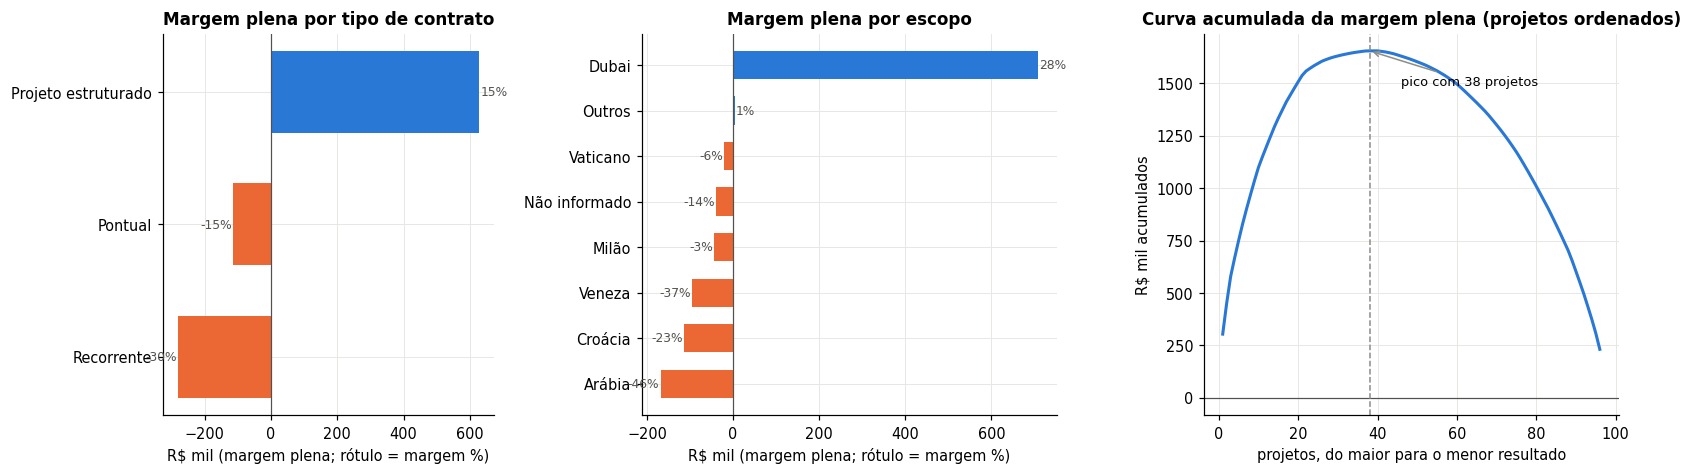

#### Resposta e discussão — pergunta de apoio 1
* **Concentração.** Apenas **15 dos 38 projetos com margem plena positiva** respondem por 80% do ganho positivo; os 5 maiores respondem por **45%** dele (Gini entre os positivos: 0,57). A curva acumulada atinge o pico com **38 projetos** e **cai depois**: os projetos de margem negativa consomem o equivalente a **86%** do ganho gerado pelos positivos. **H1 confirmada**: a margem é concentrada, e a cauda negativa é grande.
* **Tipo de contrato.** *Projeto estruturado* tem a melhor margem plena (14,9%) e é o único tipo com resultado positivo; o pior é *Recorrente* (-29,5%). A **área A1 tem margem plena de 14,9% contra -22,4% da A2** — mas atenção: a área é quase colinear com o tipo de contrato (quase todos os projetos de A1 são "estruturados" e os de A2, pontuais/recorrentes), então não é possível atribuir o efeito a um só dos dois (ver seção 11).
* **Escopo.** Entre os escopos com amostra mínima, a melhor margem plena é de *Dubai* (27,9%) e a pior de *Arábia* (-45,9%). Os rótulos de escopo estão anonimizados, então a leitura vale como diferença entre grupos, não como característica do serviço.
* **Contribuição vs. plena.** Na margem de contribuição (antes das despesas indiretas) a A2 fica em 50,7%; é o **rateio das despesas indiretas** que torna os projetos de menor ticket deficitários. Isso aponta para um *problema de piso de preço*, tratado na seção 11.
* **Projetos com custo e sem receita na janela.** 19 projetos tiveram custo de equipe mas nenhuma receita em mar–out, somando **-R$ 606.545 de margem plena** (equivale a 37% do ganho dos positivos). É a candidata mais direta a ação gerencial: encerrar, faturar ou pausar a alocação.

In [ ]:
def seg(dim, ordem="mp DESC"):
    return SQL(f"""SELECT {dim} AS segmento, COUNT(*) AS n_projetos, COUNT(*) FILTER (WHERE receita_bruta > 0) AS n_com_receita,
        SUM(receita_bruta) AS receita, SUM(margem_contribuicao) AS mc, SUM(margem_plena) AS mp,
        SUM(margem_contribuicao) / NULLIF(SUM(receita_bruta), 0) AS mc_pct, SUM(margem_plena) / NULLIF(SUM(receita_bruta), 0) AS mp_pct,
        COUNT(*) FILTER (WHERE margem_plena < 0) AS n_mp_neg
        FROM mart_projeto_janela GROUP BY 1 ORDER BY {ordem}""")
def mostrar_seg(df, nome):
    o = df.copy(); o["% da receita"] = (o.receita / o.receita.sum()).map(pct)
    o["% da margem de contribuição"] = (o.mc / o.mc.sum()).map(pct)
    o = o.assign(receita=f_brl(o.receita), mc=f_brl(o.mc), mp=f_brl(o.mp), mc_pct=f_pct(o.mc_pct), mp_pct=f_pct(o.mp_pct))
    o = o.rename(columns={"segmento": nome, "n_projetos": "projetos", "n_com_receita": "c/ receita", "receita": "receita bruta", "mc": "margem contrib. (R$)", "mp": "margem plena (R$)",
                          "mc_pct": "margem contrib. %", "mp_pct": "margem plena %", "n_mp_neg": "projetos c/ margem plena < 0"})
    tabela(o)
S_area, S_tipo, S_esc, S_porte = seg("area"), seg("grupo_tipo"), seg("escopo_grupo"), seg("faixa_porte")
S_etapa = seg("etapa_tipo")
for df, n in [(S_area, "área"), (S_tipo, "tipo de contrato"), (S_esc, "escopo"), (S_porte, "porte"), (S_etapa, "etapa/tipo")]:
    texto(f"**Por {n}**"); mostrar_seg(df, n)

# Pareto dos projetos
ps = M[["projeto", "margem_plena"]].sort_values("margem_plena", ascending=False).reset_index(drop=True)
pos_ = ps[ps.margem_plena > 0].copy(); pos_["acum"] = pos_.margem_plena.cumsum() / pos_.margem_plena.sum()
n80 = int((pos_.acum < .80).sum() + 1); n_pos = len(pos_)
ps["acum_liq"] = ps.margem_plena.cumsum()
topo_pico = int(ps["acum_liq"].idxmax()) + 1
RES.update(n80=n80, n_pos=n_pos, perda_neg=float(ps.loc[ps.margem_plena < 0, "margem_plena"].sum()), ganho_pos=float(pos_.margem_plena.sum()), topo_pico=topo_pico)
gini = lambda v: (np.abs(v[:, None] - v[None, :]).sum() / (2 * len(v) ** 2 * v.mean()))
RES["gini_pos"] = float(gini(pos_.margem_plena.values))
RES["top5_share"] = float(pos_.margem_plena.head(5).sum() / pos_.margem_plena.sum())

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1.25, 1.25]})
for ax, df, t in [(axs[0], S_tipo, "Margem plena por tipo de contrato"), (axs[1], S_esc, "Margem plena por escopo")]:
    d = df.sort_values("mp"); ax.barh(d.segmento, d.mp / 1000, color=[AZUL if v >= 0 else LARANJA for v in d.mp], height=.62)
    for y, (v, p_) in enumerate(zip(d.mp / 1000, d.mp_pct)): ax.text(v + (3 if v >= 0 else -3), y, pct(p_, 0), va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#52514e")
    ax.axvline(0, color="#52514e", lw=.8); ax.set_title(t); ax.set_xlabel("R$ mil (margem plena; rótulo = margem %)")
ax = axs[2]
ax.plot(range(1, len(ps) + 1), ps.acum_liq / 1000, color=AZUL, lw=2)
ax.axhline(0, color="#52514e", lw=.8); ax.axvline(topo_pico, color=CINZA, ls="--", lw=1)
ax.set_title("Curva acumulada da margem plena (projetos ordenados)"); ax.set_xlabel("projetos, do maior para o menor resultado"); ax.set_ylabel("R$ mil acumulados")
ax.annotate(f"pico com {topo_pico} projetos", (topo_pico, ps.acum_liq.max() / 1000), xytext=(topo_pico + 8, ps.acum_liq.max() / 1000 * .9), fontsize=8.5, arrowprops=dict(arrowstyle="->", color=CINZA))
plt.tight_layout(); salvar_fig("fig04_concentracao", "Onde a margem se concentra"); plt.show()
figura("fig04_concentracao", "Concentração da margem plena por tipo de contrato, escopo e curva acumulada")

mel_tipo = S_tipo.sort_values("mp", ascending=False).iloc[0]; pior_tipo = S_tipo.sort_values("mp").iloc[0]
mel_esc = S_esc[S_esc.segmento.isin(["Não informado", "Outros"]) == False].sort_values("mp_pct", ascending=False).iloc[0]
pior_esc = S_esc[S_esc.segmento.isin(["Não informado", "Outros"]) == False].sort_values("mp_pct").iloc[0]
RES.update(mel_tipo=mel_tipo.segmento, pior_tipo=pior_tipo.segmento, mel_tipo_pct=float(mel_tipo.mp_pct), pior_tipo_pct=float(pior_tipo.mp_pct),
           mel_esc=mel_esc.segmento, pior_esc=pior_esc.segmento, mel_esc_pct=float(mel_esc.mp_pct), pior_esc_pct=float(pior_esc.mp_pct))
a1, a2 = S_area.set_index("segmento").loc["A1"], S_area.set_index("segmento").loc["A2"]
sr = M[M.receita_bruta <= 0]; RES.update(n_sem_rec=len(sr), mp_sem_rec=float(sr.margem_plena.sum()), a1_pct=float(a1.mp_pct), a2_pct=float(a2.mp_pct), a1_mc=float(a1.mc_pct), a2_mc=float(a2.mc_pct))
texto(f"""#### Resposta e discussão — pergunta de apoio 1
* **Concentração.** Apenas **{n80} dos {n_pos} projetos com margem plena positiva** respondem por 80% do ganho positivo; os 5 maiores respondem por **{pct(RES['top5_share'], 0)}** dele (Gini entre os positivos: {fnum(RES['gini_pos'])}). A curva acumulada atinge o pico com **{topo_pico} projetos** e **cai depois**: os projetos de margem negativa consomem o equivalente a **{pct(-RES['perda_neg'] / RES['ganho_pos'], 0)}** do ganho gerado pelos positivos. **H1 {'confirmada' if RES['top5_share'] > .4 or n80 / n_pos < .4 else 'parcialmente confirmada'}**: a margem é concentrada, e a cauda negativa é grande.
* **Tipo de contrato.** *{RES['mel_tipo']}* tem a melhor margem plena ({pct(RES['mel_tipo_pct'])}) e é o único tipo com resultado positivo; o pior é *{RES['pior_tipo']}* ({pct(RES['pior_tipo_pct'])}). A **área A1 tem margem plena de {pct(RES['a1_pct'])} contra {pct(RES['a2_pct'])} da A2** — mas atenção: a área é quase colinear com o tipo de contrato (quase todos os projetos de A1 são "estruturados" e os de A2, pontuais/recorrentes), então não é possível atribuir o efeito a um só dos dois (ver seção 11).
* **Escopo.** Entre os escopos com amostra mínima, a melhor margem plena é de *{RES['mel_esc']}* ({pct(RES['mel_esc_pct'])}) e a pior de *{RES['pior_esc']}* ({pct(RES['pior_esc_pct'])}). Os rótulos de escopo estão anonimizados, então a leitura vale como diferença entre grupos, não como característica do serviço.
* **Contribuição vs. plena.** Na margem de contribuição (antes das despesas indiretas) a A2 fica em {pct(RES['a2_mc'])}; é o **rateio das despesas indiretas** que torna os projetos de menor ticket deficitários. Isso aponta para um *problema de piso de preço*, tratado na seção 11.
* **Projetos com custo e sem receita na janela.** {RES['n_sem_rec']} projetos tiveram custo de equipe mas nenhuma receita em mar–out, somando **{brl(RES['mp_sem_rec'])} de margem plena** (equivale a {pct(-RES['mp_sem_rec'] / RES['ganho_pos'], 0)} do ganho dos positivos). É a candidata mais direta a ação gerencial: encerrar, faturar ou pausar a alocação.""")

### 10.2 Pergunta de apoio 2 — A equipe explica a margem?

**Relação entre o custo do projeto sobre a receita e o sinal da margem (meses-projeto da janela com receita e custo)**

,custo de equipe ÷ receita bruta,meses-projeto,% c/ margem de contribuição < 0,% c/ margem plena < 0,margem plena mediana
0,≤ 10%,56.0,"0,0%","23,2%","25,1%"
1,10–25%,72.0,"0,0%","56,9%","-5,0%"
2,25–50%,88.0,"0,0%","90,9%","-31,2%"
3,"50%–75,5%",35.0,"0,0%","100,0%","-98,2%"
4,"> 75,5%",15.0,"100,0%","100,0%","-92,5%"


**Correlação de Spearman (nível projeto)**

,variável,alvo,n,rho,p
0,alocação média (FTE),margem plena %,77,"-0,24","0,035"
1,alocação média (FTE),margem de contribuição %,77,"-0,55","< 0,001"
2,% do custo em Liderança,margem plena %,77,"0,12","0,286"
3,% do custo em Liderança,margem de contribuição %,77,"-0,05","0,659"
4,% do custo em Coordenação,margem plena %,77,"0,18","0,127"
5,% do custo em Coordenação,margem de contribuição %,77,"0,19","0,107"
6,% do custo em Operacional,margem plena %,77,"-0,23","0,043"
7,% do custo em Operacional,margem de contribuição %,77,"-0,15","0,197"
8,nº de níveis na equipe,margem plena %,77,"-0,30","0,008"
9,nº de níveis na equipe,margem de contribuição %,77,"-0,36","0,001"


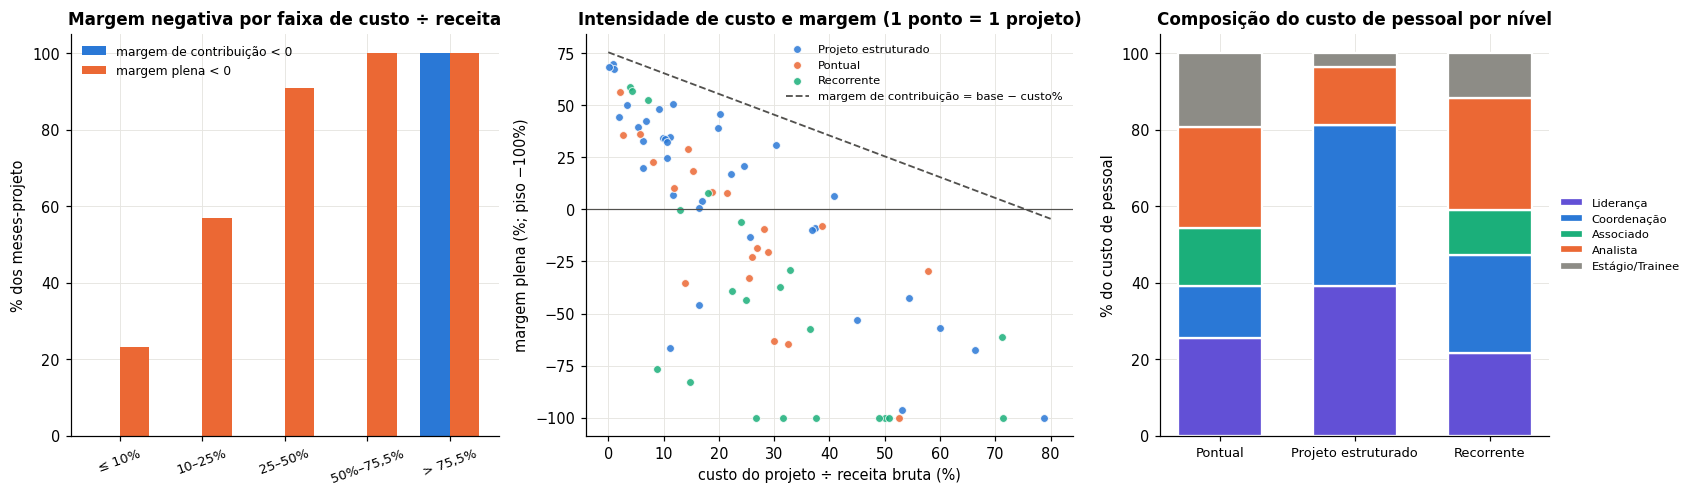

#### Resposta e discussão — pergunta de apoio 2
* **O ponto em que a margem vira negativa é aritmético e conhecido.** Com impostos e comissão consumindo 24,5% da receita, a **margem de contribuição fica negativa quando o custo do projeto passa de 75,5% da receita bruta**; com o rateio de despesas indiretas, o ponto de virada vem antes e **depende do tamanho do projeto**, porque a despesa indireta é praticamente um valor fixo por projeto-mês. Nos dados, 5,6% dos meses-projeto têm margem de contribuição negativa, mas **69,2% têm margem plena negativa**.
* **Em termos práticos:** uma equipe de custo mensal mediano (R$ 2.709) mais despesa indireta rateada mediana (R$ 7.112) exige honorário mensal de **R$ 13.008 para empatar** e **R$ 21.585 para atingir a margem plena-alvo de 30%**, contra uma receita mensal mediana observada de R$ 10.627.
* **Composição da equipe.** A correlação entre margem plena e o peso da liderança no custo é ρ = 0,12; entre margem plena e alocação média (FTE), ρ = -0,24. A associação com a razão custo ÷ receita é, como esperado, a mais forte (ρ = -0,80) por ser quase uma identidade contábil — por isso ela **não** entra como "explicação" na seção 11, e sim como régua de decisão.
* **Leitura de decisão (H3):** a intensidade de equipe relativa ao honorário é o que determina o sinal da margem; **o nível hierárquico da equipe, isoladamente, é um sinal fraco** (baixo). Em outras palavras, o controle não é "quem" aloca, e sim **quanto custo de equipe cabe em cada faixa de honorário**.

In [ ]:
PM = fato_margem.merge(dim_projeto[["sk_projeto", "projeto", "faixa_porte"]], on="sk_projeto").merge(silver_projeto[["projeto", "grupo_tipo", "area"]], on="projeto")
PM = PM[PM.fl_mes_na_janela & (PM.receita_bruta > 0) & (PM.custo_total_projeto > 0)].copy()
PM["r_custo"] = PM.custo_total_projeto / PM.receita_bruta
PM["r_desp"] = PM.desp_indireta_rateada / PM.receita_bruta
PM["r_total"] = PM.r_custo + PM.r_desp
bins = [0, .10, .25, .50, base_calc, np.inf]; labs = ["≤ 10%", "10–25%", "25–50%", f"50%–{pct(base_calc)}", f"> {pct(base_calc)}"]
PM["faixa_custo"] = pd.cut(PM.r_custo, bins=bins, labels=labs, right=True)
eq = PM.groupby("faixa_custo", observed=True).apply(lambda g: pd.Series({"meses-projeto": len(g), "% c/ margem de contribuição < 0": (g.margem_contribuicao < 0).mean(),
                                                                       "% c/ margem plena < 0": (g.margem_plena < 0).mean(), "margem plena mediana": g.margem_plena_pct.median()})).reset_index()
eq_f = eq.copy()
for c_ in ["% c/ margem de contribuição < 0", "% c/ margem plena < 0", "margem plena mediana"]: eq_f[c_] = eq_f[c_].map(pct)
eq_f = eq_f.rename(columns={"faixa_custo": "custo de equipe ÷ receita bruta"})
texto(f"**Relação entre o custo do projeto sobre a receita e o sinal da margem (meses-projeto da janela com receita e custo)**"); tabela(eq_f)

# ponto de equilíbrio: receita mínima mensal para uma equipe típica
c_med = float(PM.custo_total_projeto.median()); d_med = float(PM.desp_indireta_rateada.median()); fee_med = float(PM.receita_bruta.median())
rec_eq = (c_med + d_med) / base_calc; rec_alvo = (c_med + d_med) / (base_calc - MARGEM_ALVO)
share_neg_pl = float((PM.margem_plena < 0).mean()); share_neg_mc = float((PM.margem_contribuicao < 0).mean())
RES.update(c_med=c_med, d_med=d_med, fee_med=fee_med, rec_eq=rec_eq, rec_alvo=rec_alvo, share_neg_pl=share_neg_pl, share_neg_mc=share_neg_mc, base_calc=base_calc)

# associações no nível do projeto
D = M[M.receita_bruta > 0].copy()
feats_eq = {"alocacao_fte_media": "alocação média (FTE)", "share_lideranca": "% do custo em Liderança", "share_coordenacao": "% do custo em Coordenação",
            "share_operacional": "% do custo em Operacional", "n_niveis_equipe": "nº de níveis na equipe", "custo_pessoal_mensal_medio": "custo de pessoal mensal médio",
            "custo_sobre_receita": "custo ÷ receita (identidade contábil)"}
rows_ = []
for f, nm in feats_eq.items():
    for alvo, nmal in [("margem_plena_pct_clip", "margem plena %"), ("margem_contribuicao_pct", "margem de contribuição %")]:
        x = D[[f, alvo]].dropna()
        rho, p_ = stats.spearmanr(x[f], x[alvo]); rows_.append(dict(variável=nm, alvo=nmal, n=len(x), rho=round(rho, 2), p=p_))
ASSOC_EQ = pd.DataFrame(rows_)
ASSOC_NUM = ASSOC_EQ.copy()
ASSOC_EQ["rho"] = ASSOC_EQ.rho.map(fnum)
ASSOC_EQ["p"] = ASSOC_EQ.p.map(lambda v: "< 0,001" if v < .001 else f"{v:.3f}".replace(".", ","))
texto("**Correlação de Spearman (nível projeto)**"); tabela(ASSOC_EQ)
cust_rho = float(ASSOC_NUM[(ASSOC_NUM.variável.str.startswith("custo ÷")) & (ASSOC_NUM.alvo == "margem plena %")].rho.iloc[0])
lid_rho = float(ASSOC_NUM[(ASSOC_NUM.variável == "% do custo em Liderança") & (ASSOC_NUM.alvo == "margem plena %")].rho.iloc[0])
fte_rho = float(ASSOC_NUM[(ASSOC_NUM.variável == "alocação média (FTE)") & (ASSOC_NUM.alvo == "margem plena %")].rho.iloc[0])
RES.update(cust_rho=cust_rho, lid_rho=lid_rho, fte_rho=fte_rho)

comp = SQL("""SELECT t.grupo_tipo, c.nivel, c.ordem_nivel, SUM(e.custo_alocado) custo
   FROM fato_equipe_mensal e JOIN dim_cargo c USING (sk_cargo) JOIN dim_projeto p USING (sk_projeto)
   JOIN dim_tipo t ON t.sk_tipo = (SELECT sk_tipo FROM fato_margem_mensal f WHERE f.sk_projeto = e.sk_projeto LIMIT 1)
   WHERE e.fl_mes_na_janela AND c.tipo_custo = 'Pessoal' GROUP BY 1, 2, 3""")
comp["share"] = comp.custo / comp.groupby("grupo_tipo").custo.transform("sum")
cp_ = comp.pivot(index="grupo_tipo", columns="nivel", values="share").reindex(columns=[n for n in ORDEM_NIVEL if n in comp.nivel.unique()]).fillna(0)

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.6), gridspec_kw={"width_ratios": [1.1, 1.25, 1]})
ax = axs[0]; w = .36; x = np.arange(len(eq))
ax.bar(x - w / 2, eq["% c/ margem de contribuição < 0"] * 100, w, color=AZUL, label="margem de contribuição < 0")
ax.bar(x + w / 2, eq["% c/ margem plena < 0"] * 100, w, color=LARANJA, label="margem plena < 0")
ax.set_xticks(x); ax.set_xticklabels(eq.faixa_custo, rotation=20, fontsize=8.5); ax.set_ylabel("% dos meses-projeto"); ax.set_title("Margem negativa por faixa de custo ÷ receita"); ax.legend(fontsize=8)
ax = axs[1]
for g_, cor in [("Projeto estruturado", AZUL), ("Pontual", LARANJA), ("Recorrente", VERDE)]:
    d = D[(D.grupo_tipo == g_) & D.custo_sobre_receita.notna()]; ax.scatter(d.custo_sobre_receita * 100, d.margem_plena_pct_clip * 100, s=26, color=cor, alpha=.85, edgecolor="white", linewidth=.6, label=g_)
xs = np.linspace(0, 80, 50); ax.plot(xs, base_calc * 100 - xs, color="#52514e", lw=1.2, ls="--", label="margem de contribuição = base − custo%")
ax.axhline(0, color="#52514e", lw=.8); ax.set_xlabel("custo do projeto ÷ receita bruta (%)"); ax.set_ylabel("margem plena (%; piso −100%)"); ax.set_title("Intensidade de custo e margem (1 ponto = 1 projeto)"); ax.legend(fontsize=7.5)
ax = axs[2]; bottom = np.zeros(len(cp_)); pal = {"Liderança": VIOLETA, "Coordenação": AZUL, "Associado": VERDE, "Analista": LARANJA, "Estágio/Trainee": CINZA}
for n_ in cp_.columns:
    ax.bar(cp_.index, cp_[n_] * 100, bottom=bottom, color=pal.get(n_, "#c3c2b7"), label=n_, edgecolor="white", linewidth=1.5, width=.62); bottom += cp_[n_].values * 100
ax.set_title("Composição do custo de pessoal por nível"); ax.set_ylabel("% do custo de pessoal"); ax.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1, .5)); ax.tick_params(axis="x", labelsize=8.5)
plt.tight_layout(); salvar_fig("fig05_equipe", "Equipe e margem"); plt.show()
figura("fig05_equipe", "Intensidade de custo de equipe, composição por nível e margem")

lid_by = M[M.receita_bruta > 0].groupby("grupo_tipo").share_lideranca.median()
texto(f"""#### Resposta e discussão — pergunta de apoio 2
* **O ponto em que a margem vira negativa é aritmético e conhecido.** Com impostos e comissão consumindo {pct(1 - base_calc)} da receita, a **margem de contribuição fica negativa quando o custo do projeto passa de {pct(base_calc)} da receita bruta**; com o rateio de despesas indiretas, o ponto de virada vem antes e **depende do tamanho do projeto**, porque a despesa indireta é praticamente um valor fixo por projeto-mês. Nos dados, {pct(share_neg_mc)} dos meses-projeto têm margem de contribuição negativa, mas **{pct(share_neg_pl)} têm margem plena negativa**.
* **Em termos práticos:** uma equipe de custo mensal mediano ({brl(c_med)}) mais despesa indireta rateada mediana ({brl(d_med)}) exige honorário mensal de **{brl(rec_eq)} para empatar** e **{brl(rec_alvo)} para atingir a margem plena-alvo de {pct(MARGEM_ALVO, 0)}**, contra uma receita mensal mediana observada de {brl(fee_med)}.
* **Composição da equipe.** A correlação entre margem plena e o peso da liderança no custo é ρ = {fnum(lid_rho)}; entre margem plena e alocação média (FTE), ρ = {fnum(fte_rho)}. A associação com a razão custo ÷ receita é, como esperado, a mais forte (ρ = {fnum(cust_rho)}) por ser quase uma identidade contábil — por isso ela **não** entra como "explicação" na seção 11, e sim como régua de decisão.
* **Leitura de decisão (H3):** a intensidade de equipe relativa ao honorário é o que determina o sinal da margem; **o nível hierárquico da equipe, isoladamente, é um sinal fraco** ({'baixo' if abs(lid_rho) < .3 else 'relevante'}). Em outras palavras, o controle não é "quem" aloca, e sim **quanto custo de equipe cabe em cada faixa de honorário**.""")

### 10.3 Pergunta de apoio 3 — Prazo e modelo de receita mexem na margem?

**Estouro de prazo** (teste de Mann-Whitney: margem p = 0,776; volatilidade p = 0,577)

,grupo,projetos,margem plena (ponderada),margem plena (mediana),% c/ margem plena < 0,volatilidade da margem (mediana)
0,estourou o prazo: não,54,"13,8%","1,9%","50,0%","0,12"
1,estourou o prazo: sim,23,"14,5%","-9,2%","52,2%","0,17"


**Dependência de success fee** (Mann-Whitney: margem p = 0,025; volatilidade p = 0,050)

,grupo,projetos,margem plena (ponderada),margem plena (mediana),% c/ margem plena < 0,volatilidade da margem (mediana)
0,tem success fee: não,65,"1,5%","-9,1%","55,4%","0,12"
1,tem success fee: sim,12,"33,0%","32,6%","25,0%","0,35"


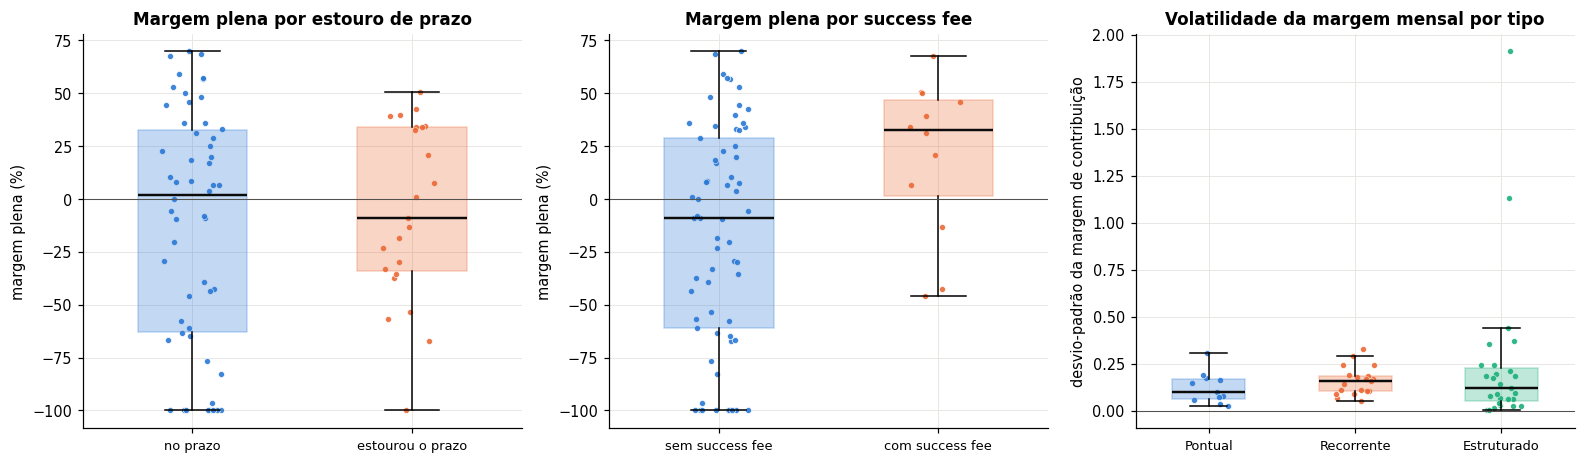

#### Resposta e discussão — pergunta de apoio 3
* **Estouro de prazo:** 23 projetos estouraram o prazo. Sua margem plena ponderada é 14,5% contra 13,8% dos que ficaram no prazo; a diferença não é estatisticamente significativa (p = 0,776), e a correlação entre meses de estouro e margem é ρ = 0,02 (p = 0,889). Não há evidência de que o estouro, isoladamente, corroa a margem. Uma explicação possível (a verificar com a empresa) é que, com honorário mensal fixo, o estouro prolonga receita e custo na mesma proporção.
* **Success fee:** 12 projetos têm success fee; margem plena ponderada 33,0% contra 1,5% nos demais (p = 0,025: a diferença é estatisticamente significativa). Quanto à volatilidade da margem mensal, a diferença é marginal, no limite da significância (p = 0,050). O success fee concentra receita em poucos meses, então **a margem do projeto depende de um evento**, não do ritmo mensal.
* **Tipo de contrato:** a margem difere entre os modelos (Kruskal-Wallis p = 0,002); volatilidade mediana por tipo: Pontual: 0,10, Projeto estruturado: 0,12, Recorrente: 0,16.
* **H4 refutada quanto à margem e confirmada só em parte quanto à volatilidade**: nenhum dos dois fatores reduz a margem; o success fee, na verdade, vem junto com margem maior, mas com resultado mais volátil. O estouro de prazo é um fator secundário para a margem; o que separa os projetos é o modelo de receita e, como mostra a seção 11, o **ticket mensal**.

In [ ]:
def comparar(flag, rotulo, alvo="margem_plena_pct_clip"):
    out = []
    for val in [False, True]:
        g = D[D[flag] == val]
        out.append(dict(grupo=f"{rotulo}: {'sim' if val else 'não'}", projetos=len(g), margem_plena_ponderada=g.margem_plena.sum() / g.receita_bruta.sum() if len(g) else np.nan,
                        margem_plena_mediana=g[alvo].median(), pct_negativos=(g.margem_plena < 0).mean(), volatilidade_mediana=g.volatilidade_mc_pct.median()))
    a, b = D.loc[D[flag] == False, alvo].dropna(), D.loc[D[flag] == True, alvo].dropna()
    pm = stats.mannwhitneyu(a, b).pvalue if min(len(a), len(b)) >= 3 else np.nan
    va, vb = D.loc[D[flag] == False, "volatilidade_mc_pct"].dropna(), D.loc[D[flag] == True, "volatilidade_mc_pct"].dropna()
    pv = stats.mannwhitneyu(va, vb).pvalue if min(len(va), len(vb)) >= 3 else np.nan
    return pd.DataFrame(out), pm, pv
C_est, p_est, pv_est = comparar("fl_estourou_prazo", "estourou o prazo")
C_sf, p_sf, pv_sf = comparar("fl_tem_success_fee", "tem success fee")
def fmt_comp(df):
    o = df.copy(); o["margem_plena_ponderada"] = f_pct(o.margem_plena_ponderada); o["margem_plena_mediana"] = f_pct(o.margem_plena_mediana)
    o["pct_negativos"] = f_pct(o.pct_negativos); o["volatilidade_mediana"] = o.volatilidade_mediana.map(fnum)
    return o.rename(columns={"margem_plena_ponderada": "margem plena (ponderada)", "margem_plena_mediana": "margem plena (mediana)", "pct_negativos": "% c/ margem plena < 0", "volatilidade_mediana": "volatilidade da margem (mediana)"})
fmtp = lambda p_: "n/d" if pd.isna(p_) else ("< 0,001" if p_ < .001 else f"{p_:.3f}".replace(".", ","))
texto(f"**Estouro de prazo** (teste de Mann-Whitney: margem p = {fmtp(p_est)}; volatilidade p = {fmtp(pv_est)})"); tabela(fmt_comp(C_est))
texto(f"**Dependência de success fee** (Mann-Whitney: margem p = {fmtp(p_sf)}; volatilidade p = {fmtp(pv_sf)})"); tabela(fmt_comp(C_sf))
rho_est, p_rho_est = stats.spearmanr(D[["estouro_meses", "margem_plena_pct_clip"]].dropna().estouro_meses, D[["estouro_meses", "margem_plena_pct_clip"]].dropna().margem_plena_pct_clip)
kw_t = stats.kruskal(*[g.margem_plena_pct_clip.dropna() for _, g in D.groupby("grupo_tipo") if len(g) >= 3])
vol_t = D.groupby("grupo_tipo").volatilidade_mc_pct.median()
RES.update(p_est=p_est, p_sf=p_sf, pv_est=pv_est, pv_sf=pv_sf, rho_est=float(rho_est), p_rho_est=float(p_rho_est), kw_tipo_p=float(kw_t.pvalue),
           mp_est_sim=float(C_est.iloc[1].margem_plena_ponderada), mp_est_nao=float(C_est.iloc[0].margem_plena_ponderada),
           mp_sf_sim=float(C_sf.iloc[1].margem_plena_ponderada), mp_sf_nao=float(C_sf.iloc[0].margem_plena_ponderada), n_est=int(C_est.iloc[1].projetos), n_sf=int(C_sf.iloc[1].projetos))

fig, axs = plt.subplots(1, 3, figsize=(14.5, 4.3))
def caixa_pontos(ax, dados, rotulos, titulo, ylab, cores):
    bp = ax.boxplot(dados, positions=range(len(dados)), widths=.5, patch_artist=True, showfliers=False, medianprops=dict(color="#0b0b0b", lw=1.6))
    for patch, cor in zip(bp["boxes"], cores): patch.set_facecolor(cor); patch.set_alpha(.28); patch.set_edgecolor(cor)
    rng = np.random.default_rng(SEMENTE)
    for i, (d, cor) in enumerate(zip(dados, cores)): ax.scatter(i + rng.uniform(-.14, .14, len(d)), d, s=16, color=cor, alpha=.9, edgecolor="white", linewidth=.5)
    ax.set_xticks(range(len(dados))); ax.set_xticklabels(rotulos, fontsize=8.5); ax.set_title(titulo); ax.set_ylabel(ylab); ax.axhline(0, color="#52514e", lw=.7)
g_ = lambda f, v, c="margem_plena_pct_clip": D.loc[D[f] == v, c].dropna() * (100 if "pct" in c else 1)
caixa_pontos(axs[0], [g_("fl_estourou_prazo", False), g_("fl_estourou_prazo", True)], ["no prazo", "estourou o prazo"], "Margem plena por estouro de prazo", "margem plena (%)", [AZUL, LARANJA])
caixa_pontos(axs[1], [g_("fl_tem_success_fee", False), g_("fl_tem_success_fee", True)], ["sem success fee", "com success fee"], "Margem plena por success fee", "margem plena (%)", [AZUL, LARANJA])
tt = ["Pontual", "Recorrente", "Projeto estruturado"]
caixa_pontos(axs[2], [D.loc[D.grupo_tipo == t, "volatilidade_mc_pct"].dropna() for t in tt], ["Pontual", "Recorrente", "Estruturado"], "Volatilidade da margem mensal por tipo", "desvio-padrão da margem de contribuição", [AZUL, LARANJA, VERDE])
plt.tight_layout(); salvar_fig("fig06_prazo_modelo", "Prazo e modelo de receita"); plt.show()
figura("fig06_prazo_modelo", "Margem plena por estouro de prazo e success fee; volatilidade por tipo de contrato")

sig = lambda p_: (not pd.isna(p_)) and p_ < .05
def veredito(p_):
    if pd.isna(p_): return "não pôde ser testada (amostra insuficiente)"
    return "é estatisticamente significativa" if p_ < .05 else ("é marginal, no limite da significância" if p_ < .10 else "não é estatisticamente significativa")
sf_maior = RES["mp_sf_sim"] > RES["mp_sf_nao"]; est_maior = RES["mp_est_sim"] > RES["mp_est_nao"]
h4_margem = (sig(p_est) and not est_maior) or (sig(p_sf) and not sf_maior)
h4_vol = (pv_sf < .10 or pv_est < .10) if not (pd.isna(pv_sf) or pd.isna(pv_est)) else False
if h4_margem: veredito_h4 = "**H4 confirmada** quanto à redução de margem."
elif h4_vol: veredito_h4 = "**H4 refutada quanto à margem e confirmada só em parte quanto à volatilidade**: nenhum dos dois fatores reduz a margem; o success fee, na verdade, vem junto com margem maior, mas com resultado mais volátil."
else: veredito_h4 = "**H4 refutada** com os dados disponíveis."
texto(f"""#### Resposta e discussão — pergunta de apoio 3
* **Estouro de prazo:** {RES['n_est']} projetos estouraram o prazo. Sua margem plena ponderada é {pct(RES['mp_est_sim'])} contra {pct(RES['mp_est_nao'])} dos que ficaram no prazo; a diferença {veredito(p_est)} (p = {fmtp(p_est)}), e a correlação entre meses de estouro e margem é ρ = {fnum(rho_est)} (p = {fmtp(p_rho_est)}). {'O estouro acompanha margens piores.' if h4_margem and sig(p_est) else 'Não há evidência de que o estouro, isoladamente, corroa a margem. Uma explicação possível (a verificar com a empresa) é que, com honorário mensal fixo, o estouro prolonga receita e custo na mesma proporção.'}
* **Success fee:** {RES['n_sf']} projetos têm success fee; margem plena ponderada {pct(RES['mp_sf_sim'])} contra {pct(RES['mp_sf_nao'])} nos demais (p = {fmtp(p_sf)}: a diferença {veredito(p_sf)}). Quanto à volatilidade da margem mensal, a diferença {veredito(pv_sf)} (p = {fmtp(pv_sf)}). O success fee concentra receita em poucos meses, então **a margem do projeto depende de um evento**, não do ritmo mensal.
* **Tipo de contrato:** a margem difere entre os modelos (Kruskal-Wallis p = {fmtp(kw_t.pvalue)}); volatilidade mediana por tipo: {', '.join(f'{k}: {fnum(v)}' for k, v in vol_t.items())}.
* {veredito_h4} O estouro de prazo é um fator secundário para a margem; o que separa os projetos é o modelo de receita e, como mostra a seção 11, o **ticket mensal**.""")

## 11. Pergunta direcionadora — o que mais explica as diferenças de margem?
Duas leituras complementares, ambas sobre os **{n} projetos com receita na janela**: (i) **associação individual** de cada característica com a margem (testes não paramétricos, adequados à amostra pequena e às margens assimétricas) e (ii) **contribuição de cada grupo de características** para prever a margem fora da amostra (validação cruzada repetida). A margem plena % é limitada a −100% nos modelos para que poucos projetos de receita ínfima não dominem o resultado. As conclusões são **associações, não causalidade**.

**11.1 Associação de cada característica com a margem** (efeito = ε² de Kruskal-Wallis para categóricas e ρ² de Spearman para numéricas: fração da variação nos postos da margem associada à característica)

,característica,tipo,efeito — margem plena %,p — margem plena %,efeito — margem de contribuição %,p — margem de contribuição %
0,Receita mensal média (ticket),numérica,48%,"< 0,001",14%,"< 0,001"
1,Porte (receita mensal),categórica,45%,"< 0,001",17%,"< 0,001"
2,Escopo,categórica,22%,"0,002",7%,"0,116"
3,Valor do contrato,numérica,17%,"< 0,001",3%,"0,162"
4,Tipo de contrato,categórica,14%,"0,002",2%,"0,177"
5,Área,categórica,10%,"0,003",1%,"0,170"
6,Prazo planejado (meses),numérica,10%,"0,006",8%,"0,015"
7,Nº de níveis na equipe,numérica,9%,"0,008",13%,"0,001"
8,Alocação média (FTE),numérica,6%,"0,035",30%,"< 0,001"
9,Success fee,categórica,5%,"0,025",0%,"0,757"


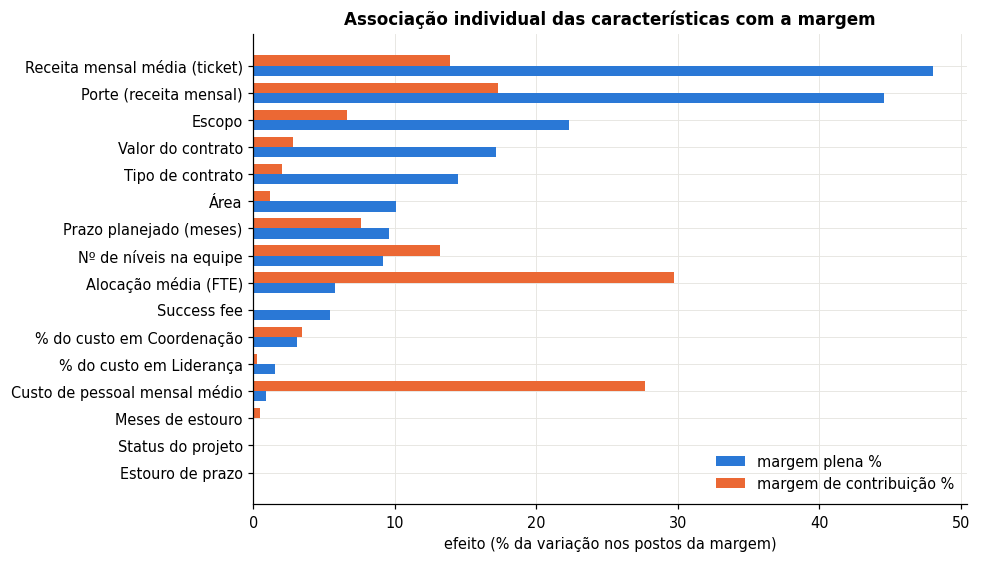

In [ ]:
D = M[M.receita_bruta > 0].copy()
D["receita_mensal_media_log"] = np.log(D.receita_mensal_media.clip(lower=1))
D["valor_contrato_log"] = np.log1p(D.valor_contrato)
D["fl_estourou_prazo_i"], D["fl_tem_success_fee_i"] = D.fl_estourou_prazo.astype(int), D.fl_tem_success_fee.astype(int)
CAT = {"area": "Área", "grupo_tipo": "Tipo de contrato", "escopo_grupo": "Escopo", "faixa_porte": "Porte (receita mensal)", "fl_estourou_prazo": "Estouro de prazo",
       "fl_tem_success_fee": "Success fee", "status": "Status do projeto"}
NUM = {"receita_mensal_media": "Receita mensal média (ticket)", "valor_contrato": "Valor do contrato", "prazo_planejado_meses": "Prazo planejado (meses)", "estouro_meses": "Meses de estouro",
       "alocacao_fte_media": "Alocação média (FTE)", "share_lideranca": "% do custo em Liderança", "share_coordenacao": "% do custo em Coordenação",
       "n_niveis_equipe": "Nº de níveis na equipe", "custo_pessoal_mensal_medio": "Custo de pessoal mensal médio"}
ALVOS = {"margem_plena_pct_clip": "margem plena %", "margem_contribuicao_pct": "margem de contribuição %"}
def efeito_cat(col, alvo):
    g = [x[alvo].dropna().values for _, x in D.groupby(col) if x[alvo].notna().sum() >= 3]
    n_ = sum(len(x) for x in g); k = len(g)
    if k < 2: return np.nan, np.nan
    H, p_ = stats.kruskal(*g); return max(0.0, (H - k + 1) / (n_ - k)), p_
def efeito_num(col, alvo):
    x = D[[col, alvo]].dropna(); rho, p_ = stats.spearmanr(x[col], x[alvo]); return rho ** 2, p_
rows_ = []
for col, nm in {**CAT, **NUM}.items():
    r = dict(característica=nm, tipo="categórica" if col in CAT else "numérica")
    for alvo, nmal in ALVOS.items():
        e, p_ = (efeito_cat if col in CAT else efeito_num)(col, alvo); r[f"efeito — {nmal}"], r[f"p — {nmal}"] = e, p_
    rows_.append(r)
ASSOC = pd.DataFrame(rows_).sort_values("efeito — margem plena %", ascending=False).reset_index(drop=True)
ASSOC_F = ASSOC.copy()
for c_ in [c for c in ASSOC.columns if c.startswith("efeito")]: ASSOC_F[c_] = ASSOC[c_].map(lambda v: pct(v, 0))
for c_ in [c for c in ASSOC.columns if c.startswith("p —")]: ASSOC_F[c_] = ASSOC[c_].map(fmtp)
texto("**11.1 Associação de cada característica com a margem** (efeito = ε² de Kruskal-Wallis para categóricas e ρ² de Spearman para numéricas: fração da variação nos postos da margem associada à característica)")
tabela(ASSOC_F)
fig, ax = plt.subplots(figsize=(9, 5.2)); y = np.arange(len(ASSOC)); h = .38
ax.barh(y + h / 2, ASSOC["efeito — margem plena %"] * 100, h, color=AZUL, label="margem plena %")
ax.barh(y - h / 2, ASSOC["efeito — margem de contribuição %"] * 100, h, color=LARANJA, label="margem de contribuição %")
ax.set_yticks(y); ax.set_yticklabels(ASSOC["característica"]); ax.invert_yaxis(); ax.set_xlabel("efeito (% da variação nos postos da margem)")
ax.set_title("Associação individual das características com a margem"); ax.legend(loc="lower right")
plt.tight_layout(); salvar_fig("fig07_associacao", "Associação das características com a margem"); plt.show()
figura("fig07_associacao", "Associação individual das características com a margem")

**11.2 Contribuição preditiva por grupo de características — margem plena %** (Random Forest, validação cruzada 5×3; R² negativo = o grupo não prevê fora da amostra)

,grupo,R² (CV) só com o grupo,queda no R² ao remover o grupo,R² (CV) modelo completo
2,Valor e porte (ticket),"0,30","0,34","0,28"
1,Escopo,"0,03","-0,00","0,28"
0,Área e tipo de contrato,"-0,06","-0,03","0,28"
3,Prazo,"-0,08","-0,01","0,28"
4,Success fee,"-0,09","-0,01","0,28"
5,Equipe (composição e intensidade),"-0,18","-0,02","0,28"


**11.2 Contribuição preditiva por grupo de características — margem de contribuição %** (Random Forest, validação cruzada 5×3; R² negativo = o grupo não prevê fora da amostra)

,grupo,R² (CV) só com o grupo,queda no R² ao remover o grupo,R² (CV) modelo completo
11,Equipe (composição e intensidade),"0,06","0,36","0,29"
7,Escopo,"-0,09","0,00","0,29"
8,Valor e porte (ticket),"-0,11","0,14","0,29"
6,Área e tipo de contrato,"-0,13","-0,01","0,29"
10,Success fee,"-0,13","0,01","0,29"
9,Prazo,"-0,19","0,04","0,29"


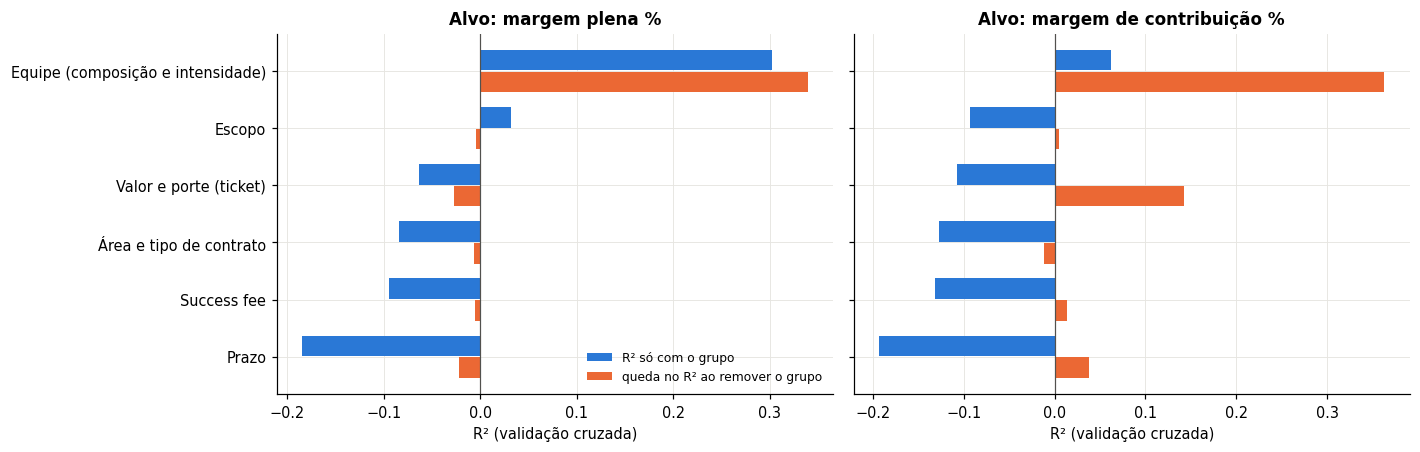

In [ ]:
# 11.2 contribuição por grupo de características (validação cruzada repetida, Random Forest)
GRUPOS = {"Área e tipo de contrato": ["area", "grupo_tipo"], "Escopo": ["escopo_grupo"], "Valor e porte (ticket)": ["receita_mensal_media_log", "valor_contrato_log"],
          "Prazo": ["prazo_planejado_meses", "estouro_meses", "fl_estourou_prazo_i"], "Success fee": ["fl_tem_success_fee_i"],
          "Equipe (composição e intensidade)": ["alocacao_fte_media", "share_lideranca", "share_coordenacao", "share_operacional", "n_niveis_equipe", "custo_pessoal_mensal_medio"]}
def matriz(cols):
    X = D[cols].copy()
    cat = [c for c in cols if X[c].dtype == object or str(X[c].dtype) in ("string", "category", "str", "large_string")]
    X = pd.get_dummies(X, columns=cat, dtype=float)
    return X.fillna(X.median(numeric_only=True)).fillna(0)
def cv_r2(cols, alvo):
    X, yv = matriz(cols), D[alvo].values
    rf = RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.6, random_state=SEMENTE, n_jobs=-1)
    s = cross_val_score(rf, X, yv, cv=RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEMENTE), scoring="r2")
    return s.mean()
todas = [c for g in GRUPOS.values() for c in g]
IMP = []
for alvo, nmal in ALVOS.items():
    m_all = D[alvo].notna().all()
    r2_all = cv_r2(todas, alvo)
    for g, cols in GRUPOS.items():
        r2_so = cv_r2(cols, alvo); r2_sem = cv_r2([c for c in todas if c not in cols], alvo)
        IMP.append(dict(alvo=nmal, grupo=g, r2_so_grupo=r2_so, queda_ao_remover=r2_all - r2_sem, r2_modelo_completo=r2_all))
IMP = pd.DataFrame(IMP)
def tab_imp(nmal):
    t = IMP[IMP.alvo == nmal].sort_values("r2_so_grupo", ascending=False)
    return t.assign(r2_so_grupo=t.r2_so_grupo.map(fnum), queda_ao_remover=t.queda_ao_remover.map(fnum), r2_modelo_completo=t.r2_modelo_completo.map(fnum))[["grupo", "r2_so_grupo", "queda_ao_remover", "r2_modelo_completo"]].rename(
        columns={"r2_so_grupo": "R² (CV) só com o grupo", "queda_ao_remover": "queda no R² ao remover o grupo", "r2_modelo_completo": "R² (CV) modelo completo"})
for alvo, nmal in ALVOS.items():
    texto(f"**11.2 Contribuição preditiva por grupo de características — {nmal}** (Random Forest, validação cruzada 5×3; R² negativo = o grupo não prevê fora da amostra)"); tabela(tab_imp(nmal))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (alvo, nmal) in zip(axs, ALVOS.items()):
    t = IMP[IMP.alvo == nmal].sort_values("r2_so_grupo"); yy = np.arange(len(t))
    ax.barh(yy + .19, t.r2_so_grupo, .36, color=AZUL, label="R² só com o grupo"); ax.barh(yy - .19, t.queda_ao_remover, .36, color=LARANJA, label="queda no R² ao remover o grupo")
    ax.set_yticks(yy); ax.set_yticklabels(t.grupo); ax.axvline(0, color="#52514e", lw=.8); ax.set_title(f"Alvo: {nmal}"); ax.set_xlabel("R² (validação cruzada)")
axs[0].legend(fontsize=8, loc="lower right"); plt.tight_layout(); salvar_fig("fig08_grupos", "Contribuição por grupo"); plt.show()
figura("fig08_grupos", "Contribuição preditiva de cada grupo de características")

In [ ]:
# 11.3 modelo linear interpretável (erros robustos HC3) e 11.4 árvore de decisão
D["tipo_"] = D.grupo_tipo
ols = smf.ols("margem_plena_pct_clip ~ C(tipo_, Treatment('Projeto estruturado')) + receita_mensal_media_log + alocacao_fte_media + share_lideranca + fl_estourou_prazo_i + fl_tem_success_fee_i",
              data=D.dropna(subset=["receita_mensal_media_log", "alocacao_fte_media", "share_lideranca"])).fit(cov_type="HC3")
co = pd.DataFrame({"coeficiente": ols.params, "IC95% inf": ols.conf_int()[0], "IC95% sup": ols.conf_int()[1], "p": ols.pvalues})
co.index = [i.replace("C(tipo_, Treatment('Projeto estruturado'))[T.", "tipo: ").replace("]", " (vs. estruturado)").replace("receita_mensal_media_log", "ln(receita mensal média)").replace("alocacao_fte_media", "alocação média (FTE)")
            .replace("share_lideranca", "% do custo em Liderança").replace("fl_estourou_prazo_i", "estourou o prazo").replace("fl_tem_success_fee_i", "tem success fee") for i in co.index]
co_f = co.reset_index().rename(columns={"index": "termo"});
for c_ in ["coeficiente", "IC95% inf", "IC95% sup"]: co_f[c_] = co_f[c_].map(fnum)
co_f["p"] = co_f.p.map(fmtp)
texto(f"**11.3 Modelo linear (margem plena % ≈ características), erros robustos HC3 — R² = {fnum(ols.rsquared)}, n = {int(ols.nobs)}**"); tabela(co_f)
RES.update(ols_r2=float(ols.rsquared), ols_p_ticket=float(ols.pvalues["receita_mensal_media_log"]), ols_b_ticket=float(ols.params["receita_mensal_media_log"]),
           ols_p_fte=float(ols.pvalues["alocacao_fte_media"]))

XT = D[["receita_mensal_media", "custo_pessoal_mensal_medio", "alocacao_fte_media", "share_lideranca", "share_coordenacao", "n_niveis_equipe", "prazo_planejado_meses", "estouro_meses",
        "fl_tem_success_fee_i"]].copy(); XT["is_estruturado"] = (D.grupo_tipo == "Projeto estruturado").astype(int); XT["is_recorrente"] = (D.grupo_tipo == "Recorrente").astype(int)
XT = XT.fillna(XT.median())
arv = DecisionTreeRegressor(max_depth=3, min_samples_leaf=6, random_state=SEMENTE).fit(XT, D.margem_plena_pct_clip)
regras = export_text(arv, feature_names=list(XT.columns), decimals=1)
RES.update(arv_feat=XT.columns[arv.tree_.feature[0]], arv_thr=float(arv.tree_.threshold[0]), arv_r2=float(arv.score(XT, D.margem_plena_pct_clip)))
texto("**11.4 Regras de decisão (árvore de profundidade 3, ajustada sobre todos os projetos com receita; leitura exploratória)**\n\n```\n" + regras + "```")

**11.3 Modelo linear (margem plena % ≈ características), erros robustos HC3 — R² = 0,50, n = 77**

,termo,coeficiente,IC95% inf,IC95% sup,p
0,Intercept,"-3,72","-5,44","-2,00","< 0,001"
1,tipo: Pontual (vs. estruturado),"0,11","-0,22","0,45","0,513"
2,tipo: Recorrente (vs. estruturado),"-0,07","-0,48","0,33","0,719"
3,ln(receita mensal média),"0,40","0,24","0,56","< 0,001"
4,alocação média (FTE),"-0,57","-1,17","0,02","0,059"
5,% do custo em Liderança,"0,02","-0,52","0,57","0,929"
6,estourou o prazo,"-0,09","-0,27","0,08","0,298"
7,tem success fee,"-0,12","-0,39","0,16","0,407"


**11.4 Regras de decisão (árvore de profundidade 3, ajustada sobre todos os projetos com receita; leitura exploratória)**

```
|--- receita_mensal_media <= 16347.9
|   |--- receita_mensal_media <= 6577.1
|   |   |--- share_lideranca <= 0.0
|   |   |   |--- value: [-0.4]
|   |   |--- share_lideranca >  0.0
|   |   |   |--- value: [-0.9]
|   |--- receita_mensal_media >  6577.1
|   |   |--- alocacao_fte_media <= 0.2
|   |   |   |--- value: [0.0]
|   |   |--- alocacao_fte_media >  0.2
|   |   |   |--- value: [-0.3]
|--- receita_mensal_media >  16347.9
|   |--- n_niveis_equipe <= 3.5
|   |   |--- share_lideranca <= 0.3
|   |   |   |--- value: [0.4]
|   |   |--- share_lideranca >  0.3
|   |   |   |--- value: [0.5]
|   |--- n_niveis_equipe >  3.5
|   |   |--- receita_mensal_media <= 24242.8
|   |   |   |--- value: [-0.1]
|   |   |--- receita_mensal_media >  24242.8
|   |   |   |--- value: [0.3]
```

### 11.5 Da análise à decisão: segmentos, preço-piso, capacidade de equipe e projetos em alerta

In [ ]:
def classif(n_, pctm):
    if n_ < MIN_GRUPO: return "Amostra insuficiente"
    if pctm >= MARGEM_ALVO: return "Priorizar"
    if pctm >= 0: return "Manter, com ajuste de preço"
    return "Reprecificar ou evitar"
D2 = D[D.faixa_porte != "Sem receita na janela"]
sc = D2.groupby(["grupo_tipo", "faixa_porte"]).apply(lambda g: pd.Series({"projetos": len(g), "receita_mensal_mediana": g.receita_mensal_media.median(),
        "margem_plena_pct": g.margem_plena.sum() / g.receita_bruta.sum(), "pct_negativos": (g.margem_plena < 0).mean()})).reset_index()
sc["recomendação"] = [classif(n_, p_) for n_, p_ in zip(sc.projetos, sc.margem_plena_pct)]
SC = sc.copy(); SC["receita_mensal_mediana"] = f_brl(SC.receita_mensal_mediana); SC["margem_plena_pct"] = f_pct(SC.margem_plena_pct); SC["pct_negativos"] = f_pct(SC.pct_negativos)
SC = SC.rename(columns={"grupo_tipo": "tipo de contrato", "faixa_porte": "porte", "receita_mensal_mediana": "ticket mensal mediano", "margem_plena_pct": "margem plena", "pct_negativos": "% projetos c/ margem < 0"})
texto(f"**Scorecard de segmentos para a originação** (regra: ≥ {pct(MARGEM_ALVO, 0)} priorizar; 0–{pct(MARGEM_ALVO, 0)} manter com ajuste de preço; < 0 reprecificar ou evitar; menos de {MIN_GRUPO} projetos = amostra insuficiente)"); tabela(SC)
RES["scorecard"] = sc

# preço-piso por tipo de contrato (base: meses-projeto com receita e custo na janela)
rows_ = []
for g_, x in PM.groupby("grupo_tipo"):
    c_, d_, fee_ = x.custo_total_projeto.median(), x.desp_indireta_rateada.median(), x.receita_bruta.median()
    rows_.append(dict(grupo_tipo=g_, meses_projeto=len(x), custo_mensal=c_, desp_indireta=d_, honorario_atual=fee_, piso_equilibrio=(c_ + d_) / base_calc,
                      piso_margem_alvo=(c_ + d_) / (base_calc - MARGEM_ALVO), pct_abaixo_equilibrio=(x.receita_bruta < (x.custo_total_projeto + x.desp_indireta_rateada) / base_calc).mean()))
PISO = pd.DataFrame(rows_); PISO["gap"] = PISO.piso_margem_alvo / PISO.honorario_atual - 1
PF = PISO.copy()
for c_ in ["custo_mensal", "desp_indireta", "honorario_atual", "piso_equilibrio", "piso_margem_alvo"]: PF[c_] = f_brl(PF[c_])
PF["pct_abaixo_equilibrio"] = f_pct(PF.pct_abaixo_equilibrio); PF["gap"] = PF.gap.map(lambda v: f"{v * 100:+.0f}%")
PF = PF.rename(columns={"grupo_tipo": "tipo de contrato", "meses_projeto": "meses-projeto", "custo_mensal": "custo de equipe mensal (mediana)", "desp_indireta": "despesa indireta rateada (mediana)",
                        "honorario_atual": "honorário mensal atual (mediana)", "piso_equilibrio": "preço-piso: margem plena = 0", "piso_margem_alvo": f"preço-piso: margem plena = {pct(MARGEM_ALVO, 0)}",
                        "pct_abaixo_equilibrio": "% dos meses abaixo do equilíbrio", "gap": "alta necessária p/ meta"})
texto("**Preço-piso mensal por tipo de contrato** = (custo de equipe + despesa indireta) ÷ (1 − impostos − comissão − margem desejada)"); tabela(PF)
RES["piso"] = PISO

# capacidade de equipe por faixa de honorário
fte_cost = float((PM.custo_pessoal / PM.alocacao_fte.replace(0, np.nan)).median())
qs = PM.receita_bruta.quantile([.25, .5, .75, .9]).values
cap = pd.DataFrame({"honorário mensal": ["P25", "P50", "P75", "P90"], "valor": qs})
cap["custo de equipe máximo (margem-alvo)"] = qs * (base_calc - MARGEM_ALVO) - d_med
cap["FTE máximo"] = cap["custo de equipe máximo (margem-alvo)"] / fte_cost
CAP = cap.copy(); CAP["valor"] = f_brl(CAP.valor); CAP["custo de equipe máximo (margem-alvo)"] = CAP["custo de equipe máximo (margem-alvo)"].map(lambda v: brl(v) if v > 0 else "inviável")
CAP["FTE máximo"] = cap["FTE máximo"].map(lambda v: fnum(v) if v > 0 else "—")
texto(f"**Capacidade de equipe**: quanto custo de equipe (e quantos FTE, a {brl(fte_cost)} por FTE-mês, mediana) cada faixa de honorário comporta mantendo margem plena de {pct(MARGEM_ALVO, 0)}"); tabela(CAP)
RES.update(fte_cost=fte_cost, cap=cap)

# projetos ativos em alerta
pf_map = dict(zip(PISO.grupo_tipo, PISO.piso_margem_alvo))
al = M[(M.status == "Ativo") & ((M.receita_bruta > 0) | (M.custo_total_projeto > 0))].copy()
al["piso"] = al.grupo_tipo.map(pf_map)
def acao(r):
    if r.receita_bruta <= 0: return "Sem receita na janela: faturar, encerrar ou pausar alocação"
    if r.receita_mensal_media < r.piso * .8 and r.alocacao_fte_media > D.alocacao_fte_media.median(): return "Honorário abaixo do piso e equipe acima da mediana: renegociar e reduzir intensidade"
    if r.receita_mensal_media < r.piso * .8: return "Honorário abaixo do piso: renegociar ou reprecificar"
    if r.alocacao_fte_media > D.alocacao_fte_media.quantile(.75): return "Intensidade de equipe alta: revisar alocação"
    if r.fl_estourou_prazo: return "Prazo estourado: renegociar aditivo/escopo"
    return "Monitorar"
al["ação sugerida"] = al.apply(acao, axis=1)
AL = al[al.margem_plena < 0].sort_values("margem_plena").head(15)[["projeto", "grupo_tipo", "faixa_porte", "receita_mensal_media", "custo_pessoal_mensal_medio", "margem_plena", "margem_plena_pct", "ação sugerida"]].copy()
AL["receita_mensal_media"] = f_brl(AL.receita_mensal_media); AL["custo_pessoal_mensal_medio"] = f_brl(AL.custo_pessoal_mensal_medio); AL["margem_plena"] = f_brl(AL.margem_plena); AL["margem_plena_pct"] = f_pct(AL.margem_plena_pct)
AL = AL.rename(columns={"projeto": "projeto (letra)", "grupo_tipo": "tipo", "faixa_porte": "porte", "receita_mensal_media": "ticket mensal", "custo_pessoal_mensal_medio": "custo de equipe mensal", "margem_plena": "margem plena (R$)", "margem_plena_pct": "margem plena %"})
texto(f"**Projetos *ativos* com maior prejuízo de margem plena na janela (15 piores de {int(((al.margem_plena < 0)).sum())} ativos com margem plena negativa)** — as letras podem ser traduzidas pela empresa com a legenda privada"); tabela(AL)
RES["n_alerta"] = int((al.margem_plena < 0).sum()); RES["n_ativos_ref"] = int(len(al))
RES["alerta_acoes"] = al[al.margem_plena < 0]["ação sugerida"].value_counts().to_dict()
RES["alerta_mp"] = float(al[al.margem_plena < 0].margem_plena.sum())

**Scorecard de segmentos para a originação** (regra: ≥ 30% priorizar; 0–30% manter com ajuste de preço; < 0 reprecificar ou evitar; menos de 5 projetos = amostra insuficiente)

,tipo de contrato,porte,projetos,ticket mensal mediano,margem plena,% projetos c/ margem < 0,recomendação
0,Pontual,Porte G,3.0,R$ 21.254,"34,2%","0,0%",Amostra insuficiente
1,Pontual,Porte M,10.0,R$ 15.940,"-10,4%","60,0%",Reprecificar ou evitar
2,Pontual,Porte P,7.0,R$ 10.627,"-27,4%","71,4%",Reprecificar ou evitar
3,Projeto estruturado,Porte G,21.0,R$ 33.616,"38,0%","9,5%",Priorizar
4,Projeto estruturado,Porte M,10.0,R$ 15.940,"-17,1%","60,0%",Reprecificar ou evitar
5,Projeto estruturado,Porte P,5.0,R$ 6.376,"-33,9%","60,0%",Reprecificar ou evitar
6,Recorrente,Porte G,2.0,R$ 23.911,"53,9%","0,0%",Amostra insuficiente
7,Recorrente,Porte M,3.0,R$ 13.284,"-20,4%","66,7%",Amostra insuficiente
8,Recorrente,Porte P,16.0,R$ 5.048,"-62,7%","93,8%",Reprecificar ou evitar


**Preço-piso mensal por tipo de contrato** = (custo de equipe + despesa indireta) ÷ (1 − impostos − comissão − margem desejada)

,tipo de contrato,meses-projeto,custo de equipe mensal (mediana),despesa indireta rateada (mediana),honorário mensal atual (mediana),preço-piso: margem plena = 0,preço-piso: margem plena = 30%,% dos meses abaixo do equilíbrio,alta necessária p/ meta
0,Pontual,48,R$ 2.884,R$ 7.112,R$ 15.940,R$ 13.241,R$ 21.971,"45,8%",+38%
1,Projeto estruturado,122,R$ 3.929,R$ 7.112,R$ 13.284,R$ 14.624,R$ 24.266,"60,7%",+83%
2,Recorrente,96,R$ 1.913,R$ 7.129,R$ 6.376,R$ 11.977,R$ 19.873,"91,7%",+212%


**Capacidade de equipe**: quanto custo de equipe (e quantos FTE, a R$ 10.446 por FTE-mês, mediana) cada faixa de honorário comporta mantendo margem plena de 30%

,honorário mensal,valor,custo de equipe máximo (margem-alvo),FTE máximo
0,P25,R$ 7.970,inviável,—
1,P50,R$ 10.627,inviável,—
2,P75,R$ 15.940,R$ 141,"0,01"
3,P90,R$ 21.254,R$ 2.558,"0,24"


**Projetos *ativos* com maior prejuízo de margem plena na janela (15 piores de 24 ativos com margem plena negativa)** — as letras podem ser traduzidas pela empresa com a legenda privada

,projeto (letra),tipo,porte,ticket mensal,custo de equipe mensal,margem plena (R$),margem plena %,ação sugerida
21,V,Projeto estruturado,Sem receita na janela,—,R$ 1.855,-R$ 75.804,—,"Sem receita na janela: faturar, encerrar ou pausar alocação"
25,Z,Projeto estruturado,Sem receita na janela,—,R$ 1.767,-R$ 66.184,—,"Sem receita na janela: faturar, encerrar ou pausar alocação"
3,D,Projeto estruturado,Porte M,R$ 13.284,R$ 6.615,-R$ 53.709,"-67,4%",Honorário abaixo do piso e equipe acima da mediana: renegociar e reduzir int...
50,AY,Recorrente,Porte P,R$ 3.985,R$ 1.994,-R$ 52.845,"-165,8%",Honorário abaixo do piso: renegociar ou reprecificar
37,AL,Projeto estruturado,Sem receita na janela,—,R$ 4.373,-R$ 48.275,—,"Sem receita na janela: faturar, encerrar ou pausar alocação"
17,R,Projeto estruturado,Sem receita na janela,—,R$ 891,-R$ 41.178,—,"Sem receita na janela: faturar, encerrar ou pausar alocação"
48,AW,Recorrente,Porte P,R$ 3.985,R$ 1.438,-R$ 39.815,"-124,9%",Honorário abaixo do piso: renegociar ou reprecificar
41,AP,Projeto estruturado,Sem receita na janela,—,R$ 1.164,-R$ 35.436,—,"Sem receita na janela: faturar, encerrar ou pausar alocação"
80,CC,Recorrente,Porte M,R$ 11.570,R$ 8.245,-R$ 35.391,"-61,2%",Honorário abaixo do piso e equipe acima da mediana: renegociar e reduzir int...
61,BJ,Recorrente,Porte P,R$ 5.314,R$ 788,-R$ 35.173,"-82,7%",Honorário abaixo do piso: renegociar ou reprecificar


In [ ]:
# 11.6 cenário ilustrativo: reprecificar o que está abaixo do equilíbrio
abaixo = PM[PM.receita_bruta < (PM.custo_total_projeto + PM.desp_indireta_rateada) / base_calc].copy()
mc_ab, mp_ab, di_ab = float(abaixo.margem_contribuicao.sum()), float(abaixo.margem_plena.sum()), float(abaixo.desp_indireta_rateada.sum())
ret_min = mc_ab / di_ab if di_ab else np.nan
cen = []
for r_ in [1.0, .75, .5]:
    cen.append({"retenção dos projetos reprecificados": pct(r_, 0), "variação da margem plena na janela": brl(r_ * (-mp_ab) + (1 - r_) * (-mc_ab)),
                "em % da receita da carteira": pct((r_ * (-mp_ab) + (1 - r_) * (-mc_ab)) / RES["n_proj"] * 0 + (r_ * (-mp_ab) + (1 - r_) * (-mc_ab)) / tot.rec)})
RES.update(n_abaixo=len(abaixo), pct_abaixo=len(abaixo) / len(PM), mp_ab=mp_ab, mc_ab=mc_ab, ret_min=ret_min, gan100=-mp_ab)
texto(f"""**11.6 Cenário ilustrativo — reprecificar ao ponto de equilíbrio os meses-projeto que hoje ficam abaixo dele**
{len(abaixo)} dos {len(PM)} meses-projeto ({pct(len(abaixo) / len(PM), 0)}) faturam menos do que o necessário para empatar. Se cada um fosse reprecificado ao equilíbrio, o ganho de margem plena na janela seria de {brl(-mp_ab)} **se nenhum cliente saísse**. Se um cliente reprecificado sair, a empresa perde a margem de contribuição dele ({brl(mc_ab / max(len(abaixo), 1))} por mês-projeto, em média) e **a despesa indireta continua**. A conta fecha (ganho ≥ 0) desde que a retenção seja de pelo menos **{pct(ret_min, 0) if not pd.isna(ret_min) else '—'}**.""")
tabela(pd.DataFrame(cen))

**11.6 Cenário ilustrativo — reprecificar ao ponto de equilíbrio os meses-projeto que hoje ficam abaixo dele**  
184 dos 266 meses-projeto (69%) faturam menos do que o necessário para empatar. Se cada um fosse reprecificado ao equilíbrio, o ganho de margem plena na janela seria de R$ 932.707 **se nenhum cliente saísse**. Se um cliente reprecificado sair, a empresa perde a margem de contribuição dele (R$ 2.585 por mês-projeto, em média) e **a despesa indireta continua**. A conta fecha (ganho ≥ 0) desde que a retenção seja de pelo menos **34%**.

,retenção dos projetos reprecificados,variação da margem plena na janela,em % da receita da carteira
0,100%,R$ 932.707,"15,7%"
1,75%,R$ 580.637,"9,7%"
2,50%,R$ 228.567,"3,8%"


In [ ]:
# 11.7 sensibilidade às decisões de modelagem
VARIANTES = {"Base (rateio igual por projeto)": {}, "Rateio proporcional ao custo": dict(desp_col="desp_indireta_rateio_custo"),
             "Rateio proporcional à receita": dict(desp_col="desp_indireta_rateio_receita"), "Sem meses com receita e sem custo": dict(excluir_receita_sem_custo=True), "Sem projetos com success fee": "nosf"}
sens = []; ordem_base = None
for nome, kw in VARIANTES.items():
    mv = construir_mart(sm_, silver_custo, _proj_attr, **({} if kw == "nosf" else kw))
    if kw == "nosf": mv = mv[~mv.fl_tem_success_fee]
    dv = mv[mv.receita_bruta > 0]
    por_tipo = dv.groupby("grupo_tipo").apply(lambda g: g.margem_plena.sum() / g.receita_bruta.sum())
    ordem = list(por_tipo.sort_values(ascending=False).index); ordem_base = ordem_base or ordem
    xx = dv[["receita_mensal_media", "margem_plena_pct_clip"]].dropna(); rho_t, _ = stats.spearmanr(xx.receita_mensal_media, xx.margem_plena_pct_clip)
    kwp = stats.kruskal(*[g.margem_plena_pct_clip.dropna() for _, g in dv.groupby("grupo_tipo") if len(g) >= 3]).pvalue
    sens.append({"cenário": nome, "margem plena da carteira": pct(dv.margem_plena.sum() / dv.receita_bruta.sum()), "estruturado": pct(por_tipo.get("Projeto estruturado")), "pontual": pct(por_tipo.get("Pontual")),
                 "recorrente": pct(por_tipo.get("Recorrente")), "ρ (ticket × margem)": fnum(rho_t), "p (tipo de contrato)": fmtp(kwp), "ranking de tipos igual ao base": "sim" if ordem == ordem_base else "não", "_rho": rho_t})
SENS = pd.DataFrame(sens)
texto("**11.7 Sensibilidade das conclusões às decisões de modelagem**"); tabela(SENS.drop(columns="_rho"))
rho_base, rho_rec = float(SENS._rho.iloc[0]), float(SENS._rho.iloc[2])
RES.update(rho_base=rho_base, rho_rateio_receita=rho_rec, ranking_estavel=bool((SENS["ranking de tipos igual ao base"] == "sim").all()))
texto(f"""**Leitura.** {'O ranking dos tipos de contrato é estável em todas as variações.' if RES['ranking_estavel'] else 'O ranking dos tipos de contrato muda em alguma variação, então ele é sensível à regra de rateio ou à base.'} A relação entre ticket e margem plena (ρ = {fnum(rho_base)} na base) **{'permanece' if abs(rho_rec) > .4 else 'enfraquece muito'} quando as despesas indiretas são rateadas proporcionalmente à receita (ρ = {fnum(rho_rec)})**. Isso é esperado: parte do "efeito do ticket" é consequência de tratar a despesa indireta como um valor igual por projeto. A decisão de *como ratear* é gerencial, e por isso a **margem de contribuição** — que não depende dessa regra — deve ser a régua para escolher projetos, enquanto a **margem plena** serve para definir o piso de preço e o tamanho mínimo de projeto que paga a estrutura.""")

**11.7 Sensibilidade das conclusões às decisões de modelagem**

,cenário,margem plena da carteira,estruturado,pontual,recorrente,ρ (ticket × margem),p (tipo de contrato),ranking de tipos igual ao base
0,Base (rateio igual por projeto),"14,1%","27,2%","-2,9%","-29,5%","0,69","0,002",sim
1,Rateio proporcional ao custo,"11,3%","15,8%","5,1%","-3,1%","0,37","0,173",sim
2,Rateio proporcional à receita,"6,3%","9,1%","1,1%","-1,4%","0,31","0,302",sim
3,Sem meses com receita e sem custo,"4,5%","20,4%","-11,2%","-59,1%","0,88","< 0,001",sim
4,Sem projetos com success fee,"1,5%","19,7%","-2,9%","-29,5%","0,64","0,009",sim


**Leitura.** O ranking dos tipos de contrato é estável em todas as variações. A relação entre ticket e margem plena (ρ = 0,69 na base) **enfraquece muito quando as despesas indiretas são rateadas proporcionalmente à receita (ρ = 0,31)**. Isso é esperado: parte do "efeito do ticket" é consequência de tratar a despesa indireta como um valor igual por projeto. A decisão de *como ratear* é gerencial, e por isso a **margem de contribuição** — que não depende dessa regra — deve ser a régua para escolher projetos, enquanto a **margem plena** serve para definir o piso de preço e o tamanho mínimo de projeto que paga a estrutura.

### 11.8 Resposta à pergunta direcionadora

In [ ]:
e = ASSOC.set_index("característica")
top_pl = IMP[IMP.alvo == "margem plena %"].sort_values("queda_ao_remover", ascending=False).iloc[0]
top_mc = IMP[IMP.alvo == "margem de contribuição %"].sort_values("queda_ao_remover", ascending=False).iloc[0]
e_tipo, e_esc = float(e.loc["Tipo de contrato", "efeito — margem plena %"]), float(e.loc["Escopo", "efeito — margem plena %"])
e_ticket = float(e.loc["Receita mensal média (ticket)", "efeito — margem plena %"])
dobro = RES["ols_b_ticket"] * np.log(2) * 100
RES.update(top_pl=top_pl.grupo, top_mc=top_mc.grupo, e_tipo=e_tipo, e_esc=e_esc, e_ticket=e_ticket, dobro_pp=dobro)
h2_ok = e_tipo > e_esc
h3_ok = top_mc.grupo.startswith("Equipe")
texto(f"""**Resposta.** Entre as características testadas, o que **mais explica a diferença de margem plena entre os projetos é o *ticket mensal* (valor e porte)**: sozinho, esse grupo é o único que prevê a margem fora da amostra (R² ≈ {fnum(IMP[(IMP.alvo == 'margem plena %') & (IMP.grupo.str.startswith('Valor'))].r2_so_grupo.iloc[0])}), responde por {pct(e_ticket, 0)} da variação nos postos da margem plena e, no modelo linear, **cada vez que o honorário mensal dobra a margem plena sobe cerca de {dobro:.0f} pontos percentuais** (p = {fmtp(RES['ols_p_ticket'])}), **mantidos constantes** tipo de contrato, equipe, prazo e success fee. Depois de controlar pelo ticket, **tipo de contrato, área, estouro de prazo, success fee e peso da liderança deixam de ser significativos** — parte do que parecia efeito de "tipo" ou "área" era, na verdade, efeito de ticket (os projetos recorrentes e pontuais da A2 são os de menor valor).

Já a **margem de contribuição** (antes das despesas indiretas) é praticamente igual entre áreas e tipos ({pct(RES['a1_mc'])} na A1 contra {pct(RES['a2_mc'])} na A2) e é explicada sobretudo pela **intensidade de equipe** ({top_mc.grupo}; queda de R² de {fnum(top_mc.queda_ao_remover)} ao removê-la).

**Hipóteses.** **H1:** {'confirmada' if RES['top5_share'] > .4 or RES['n80'] / RES['n_pos'] < .4 else 'parcialmente confirmada'} (poucos projetos geram a maior parte da margem positiva). **H2:** {'confirmada' if h2_ok else 'refutada'} — {'tipo de contrato' if h2_ok else 'escopo'} está mais associado à margem plena (ε² de {pct(max(e_tipo, e_esc), 0)}) do que {'escopo' if h2_ok else 'tipo de contrato'} ({pct(min(e_tipo, e_esc), 0)}), e ambos perdem relevância quando se controla o ticket. **H3:** {'confirmada para a margem de contribuição' if h3_ok else 'não confirmada'}; para a margem plena o ticket pesa mais que a equipe. **H4:** ver seção 10.3.

**O que isso indica para a decisão.**
1. **Originação — comece pelo preço, não pelo tipo de projeto.** O preço-piso mensal para margem plena de {pct(MARGEM_ALVO, 0)} fica entre {brl(PISO.piso_margem_alvo.min())} e {brl(PISO.piso_margem_alvo.max())} por tipo de contrato, enquanto o honorário mediano atual é de {brl(fee_med)}. **{pct(RES['pct_abaixo'], 0)} dos meses-projeto faturam abaixo do equilíbrio.** Priorizar segmentos de porte G (margem plena {pct(float(sc[(sc.grupo_tipo == 'Projeto estruturado') & (sc.faixa_porte == 'Porte G')].margem_plena_pct.iloc[0]) if ((sc.grupo_tipo == 'Projeto estruturado') & (sc.faixa_porte == 'Porte G')).any() else np.nan)} nos estruturados) e reprecificar ou condicionar a aceitação de projetos pequenos, sobretudo os recorrentes de porte P.
2. **Alocação de equipe — dimensione pelo honorário.** Use a tabela de capacidade: com honorários abaixo do P75 da carteira, o custo de equipe que preserva a margem-alvo é praticamente nulo; a equipe é "cara demais" para o ticket, e não o contrário.
3. **Ação imediata.** {RES['n_alerta']} projetos ativos têm margem plena negativa na janela ({brl(RES['alerta_mp'])} no total); {RES['n_sem_rec']} projetos tiveram custo sem receita ({brl(RES['mp_sem_rec'])}). A lista de alerta (11.5) já traz a ação sugerida por projeto.
4. **Governança dos dados.** Corrigir o cenário 2 da planilha, conciliar a receita por projeto com a receita-base e registrar custos de jan/fev e a partir de novembro tornam o acompanhamento mensal confiável.""")

**Resposta.** Entre as características testadas, o que **mais explica a diferença de margem plena entre os projetos é o *ticket mensal* (valor e porte)**: sozinho, esse grupo é o único que prevê a margem fora da amostra (R² ≈ 0,30), responde por 48% da variação nos postos da margem plena e, no modelo linear, **cada vez que o honorário mensal dobra a margem plena sobe cerca de 28 pontos percentuais** (p = < 0,001), **mantidos constantes** tipo de contrato, equipe, prazo e success fee. Depois de controlar pelo ticket, **tipo de contrato, área, estouro de prazo, success fee e peso da liderança deixam de ser significativos** — parte do que parecia efeito de "tipo" ou "área" era, na verdade, efeito de ticket (os projetos recorrentes e pontuais da A2 são os de menor valor).

Já a **margem de contribuição** (antes das despesas indiretas) é praticamente igual entre áreas e tipos (53,1% na A1 contra 50,7% na A2) e é explicada sobretudo pela **intensidade de equipe** (Equipe (composição e intensidade); queda de R² de 0,36 ao removê-la).

**Hipóteses.** **H1:** confirmada (poucos projetos geram a maior parte da margem positiva). **H2:** refutada — escopo está mais associado à margem plena (ε² de 22%) do que tipo de contrato (14%), e ambos perdem relevância quando se controla o ticket. **H3:** confirmada para a margem de contribuição; para a margem plena o ticket pesa mais que a equipe. **H4:** ver seção 10.3.

**O que isso indica para a decisão.**
1. **Originação — comece pelo preço, não pelo tipo de projeto.** O preço-piso mensal para margem plena de 30% fica entre R$ 19.873 e R$ 24.266 por tipo de contrato, enquanto o honorário mediano atual é de R$ 10.627. **69% dos meses-projeto faturam abaixo do equilíbrio.** Priorizar segmentos de porte G (margem plena 38,0% nos estruturados) e reprecificar ou condicionar a aceitação de projetos pequenos, sobretudo os recorrentes de porte P.
2. **Alocação de equipe — dimensione pelo honorário.** Use a tabela de capacidade: com honorários abaixo do P75 da carteira, o custo de equipe que preserva a margem-alvo é praticamente nulo; a equipe é "cara demais" para o ticket, e não o contrário.
3. **Ação imediata.** 24 projetos ativos têm margem plena negativa na janela (-R$ 746.223 no total); 19 projetos tiveram custo sem receita (-R$ 606.545). A lista de alerta (11.5) já traz a ação sugerida por projeto.
4. **Governança dos dados.** Corrigir o cenário 2 da planilha, conciliar a receita por projeto com a receita-base e registrar custos de jan/fev e a partir de novembro tornam o acompanhamento mensal confiável.

## 12. Discussão geral, limitações e autoavaliação

In [ ]:
n_est_ok = RES["n_proj_rec"]
texto(f"""### 12.1 Discussão geral
O que os números dizem, em uma frase: **a margem plena de um projeto é, antes de tudo, uma questão de ticket relativo à estrutura que ele precisa carregar**; a margem de contribuição é saudável e uniforme (≈ {pct(RES['mc_pct'], 0)}), mas {pct(RES['di_pct'], 0)} da receita da carteira é consumida por despesas indiretas, o que deixa uma margem plena de apenas {pct(RES['mp_pct'])}. Em consequência, a carteira depende de poucos projetos grandes (H1) para compensar uma cauda de projetos pequenos que não pagam a própria estrutura. Os fatores "clássicos" — escopo, tipo de contrato, prazo, success fee e composição hierárquica da equipe — têm papel secundário quando se controla o ticket, e **resultados negativos ou inconclusivos foram reportados como tal** (por exemplo, o estouro de prazo não mostrou efeito).

### 12.2 Limitações que condicionam os resultados
* **Janela curta e custos incompletos:** só há custo de equipe de fev a out/2026; a margem foi calculada em mar–out. Em {RES['n_proj_rec']} projetos com receita, os segmentos pequenos (por exemplo, recorrentes de porte G) têm menos de {MIN_GRUPO} observações e foram marcados como *amostra insuficiente*.
* **Regra de rateio:** a despesa indireta foi rateada igualmente entre projetos com custo no mês; a sensibilidade (11.7) mostra que parte do efeito do ticket decorre dessa regra.
* **Receita sem custo e custo sem receita:** há meses com receita e nenhuma alocação (provável custo não registrado) e projetos com custo e sem receita na janela.
* **Conciliação:** a receita por projeto não bate com a receita-base da aba de parâmetros; o cenário 2 da planilha tem referências quebradas.
* **Anonimização:** escopos e áreas são rótulos sem significado, então não é possível interpretar "o que é" cada escopo; valores em R$ estão descaracterizados no modo público.
* **Natureza dos dados:** corte transversal e observacional — os achados são associações, não causalidade; n pequeno limita modelos multivariados (por isso foram usados testes não paramétricos, validação cruzada e erros robustos).

### 12.3 Autoavaliação
1. **Quais perguntas foram respondidas?** A direcionadora e as três de apoio foram respondidas com evidência. Ficaram **parcialmente respondidos**: (a) o efeito *causal* de cada fator (só há associação); (b) o efeito de cargos específicos (a amostra por cargo é pequena); (c) a volatilidade por tipo (poucos meses por projeto).
2. **Que limitações dos dados condicionaram os resultados?** As listadas em 12.2, principalmente a janela de 8 meses, a regra de rateio e a receita sem custo associado.
3. **O que faria de outra forma?** Pediria à empresa as **horas reais** (em vez de % de alocação), o **driver de rateio** das despesas indiretas e o histórico de 2025; congelaria os dados em formato Delta/Parquet versionado desde o início; e tentaria obter autorização formal antes de modelar para evitar retrabalho de descaracterização.
4. **Que extensões levariam a uma solução de uso contínuo?** Agendar a execução mensal (Colab agendado ou Databricks Workflows); testes de qualidade automáticos com *data contracts* na entrada; painel mensal com preço-piso e alertas; backtesting do preço-piso; e incorporar o custo real (horas) e novas variáveis comerciais (origem do cliente, margem negociada).

### 12.4 Viabilidade técnica, financeira e desejabilidade
* **Técnica:** pipeline Bronze → Silver → Gold reexecutável de ponta a ponta em Colab + Drive, com carga validada por testes de integridade ({len(TESTES)} testes) e linhagem registrada ({len(LOG)} etapas).
* **Financeira:** custo de operação ≈ R$ 0 (Colab gratuito e Drive); tempo total de execução ≈ {(dt.datetime.now() - t0).seconds // 60} min {(dt.datetime.now() - t0).seconds % 60} s; o retorno potencial está na reprecificação/seleção de projetos (cenário 11.6).
* **Desejabilidade:** entrega **ação** (preço-piso, capacidade de equipe e lista de projetos em alerta), e não só descrição.""")

### 12.1 Discussão geral
O que os números dizem, em uma frase: **a margem plena de um projeto é, antes de tudo, uma questão de ticket relativo à estrutura que ele precisa carregar**; a margem de contribuição é saudável e uniforme (≈ 52%), mas 49% da receita da carteira é consumida por despesas indiretas, o que deixa uma margem plena de apenas 3,9%. Em consequência, a carteira depende de poucos projetos grandes (H1) para compensar uma cauda de projetos pequenos que não pagam a própria estrutura. Os fatores "clássicos" — escopo, tipo de contrato, prazo, success fee e composição hierárquica da equipe — têm papel secundário quando se controla o ticket, e **resultados negativos ou inconclusivos foram reportados como tal** (por exemplo, o estouro de prazo não mostrou efeito).

### 12.2 Limitações que condicionam os resultados
* **Janela curta e custos incompletos:** só há custo de equipe de fev a out/2026; a margem foi calculada em mar–out. Em 77 projetos com receita, os segmentos pequenos (por exemplo, recorrentes de porte G) têm menos de 5 observações e foram marcados como *amostra insuficiente*.
* **Regra de rateio:** a despesa indireta foi rateada igualmente entre projetos com custo no mês; a sensibilidade (11.7) mostra que parte do efeito do ticket decorre dessa regra.
* **Receita sem custo e custo sem receita:** há meses com receita e nenhuma alocação (provável custo não registrado) e projetos com custo e sem receita na janela.
* **Conciliação:** a receita por projeto não bate com a receita-base da aba de parâmetros; o cenário 2 da planilha tem referências quebradas.
* **Anonimização:** escopos e áreas são rótulos sem significado, então não é possível interpretar "o que é" cada escopo; valores em R$ estão descaracterizados no modo público.
* **Natureza dos dados:** corte transversal e observacional — os achados são associações, não causalidade; n pequeno limita modelos multivariados (por isso foram usados testes não paramétricos, validação cruzada e erros robustos).

### 12.3 Autoavaliação
1. **Quais perguntas foram respondidas?** A direcionadora e as três de apoio foram respondidas com evidência. Ficaram **parcialmente respondidos**: (a) o efeito *causal* de cada fator (só há associação); (b) o efeito de cargos específicos (a amostra por cargo é pequena); (c) a volatilidade por tipo (poucos meses por projeto).
2. **Que limitações dos dados condicionaram os resultados?** As listadas em 12.2, principalmente a janela de 8 meses, a regra de rateio e a receita sem custo associado.
3. **O que faria de outra forma?** Pediria à empresa as **horas reais** (em vez de % de alocação), o **driver de rateio** das despesas indiretas e o histórico de 2025; congelaria os dados em formato Delta/Parquet versionado desde o início; e tentaria obter autorização formal antes de modelar para evitar retrabalho de descaracterização.
4. **Que extensões levariam a uma solução de uso contínuo?** Agendar a execução mensal (Colab agendado ou Databricks Workflows); testes de qualidade automáticos com *data contracts* na entrada; painel mensal com preço-piso e alertas; backtesting do preço-piso; e incorporar o custo real (horas) e novas variáveis comerciais (origem do cliente, margem negociada).

### 12.4 Viabilidade técnica, financeira e desejabilidade
* **Técnica:** pipeline Bronze → Silver → Gold reexecutável de ponta a ponta em Colab + Drive, com carga validada por testes de integridade (10 testes) e linhagem registrada (20 etapas).
* **Financeira:** custo de operação ≈ R$ 0 (Colab gratuito e Drive); tempo total de execução ≈ 2 min 39 s; o retorno potencial está na reprecificação/seleção de projetos (cenário 11.6).
* **Desejabilidade:** entrega **ação** (preço-piso, capacidade de equipe e lista de projetos em alerta), e não só descrição.

## 13. Persistência na nuvem, evidências e relatório

In [ ]:
# metadados do pipeline também persistidos no banco
LOG_DF = pd.DataFrame(LOG)
for nome, df in {"meta_linhagem": LOG_DF, "meta_qualidade": DQ_DF}.items():
    con.execute(f"DROP TABLE IF EXISTS {nome}"); con.register("_m", df); con.execute(f"CREATE TABLE {nome} AS SELECT * FROM _m"); con.unregister("_m")
    df.to_parquet(PASTAS["meta"] / f"{nome}.parquet", index=False)
LOG_DF.to_csv(PASTAS["meta"] / "linhagem_pipeline.csv", index=False)
con.close()
# prova de persistência: abre o arquivo do banco em modo somente leitura e conta as linhas de cada tabela
ro = duckdb.connect(str(DB), read_only=True)
PERSIST = ro.execute("SELECT table_name AS tabela FROM information_schema.tables WHERE table_schema = 'main' AND table_type = 'BASE TABLE' ORDER BY 1").df()
PERSIST["linhas"] = [ro.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in PERSIST.tabela]
ro.close()
display(PERSIST)
arqs = [(str(p.relative_to(BASE)), p.stat().st_size, dt.datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M")) for p in sorted(BASE.rglob("*")) if p.is_file() and p.parent.name != "entrada" and p.name != "config_privada.json"]
ARQS = pd.DataFrame(arqs, columns=["arquivo (em Google Drive/MVP_Margem)", "bytes", "gravado em"])
display(ARQS)
print(f"Local de persistência: {BASE} | {len(PERSIST)} tabelas no banco | {len(ARQS)} arquivos")

,tabela,linhas
0,dim_area,2
1,dim_cargo,12
2,dim_escopo,12
3,dim_projeto,96
4,dim_tempo,12
5,dim_tipo,13
6,fato_equipe_mensal,1052
7,fato_margem_mensal,890
8,mart_projeto_janela,96
9,meta_linhagem,20


,arquivo (em Google Drive/MVP_Margem),bytes,gravado em
0,bronze/bronze_custos.parquet,27880,2026-11-18 14:06
1,bronze/bronze_margem_pct_cen1.parquet,27455,2026-11-18 14:06
2,bronze/bronze_margem_pct_cen2.parquet,23825,2026-11-18 14:06
3,bronze/bronze_parametros.parquet,13458,2026-11-18 14:06
4,bronze/bronze_projetos.parquet,21452,2026-11-18 14:06
5,bronze/bronze_receita_cen1.parquet,32751,2026-11-18 14:06
6,bronze/bronze_receita_cen2.parquet,27077,2026-11-18 14:06
7,catalogo/catalogo_dados.csv,25652,2026-11-18 14:06
8,catalogo/catalogo_dados.md,18761,2026-11-18 14:06
9,evidencias/fig01_qualidade.png,103038,2026-11-18 14:06


Local de persistência: /content/drive/MyDrive/MVP_Margem | 11 tabelas no banco | 36 arquivos


In [ ]:
# Relatório (Markdown + HTML autocontido)
CAB = f"""# MVP — Margem de projetos: o que explica as diferenças e onde proteger a margem

**Autora:** Marina del Giudice Chaves · **Disciplina:** PSP8 · **Professor:** André Luiz Marques Serrano · **Instituição:** Universidade de Brasília (UnB) — Departamento de Engenharia de Produção
**Data de corte dos dados:** {DATA_CORTE.date()} · **Modo:** {MODO} ({'valores em R$ descaracterizados' if MODO == 'publico' else 'valores reais — uso interno'})

## Pergunta direcionadora
Quais características dos projetos de 2026 (área, escopo, tipo de contrato, valor, prazo e composição da equipe alocada) mais explicam as diferenças de margem entre eles, e o que isso indica sobre quais projetos priorizar na originação e como alocar equipe para proteger a margem?

## Perguntas de apoio
1. Onde a margem se concentra? 2. A equipe explica a margem? 3. Prazo e modelo de receita mexem na margem?

## Coleta e método
Arquivo `{COLETA['arquivo']}` ({COLETA['formato']}, {COLETA['bytes'] / 1e6:.1f} MB, {COLETA['abas']} abas), coletado em {COLETA['data_coleta']}, SHA-256 `{COLETA['sha256'][:16]}…`. Pipeline Bronze → Silver → Gold (DuckDB) com {len(LOG)} etapas registradas; margem recalculada a partir de insumos primários (regras R00–R12 no notebook). Janela de análise: mar–out/{ANO}.

## Qualidade de dados — principais achados
"""
q_top = DQ_DF[(DQ_DF.afetados > 0) & DQ_DF.severidade.isin(["crítica", "alta"])][["severidade", "tabela", "atributo", "verificacao", "afetados", "total", "pct", "tratamento"]]
CORPO = "\n\n".join(RELATORIO)
REL_MD = CAB + md_tabela(q_top) + "\n\n![Principais problemas de qualidade](../evidencias/fig01_qualidade.png)\n\n![Modelo estrela](../evidencias/fig02_modelo_estrela.png)\n\n![Linhagem](../evidencias/fig03_linhagem.png)\n\n## Resultados\n\n" + CORPO + "\n\n## Persistência na nuvem\n\n" + md_tabela(PERSIST) + "\n"
(PASTAS["relatorio"] / "relatorio_mvp.md").write_text(REL_MD, encoding="utf-8")

import base64, html as _html
def md_html(md_txt):
    out, em_tab, em_cod, em_lista = [], False, False, False
    inline = lambda s: re.sub(r"`([^`]+)`", r"<code>\1</code>", re.sub(r"(?<!\*)\*([^*\n]+)\*(?!\*)", r"<em>\1</em>", re.sub(r"\*\*([^*]+)\*\*", r"<strong>\1</strong>", _html.escape(s, quote=False))))
    for ln in md_txt.split("\n"):
        if ln.startswith("```"):
            out.append("</pre>" if em_cod else "<pre>"); em_cod = not em_cod; continue
        if em_cod: out.append(_html.escape(ln)); continue
        if em_lista and not (ln.startswith("* ") or re.match(r"^\d+\. ", ln)): out.append("</ul>"); em_lista = False
        if ln.startswith("|"):
            cels = [c.strip() for c in ln.strip().strip("|").split("|")]
            if all(set(c) <= set("-: ") for c in cels): continue
            if not em_tab: out.append("<table>"); em_tab = True; out.append("<tr>" + "".join(f"<th>{inline(c)}</th>" for c in cels) + "</tr>")
            else: out.append("<tr>" + "".join(f"<td>{inline(c)}</td>" for c in cels) + "</tr>")
            continue
        if em_tab: out.append("</table>"); em_tab = False
        m_ = re.match(r"!\[(.*?)\]\((.*?)\)", ln)
        if m_:
            p_ = (PASTAS["relatorio"] / m_.group(2)).resolve()
            if p_.exists(): out.append(f'<figure><img alt="{_html.escape(m_.group(1))}" src="data:image/png;base64,{base64.b64encode(p_.read_bytes()).decode()}"></figure>')
            continue
        h = re.match(r"^(#{1,4}) (.*)", ln)
        if h: out.append(f"<h{len(h.group(1))}>{inline(h.group(2))}</h{len(h.group(1))}>")
        elif ln.startswith("* ") or re.match(r"^\d+\. ", ln):
            if not em_lista: out.append("<ul>"); em_lista = True
            out.append(f"<li>{inline(re.sub(r'^(\\* |\\d+\\. )', '', ln))}</li>")
        elif ln.strip(): out.append(f"<p>{inline(ln)}</p>")
    if em_tab: out.append("</table>")
    if em_lista: out.append("</ul>")
    return "\n".join(out)
CSS = "body{font-family:system-ui,Segoe UI,Arial;max-width:1040px;margin:2rem auto;padding:0 1rem;color:#1c1c1a;line-height:1.5}table{border-collapse:collapse;font-size:12.5px;margin:.6rem 0;display:block;overflow-x:auto}th,td{border:1px solid #d9d8d3;padding:4px 8px;text-align:left}th{background:#f2f1ed}img{max-width:100%}pre{background:#f6f5f1;padding:10px;overflow-x:auto;font-size:12px}h1,h2,h3{color:#16335e}code{background:#f2f1ed;padding:1px 4px;border-radius:3px}"
(PASTAS["relatorio"] / "relatorio_mvp.html").write_text(f"<!doctype html><html lang='pt-BR'><meta charset='utf-8'><title>MVP Margem — relatório</title><style>{CSS}</style><body>{md_html(REL_MD)}</body></html>", encoding="utf-8")
print("Relatório gerado:", [p.name for p in PASTAS["relatorio"].iterdir()])

Relatório gerado: ['relatorio_mvp.md', 'relatorio_mvp.html']


In [ ]:
# Varredura de termos proibidos nas saídas de texto (a lista fica fora do código: segredo do Colab 'TERMOS_PROIBIDOS' ou variável de ambiente)
termos = os.environ.get("TERMOS_PROIBIDOS", "")
if not termos and EM_COLAB:
    try:
        from google.colab import userdata
        termos = userdata.get("TERMOS_PROIBIDOS") or ""
    except Exception:
        termos = ""
termos = [t.strip().lower() for t in termos.split(",") if t.strip()]
achados = []
for p in list(PASTAS["relatorio"].glob("*")) + list(PASTAS["catalogo"].glob("*")) + list(PASTAS["meta"].glob("*.csv")):
    txt = p.read_text(encoding="utf-8", errors="ignore").lower()
    achados += [(p.name, t) for t in termos if t in txt]
for p in PASTAS["gold"].glob("dim_*.parquet"):
    _d = pd.read_parquet(p).select_dtypes(exclude="number")
    txt = " ".join(str(v) for c_ in _d.columns for v in _d[c_].dropna().unique()).lower()
    achados += [(p.name, t) for t in termos if t in txt]
if not termos: print("⚠ Defina o segredo 'TERMOS_PROIBIDOS' (nomes a não vazar, separados por vírgula) para ativar a varredura automática.")
else: print("Varredura:", "nenhum termo proibido encontrado nas saídas." if not achados else f"ENCONTRADO(S): {achados}")
assert not achados, "Termo proibido encontrado nas saídas — corrija antes de publicar"

⚠ Defina o segredo 'TERMOS_PROIBIDOS' (nomes a não vazar, separados por vírgula) para ativar a varredura automática.


In [ ]:
# Checklist de entrega (enunciado, seção 8) — o que o notebook comprova automaticamente e o que é manual
CK = [("Objetivo e perguntas de negócio documentados e íntegros", "automático", "seção 1"),
      ("Origem, licença e data de coleta registradas", "automático", f"seções 2 e 4 (coleta em {COLETA['data_coleta']}, sha256 {COLETA['sha256'][:10]}…)"),
      ("Dados persistidos na nuvem", "automático" if len(PERSIST) >= 9 else "pendente", f"{len(PERSIST)} tabelas no DuckDB em {BASE}"),
      ("Modelo de dados e Catálogo (domínios e linhagem)", "automático", f"seção 9; {len(CATALOGO)} atributos em catalogo/"),
      ("Transformação e carga documentadas, regras explícitas", "automático", f"regras R00–R12; {len(LOG)} etapas em meta/linhagem_pipeline.csv"),
      ("Análise de qualidade cobre todos os atributos", "automático", f"{len(DQ_DF)} verificações"),
      ("Cada pergunta com resposta, evidência e discussão", "automático", "seções 10 e 11"),
      ("Discussão geral e autoavaliação", "automático", "seção 12"),
      ("Evidências (capturas de tela da execução e do Drive) legíveis e referenciadas", "MANUAL", "tirar print das tabelas no Drive e do banco"),
      ("Autorização da empresa para divulgar", "MANUAL", "registrar no repositório (docs/autorizacao)"),
      ("Repositório público conferido em janela anônima", "MANUAL", "após o push, sem a planilha original")]
display(pd.DataFrame(CK, columns=["item do checklist", "como é comprovado", "onde"]))
if EM_COLAB:
    drive.flush_and_unmount(); print("Drive sincronizado. Para continuar usando os arquivos, monte-o novamente.")

,item do checklist,como é comprovado,onde
0,Objetivo e perguntas de negócio documentados e íntegros,automático,seção 1
1,"Origem, licença e data de coleta registradas",automático,"seções 2 e 4 (coleta em 2026-11-17, sha256 39bad6ea0b…)"
2,Dados persistidos na nuvem,automático,11 tabelas no DuckDB em /content/drive/MyDrive/MVP_Margem
3,Modelo de dados e Catálogo (domínios e linhagem),automático,seção 9; 106 atributos em catalogo/
4,"Transformação e carga documentadas, regras explícitas",automático,regras R00–R12; 20 etapas em meta/linhagem_pipeline.csv
5,Análise de qualidade cobre todos os atributos,automático,51 verificações
6,"Cada pergunta com resposta, evidência e discussão",automático,seções 10 e 11
7,Discussão geral e autoavaliação,automático,seção 12
8,Evidências (capturas de tela da execução e do Drive) legíveis e referenciadas,MANUAL,tirar print das tabelas no Drive e do banco
9,Autorização da empresa para divulgar,MANUAL,registrar no repositório (docs/autorizacao)


Drive sincronizado. Para continuar usando os arquivos, monte-o novamente.
